# DeepTMHMM2 — Q00325 (SLC25A3_HUMAN) Analysis

Solute carrier family 25 member 3 — mitochondrial phosphate carrier protein.

In [3]:
import sys
sys.path.insert(0, "/Users/olwi/git/DeepTMHMM2")

import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from itertools import groupby
from pathlib import Path
from Bio import SeqIO
from esm import pretrained

from deeptmhmm2_predictor.model.container import ModelContainer
from deeptmhmm2_predictor.utils.esm_embed import get_embedding
from deeptmhmm2_predictor.utils.postprocessing import (
    aggregate_topology_predictions,
    aggregate_memtype_predictions,
    suppress_implausible_predictions,
    infer_structural_type,
    translate_ab_topology,
    get_named_regions,
)
from deeptmhmm2_predictor.constants import (
    MEMBRANE_TYPE_NAMES,
    DISPLAY_PROT_TYPE_MAPPING,
)

DEVICE = "cpu"
CHECKPOINT_DIR = Path("/Users/olwi/git/DeepTMHMM2/checkpoints")

# Temperature < 1 sharpens posteriors (equivalent to inverse temperature > 1).
# 1/1.5 ≈ 0.67 was found to correctly resolve transit peptide and TM segment splitting on Q00325.
TEMPERATURE = 1

## Load models

In [4]:
import importlib
import deeptmhmm2_predictor.model.container
importlib.reload(deeptmhmm2_predictor.model.container)
from deeptmhmm2_predictor.model.container import ModelContainer

topo_ckpts = sorted(str(p) for p in CHECKPOINT_DIR.glob("topology_*.ckpt"))
mem_ckpts  = sorted(str(p) for p in CHECKPOINT_DIR.glob("memtype_*.ckpt"))

models = ModelContainer(topo_ckpts, mem_ckpts, DEVICE)

print("Loading ESM2...")
esm_model, esm_alphabet = pretrained.load_model_and_alphabet("esm2_t33_650M_UR50D")
esm_model.to(DEVICE).eval()
print("Done.")

Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_0.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_1.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_2.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_3.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_4.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_0.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_1.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_2.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_3.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_4.ckpt...
Loading ESM2...
Done.


## Run prediction on Q00325

In [5]:
import sys, importlib
import deeptmhmm2_predictor.model.container
import deeptmhmm2_predictor.main
importlib.reload(deeptmhmm2_predictor.model.container)
importlib.reload(deeptmhmm2_predictor.main)
from deeptmhmm2_predictor.main import main

sys.argv = [
    "dtm2",
    "/Users/olwi/git/DeepTMHMM2/results/Q00325.fasta",
    "/Users/olwi/git/DeepTMHMM2/results/",
    "--model-dir", "/Users/olwi/git/DeepTMHMM2/checkpoints",
    "--temperature", str(TEMPERATURE),
    "--plot",
]

main()

Loading models...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_0.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_1.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_2.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_3.ckpt...
Loading topology model from /Users/olwi/git/DeepTMHMM2/checkpoints/topology_4.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_0.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_1.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_2.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_3.ckpt...
Loading membrane type model from /Users/olwi/git/DeepTMHMM2/checkpoints/memtype_4.ckpt...
Loading ESM2 model...
Processing 1 sequences...


Predicting: 100%|██████████| 1/1 [00:02<00:00,  2.03s/seq]

Predictions complete. Results saved to /Users/olwi/git/DeepTMHMM2/results


In [6]:
record = next(SeqIO.parse("/Users/olwi/git/DeepTMHMM2/results/Q00325.fasta", "fasta"))
seq_id   = record.id
sequence = str(record.seq)
print(f"{seq_id}  ({len(sequence)} aa)")
print(sequence)

sp|Q00325|S25A3_HUMAN  (362 aa)
MFSSVAHLARANPFNTPHLQLVHDGLGDLRSSSPGPTGQPRRPRNLAAAAVEEQYSCDYGSGRFFILCGLGGIISCGTTHTALVPLDLVKCRMQVDPQKYKGIFNGFSVTLKEDGVRGLAKGWAPTFLGYSMQGLCKFGFYEVFKVLYSNMLGEENTYLWRTSLYLAASASAEFFADIALAPMEAAKVRIQTQPGYANTLRDAAPKMYKEEGLKAFYKGVAPLWMRQIPYTMMKFACFERTVEALYKFVVPKPRSECSKPEQLVVTFVAGYIAGVFCAIVSHPADSVVSVLNKEKGSSASLVLKRLGFKGVWKGLFARIIMIGTLTALQWFIYDSVKVYFRLPRPPPPEMPESLKKKLGLTQ


In [7]:
embedding = get_embedding(sequence, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
mask      = torch.ones(1, len(sequence), device=DEVICE)

all_topo, all_mem_probs, all_marginals = [], [], []
for i in range(len(models.topology_models)):
    t, m_p, marg, _ = models.predict_single_model(i, embedding, mask, temperature=TEMPERATURE)
    all_topo.append(t)
    all_mem_probs.append(m_p)
    all_marginals.append(marg)

# Aggregate
final_topo_ab, final_marginals = aggregate_topology_predictions(all_topo, all_marginals)
pred_mem_indices, mem_probs    = aggregate_memtype_predictions(all_mem_probs)
final_topo_ab = suppress_implausible_predictions(final_topo_ab)

# Resolve main membrane type and protein type
main_mem_idx   = max(pred_mem_indices, key=lambda i: mem_probs[i])
type_code      = infer_structural_type(final_topo_ab)
final_topo_out = translate_ab_topology(final_topo_ab, main_mem_idx)
named_regions  = get_named_regions(final_topo_ab, main_mem_idx)

prot_type      = DISPLAY_PROT_TYPE_MAPPING[type_code]
mem_names      = [MEMBRANE_TYPE_NAMES[i] for i in pred_mem_indices]

print(f"Temperature  : {TEMPERATURE}")
print(f"Protein type : {prot_type}")
print(f"Membrane(s)  : {', '.join(mem_names)}")
print(f"Topology     : {final_topo_out}")

Temperature  : 1
Protein type : Alpha TM
Membrane(s)  : Mitochondrial inner membrane
Topology     : GGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGGMMMMMMMMMMgMMMMMMMMMMMMMGGGGGGGGGGGGFFFFFFFFFFFFFFFFGMMMMMMMMMMMMMMMMMMMMMMMMMMgFFFFFFggggggggggggMMMMMMMMMMMMMMMMMMMMMMMMGGGGGGGGGGGGFFFFFFFFFFGGGGGGGMMMMMMMMMMgMMMMMMMMMMMMMMMGGGGGGGGGGGGGGGGGGGGMMMMMMMMMMMMMMMMMMMMMMMMMMggggggggggFFFFFFFFFFFgMMMMMMMMMMMMMMMMMMMMMMMGGGGGGGGGGGGGGGGGGGGGGGGGGGGG


In [8]:
# Recompute marginals with Inside (key=0) and Outside (key=1) kept separate.
# The standard simplify_marginals merges both into key=0 via MARGINAL_CATEGORY_MAPPING.
# Here we use a 1-to-1 mapping so they stay distinct.
SPLIT_IO_MAPPING = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7}

def simplify_marginals_split_io(crf_config, raw_marginals_seq):
    """raw_marginals_seq: (seq_len, num_crf_states) tensor."""
    category_probs = {}
    for state_idx, simple_label_idx in crf_config.simplification_dict.items():
        if state_idx >= raw_marginals_seq.shape[1]:
            continue
        plot_cat_idx = SPLIT_IO_MAPPING.get(simple_label_idx)
        if plot_cat_idx is None:
            continue
        probs = raw_marginals_seq[:, state_idx].cpu().numpy()
        if plot_cat_idx not in category_probs:
            category_probs[plot_cat_idx] = probs
        else:
            category_probs[plot_cat_idx] += probs
    return category_probs

all_marginals_split = []
with torch.no_grad():
    for i, model in enumerate(models.topology_models):
        emissions  = model._get_network_emissions(embedding, mask)
        if TEMPERATURE != 1.0:
            emissions = emissions * TEMPERATURE
        raw_marg   = model.crf.compute_marginal_probabilities(emissions, mask, truncate=False)
        split_marg = simplify_marginals_split_io(model.crf_config, raw_marg[0])
        all_marginals_split.append(split_marg)

# Consensus: use the same best-model index as aggregate_topology_predictions chose
best_idx = all_topo.index(final_topo_ab)
final_marginals_split = all_marginals_split[best_idx]
print(f"Split marginals computed at T={TEMPERATURE}. Consensus = model {best_idx}.")

Split marginals computed at T=1. Consensus = model 0.


## Visualization

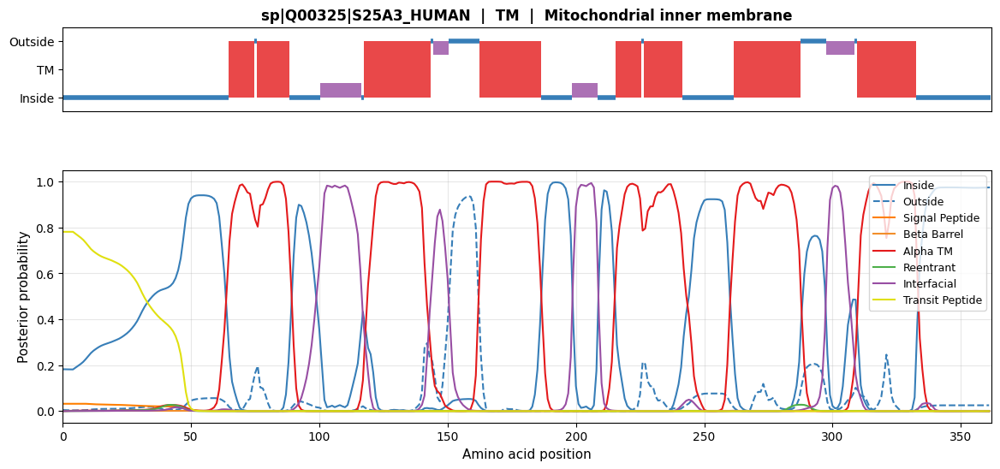

In [7]:
COLORS = {
    'inside':      '#377eb8',
    'outside':     '#377eb8',   # same blue, distinguished by linestyle
    'signal':      '#ff7f00',
    'alpha':       '#e41a1c',
    'beta':        '#f28e2b',
    'reentrant':   '#4daf4a',
    'interfacial': '#984ea3',
    'transit':     '#e0e010',
}

def plot_inline(seq_id, sequence, topology_ab, mem_names, marginals):
    fig = plt.figure(figsize=(14, 6))
    gs  = gridspec.GridSpec(2, 1, height_ratios=[1, 3], hspace=0.35)
    x   = np.arange(len(sequence))

    label_map = {'a': 0, 'b': 1, 'S': 3, 'M': 4, 'B': 5, 'R': 7, 'F': 6, '>': 3}
    lab_y = np.array([label_map.get(c, -1) for c in topology_ab])

    prot_types = []
    if 3 in lab_y: prot_types.append("SP")
    if 5 in lab_y: prot_types.append("BETA")
    if 4 in lab_y: prot_types.append("TM")
    prot_type_str = "+".join(prot_types) if prot_types else "Globular"
    is_transit = topology_ab.startswith('>')
    sp_label   = "Transit" if is_transit else "Signal"

    # --- Track 1: topology compartment ---
    ax0 = fig.add_subplot(gs[0])
    for k, g in groupby(enumerate(lab_y), lambda x: x[1]):
        seg   = list(g)
        xs    = [seg[0][0] - 0.5, seg[-1][0] + 0.5]
        start = seg[0][0]
        if k == 0:
            ax0.plot(xs, [0, 0], color=COLORS['inside'],  linewidth=4, solid_capstyle='butt')
        elif k == 1:
            ax0.plot(xs, [2, 2], color=COLORS['outside'], linewidth=4, solid_capstyle='butt')
        elif k == 3:
            ax0.plot(xs, [1, 1], color=COLORS['signal'],  linewidth=4, solid_capstyle='butt')
        elif k == 4:
            ax0.fill_between(xs, [0,0], [2,2], color=COLORS['alpha'],  alpha=0.8, linewidth=0)
        elif k == 5:
            ax0.fill_between(xs, [0,0], [2,2], color=COLORS['beta'],   alpha=0.8, linewidth=0)
        elif k == 7:
            prev = lab_y[start - 1] if start > 0 else 0
            yb, yt = (1, 2) if prev == 1 else (0, 1)
            ax0.fill_between(xs, [yb,yb], [yt,yt], color=COLORS['reentrant'],   alpha=0.8, linewidth=0)
        elif k == 6:
            prev = lab_y[start - 1] if start > 0 else 0
            yb, yt = (1.5, 2) if prev == 1 else (0, 0.5)
            ax0.fill_between(xs, [yb,yb], [yt,yt], color=COLORS['interfacial'], alpha=0.8, linewidth=0)

    if "BETA" in prot_type_str:
        ax0.set_yticks([0, 1, 2], ['Inside', 'Beta Barrel', 'Outside'])
    elif "SP" in prot_type_str and "TM" in prot_type_str:
        ax0.set_yticks([0, 1, 2], ['Inside', f'{sp_label}/TM', 'Outside'])
    elif "SP" in prot_type_str:
        ax0.set_yticks([0, 1, 2], ['Inside', sp_label, 'Outside'])
    elif "TM" in prot_type_str:
        ax0.set_yticks([0, 1, 2], ['Inside', 'TM', 'Outside'])
    else:
        ax0.set_yticks([0, 2], ['Inside', 'Outside'])

    ax0.set_xlim(0, len(sequence))
    ax0.set_ylim(-0.5, 2.5)
    ax0.set_title(
        f"{seq_id}  |  {prot_type_str}  |  {', '.join(mem_names)}",
        fontsize=12, fontweight='bold'
    )
    ax0.tick_params(bottom=False, labelbottom=False)

    # --- Track 2: posterior probabilities ---
    ax1 = fig.add_subplot(gs[1])

    # key 0 = Inside (solid), key 1 = Outside (dashed) if present; else merged I/O (solid)
    has_split_io = 1 in marginals
    cat_meta = {
        0: ('Inside',         COLORS['inside'],      '-'),
        1: ('Outside',        COLORS['outside'],     '--'),
        2: ('Signal Peptide', COLORS['signal'],      '-'),
        3: ('Beta Barrel',    COLORS['beta'],        '-'),
        4: ('Alpha TM',       COLORS['alpha'],       '-'),
        5: ('Reentrant',      COLORS['reentrant'],   '-'),
        6: ('Interfacial',    COLORS['interfacial'], '-'),
        7: ('Transit Peptide',COLORS['transit'],     '-'),
    }
    if not has_split_io:
        cat_meta[0] = ('Inside/Outside', COLORS['inside'], '-')

    for cat_idx, probs in marginals.items():
        if cat_idx in cat_meta:
            label, color, ls = cat_meta[cat_idx]
            ax1.plot(x, probs, label=label, color=color, linewidth=1.5, linestyle=ls)

    ax1.set_xlim(0, len(sequence))
    ax1.set_ylim(-0.05, 1.05)
    ax1.set_xlabel("Amino acid position", fontsize=11)
    ax1.set_ylabel("Posterior probability", fontsize=11)
    ax1.legend(loc='upper right', frameon=True, fontsize=9)
    ax1.grid(alpha=0.3)

    plt.show()

plot_inline(seq_id, sequence, final_topo_ab, mem_names, final_marginals_split)

## Posterior vs. Viterbi discrepancy

The marginal probabilities sum over **all** valid CRF paths, while Viterbi gives the single globally optimal path. They can disagree: a region where many alternative paths pass through "Transit Peptide" can show high marginal probability for that label even though the Viterbi path chose "Inside".

/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/844468216.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


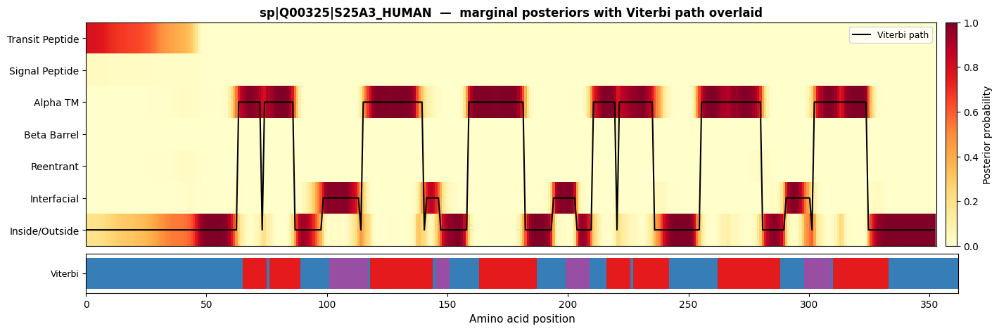

In [8]:
import matplotlib.patches as mpatches

CHAR_TO_CAT = {'a': 0, 'b': 0, 'S': 2, 'M': 4, 'B': 3, 'R': 5, 'F': 6, '>': 7}
VCAT_COLORS = {
    0: COLORS['inside'], 2: COLORS['signal'], 4: COLORS['alpha'],
    3: COLORS['beta'],   5: COLORS['reentrant'], 6: COLORS['interfacial'], 7: COLORS['transit'],
}
CAT_ORDER  = [7, 2, 4, 3, 5, 6, 0]
CAT_LABELS = {
    0: 'Inside/Outside', 2: 'Signal Peptide', 3: 'Beta Barrel',
    4: 'Alpha TM', 5: 'Reentrant', 6: 'Interfacial', 7: 'Transit Peptide',
}
cat_to_row = {cat: i for i, cat in enumerate(CAT_ORDER)}

L = len(sequence)
prob_matrix = np.zeros((len(CAT_ORDER), L))
for row_i, cat in enumerate(CAT_ORDER):
    if cat in final_marginals:
        prob_matrix[row_i] = final_marginals[cat]

viterbi_row = np.array([cat_to_row[CHAR_TO_CAT.get(c, 0)] for c in final_topo_ab], dtype=float)

fig, (ax_heat, ax_v) = plt.subplots(
    2, 1, figsize=(16, 5),
    gridspec_kw={'height_ratios': [4, 0.7], 'hspace': 0.06},
)

im = ax_heat.imshow(prob_matrix, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1, origin='upper')
ax_heat.plot(np.arange(L), viterbi_row, color='black', linewidth=1.5, label='Viterbi path', zorder=5)
ax_heat.set_yticks(range(len(CAT_ORDER)))
ax_heat.set_yticklabels([CAT_LABELS[c] for c in CAT_ORDER], fontsize=10)
ax_heat.set_xlim(0, L)
ax_heat.tick_params(bottom=False, labelbottom=False)
ax_heat.set_title(f'{seq_id}  —  marginal posteriors with Viterbi path overlaid', fontweight='bold', fontsize=12)
ax_heat.legend(loc='upper right', fontsize=9)
plt.colorbar(im, ax=ax_heat, fraction=0.015, pad=0.01, label='Posterior probability')

for k, g in groupby(enumerate(final_topo_ab), lambda x: x[1]):
    seg = list(g)
    ax_v.barh(0, seg[-1][0] - seg[0][0] + 1, left=seg[0][0], height=0.8,
              color=VCAT_COLORS[CHAR_TO_CAT.get(k, 0)], linewidth=0)
ax_v.set_xlim(0, L)
ax_v.set_ylim(-0.5, 0.5)
ax_v.set_yticks([0])
ax_v.set_yticklabels(['Viterbi'], fontsize=9)
ax_v.set_xlabel('Amino acid position', fontsize=11)

plt.tight_layout()
plt.show()

## Ensemble member predictions

Each of the 5 ensemble members runs an independent Viterbi decode. The consensus is whichever topology has the most agreement (not an average). Rows where models disagree reveal structurally ambiguous regions.

/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/831671721.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


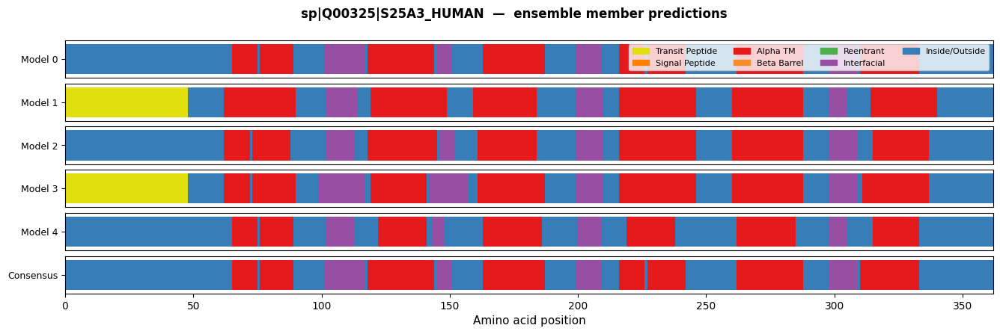

In [9]:
n = len(all_topo)
fig, axes = plt.subplots(
    n + 1, 1, figsize=(16, 0.6 * (n + 1) + 0.8),
    gridspec_kw={'hspace': 0.15},
)

for ei, topo in enumerate(all_topo + [final_topo_ab]):
    ax = axes[ei]
    for k, g in groupby(enumerate(topo), lambda x: x[1]):
        seg = list(g)
        ax.barh(0, seg[-1][0] - seg[0][0] + 1, left=seg[0][0], height=0.8,
                color=VCAT_COLORS[CHAR_TO_CAT.get(k, 0)], linewidth=0)
    ax.set_xlim(0, L)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([0])
    ax.set_yticklabels(['Consensus' if ei == n else f'Model {ei}'], fontsize=9)
    ax.tick_params(bottom=(ei == n), labelbottom=(ei == n))
    if ei == n:
        ax.set_xlabel('Amino acid position', fontsize=11)

legend_patches = [
    mpatches.Patch(color=COLORS[k], label=v)
    for k, v in [
        ('transit', 'Transit Peptide'), ('signal', 'Signal Peptide'),
        ('alpha', 'Alpha TM'), ('beta', 'Beta Barrel'),
        ('reentrant', 'Reentrant'), ('interfacial', 'Interfacial'),
        ('inside', 'Inside/Outside'),
    ]
]
axes[0].legend(handles=legend_patches, loc='upper right', ncol=4, fontsize=8, frameon=True)
fig.suptitle(f'{seq_id}  —  ensemble member predictions', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

## TM segment merging candidates

The CRF grammar requires a minimum TM helix length of 10 and at least one inside/outside residue between segments, which can force two nearby helices to be split even when the sequence evidence is continuous. Annotated values show the mean Alpha TM marginal probability in each inter-helix loop — high values indicate merge candidates.

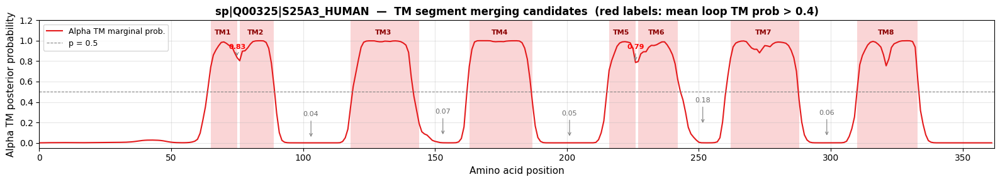

  Loop       Positions  Length  Mean TM prob  Merge?
-------------------------------------------------------
TM1-TM2      76–76           1         0.835     YES
TM2-TM3      90–118         29         0.041      no
TM3-TM4     145–163         19         0.065      no
TM4-TM5     188–216         29         0.049      no
TM5-TM6     227–227          1         0.787     YES
TM6-TM7     243–262         20         0.177      no
TM7-TM8     289–310         22         0.055      no


In [10]:
# Identify TM segments and the loops between them
tm_segs = []
for label, g in groupby(enumerate(final_topo_ab), lambda x: x[1]):
    seg = list(g)
    if label == 'M':
        tm_segs.append((seg[0][0], seg[-1][0]))

tm_prob = final_marginals.get(4, np.zeros(L))

fig, ax = plt.subplots(figsize=(16, 3))
x = np.arange(L)
ax.plot(x, tm_prob, color=COLORS['alpha'], linewidth=1.5, label='Alpha TM marginal prob.')

# Shade Viterbi TM segments and label them
for i, (s, e) in enumerate(tm_segs):
    ax.axvspan(s, e + 1, alpha=0.18, color=COLORS['alpha'], linewidth=0)
    ax.text((s + e) / 2, 1.05, f'TM{i+1}', ha='center', va='bottom',
            fontsize=8, fontweight='bold', color='darkred')

# Annotate inter-segment loops with mean TM probability
for i in range(len(tm_segs) - 1):
    loop_s = tm_segs[i][1] + 1
    loop_e = tm_segs[i + 1][0] - 1
    if loop_e < loop_s:
        continue
    mean_p = tm_prob[loop_s:loop_e + 1].mean()
    mid    = (loop_s + loop_e) / 2
    color  = 'red' if mean_p > 0.4 else 'dimgray'
    ax.annotate(
        f'{mean_p:.2f}',
        xy=(mid, mean_p), xytext=(mid, min(mean_p + 0.22, 0.92)),
        ha='center', fontsize=8, color=color, fontweight=('bold' if mean_p > 0.4 else 'normal'),
        arrowprops=dict(arrowstyle='->', color='gray', lw=0.8),
    )

ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, label='p = 0.5')
ax.set_xlim(0, L)
ax.set_ylim(-0.05, 1.2)
ax.set_xlabel('Amino acid position', fontsize=11)
ax.set_ylabel('Alpha TM posterior probability', fontsize=11)
ax.set_title(f'{seq_id}  —  TM segment merging candidates  (red labels: mean loop TM prob > 0.4)',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print a summary table
print(f"{'Loop':>6}  {'Positions':>14}  {'Length':>6}  {'Mean TM prob':>12}  {'Merge?':>6}")
print('-' * 55)
for i in range(len(tm_segs) - 1):
    loop_s = tm_segs[i][1] + 1
    loop_e = tm_segs[i + 1][0] - 1
    length = loop_e - loop_s + 1
    mean_p = tm_prob[loop_s:loop_e + 1].mean() if length > 0 else 0.0
    print(f"TM{i+1}-TM{i+2}  {loop_s+1:>6}–{loop_e+1:<6}  {length:>6}  {mean_p:>12.3f}  {'YES' if mean_p > 0.4 else 'no':>6}")

## Log-likelihoods: Viterbi vs. max-marginal sequence

For each of the 5 models we compute the CRF conditional log-likelihood `log P(y | x)` for two label sequences:
- **Viterbi**: the globally optimal path (maximises the joint path score, guaranteed to be ≥ any other valid path).
- **Max marginal**: at each position independently take the CRF state with the highest marginal probability, then score the resulting sequence. This path can violate CRF transition constraints, in which case it will receive a score of −∞.

In [11]:
import pandas as pd

rows = []
with torch.no_grad():
    for i, model in enumerate(models.topology_models):

        # ── Neural network emissions ──────────────────────────────────────────
        emissions = model._get_network_emissions(embedding, mask)
        # shape: (1, seq_len, num_crf_states)  [batch_first=True]

        # ── Viterbi path ──────────────────────────────────────────────────────
        raw_paths   = model.crf.decode(emissions, mask.byte())   # List[List[int]]
        vit_tags    = torch.tensor(raw_paths, device=DEVICE)     # (1, seq_len)
        ll_viterbi  = model.crf(emissions, tags=vit_tags, mask=mask.byte(), reduction='none').item()

        vit_simple  = model.crf_config.convert_crf_states_to_labels(vit_tags[0].cpu().numpy())
        vit_topo    = model.crf_config.get_string_from_labels(vit_simple)

        # ── Max-marginal path ─────────────────────────────────────────────────
        # Raw CRF marginals: (1, seq_len, num_crf_states)
        raw_marg = model.crf.compute_marginal_probabilities(emissions, mask, truncate=False)
        mm_tags  = raw_marg[0].argmax(dim=-1).unsqueeze(0)       # (1, seq_len)
        ll_mm    = model.crf(emissions, tags=mm_tags, mask=mask.byte(), reduction='none').item()

        mm_simple = model.crf_config.convert_crf_states_to_labels(mm_tags[0].cpu().numpy())
        mm_topo   = model.crf_config.get_string_from_labels(mm_simple)

        rows.append({
            'Model':              i,
            'LL Viterbi':         ll_viterbi,
            'LL/tok Viterbi':     ll_viterbi / len(sequence),
            'LL Max-Marginal':    ll_mm,
            'LL/tok Max-Marginal':ll_mm / len(sequence),
            'Δ (MM − Vit)':       ll_mm - ll_viterbi,
            'Viterbi topology':   vit_topo,
            'Max-marginal topology': mm_topo,
        })

df = pd.DataFrame(rows)

# Summary table (numeric columns only)
print(df[['Model','LL Viterbi','LL/tok Viterbi','LL Max-Marginal','LL/tok Max-Marginal','Δ (MM − Vit)']].to_string(index=False))

# Show topology strings separately (they are long)
print()
for _, row in df.iterrows():
    print(f"Model {int(row['Model'])}")
    print(f"  Viterbi:     {row['Viterbi topology']}")
    print(f"  Max-marginal:{row['Max-marginal topology']}")
    print()

 Model  LL Viterbi  LL/tok Viterbi  LL Max-Marginal  LL/tok Max-Marginal  Δ (MM − Vit)
     0  -32.335510       -0.089325    -2.500000e+15        -6.906078e+12 -2.500000e+15
     1  -24.429932       -0.067486    -1.400000e+15        -3.867403e+12 -1.400000e+15
     2  -26.491547       -0.073181    -2.100000e+15        -5.801105e+12 -2.100000e+15
     3  -32.179230       -0.088893    -2.200000e+15        -6.077348e+12 -2.200000e+15
     4  -30.895233       -0.085346    -1.600000e+15        -4.419890e+12 -1.600000e+15

Model 0
  Viterbi:     aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFFFFFFFaMMMMMMMMMMMMMMMMMMMMMMMMMMbFFFFFFbbbbbbbbbbbbMMMMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMMMMMMMMMMMMMMMbbbbbbbbbbFFFFFFFFFFFbMMMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaaaaaa
  Max-marginal:>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMM

## Transit-peptide transition scores

CRF transition weights are unnormalised log potentials — more negative = less likely. We extract four key values per model:
- **start → transit**: how the model weighs beginning the sequence with a transit peptide
- **start → inside**: how the model weighs beginning with inside directly
- **transit → inside**: the score for ending the transit peptide and landing on the inside (a)
- **transit → outside**: the score for ending the transit peptide and landing on the outside (b)

In [12]:
import pandas as pd

# All models share the same CRF config / state layout
cfg = models.topology_models[0].crf_config

# Last transit-peptide CRF state (the self-looping state; can exit to a or b)
max_tp = max(cfg.max_segment_lengths[">"], cfg.min_segment_lengths[">"])  # max(-1,5)=5
last_tp_idx  = cfg.crf_states[">" + str(max_tp - 1)]   # ">4"
tp_start_idx = cfg.crf_states[">0"]
a_idx        = cfg.crf_states["a_alpha"]   # inside
b_idx        = cfg.crf_states["b_alpha"]   # outside

print(f"State indices:  >0={tp_start_idx}  >{max_tp-1}(last)={last_tp_idx}  a_alpha={a_idx}  b_alpha={b_idx}")
print()

rows = []
for i, model in enumerate(models.topology_models):
    start = model.crf.start_transitions.data
    trans = model.crf.transitions.data
    rows.append({
        'Model':                  i,
        'start → transit (>0)':   start[tp_start_idx].item(),
        'start → inside  (a)':    start[a_idx].item(),
        'transit → inside  (a)':  trans[last_tp_idx, a_idx].item(),
        'transit → outside (b)':  trans[last_tp_idx, b_idx].item(),
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))

State indices:  >0=14  >4(last)=18  a_alpha=0  b_alpha=1

 Model  start → transit (>0)  start → inside  (a)  transit → inside  (a)  transit → outside (b)
     0             -0.085481             0.087552              -0.025240              -0.042707
     1             -0.084275             0.087065              -0.023815              -0.040544
     2             -0.083673             0.085751              -0.023367              -0.040079
     3             -0.082469             0.081316              -0.020450              -0.042414
     4             -0.082738             0.084963              -0.019895              -0.043503


## Temperature scaling

Multiplying emission scores by `T > 1` before the CRF amplifies differences between labels at each position, sharpening the posterior. `T = 1` is the original model. We run this on model 4 (fuzzy transit peptide) and model 1 (sharper transit peptide) across a range of temperatures.

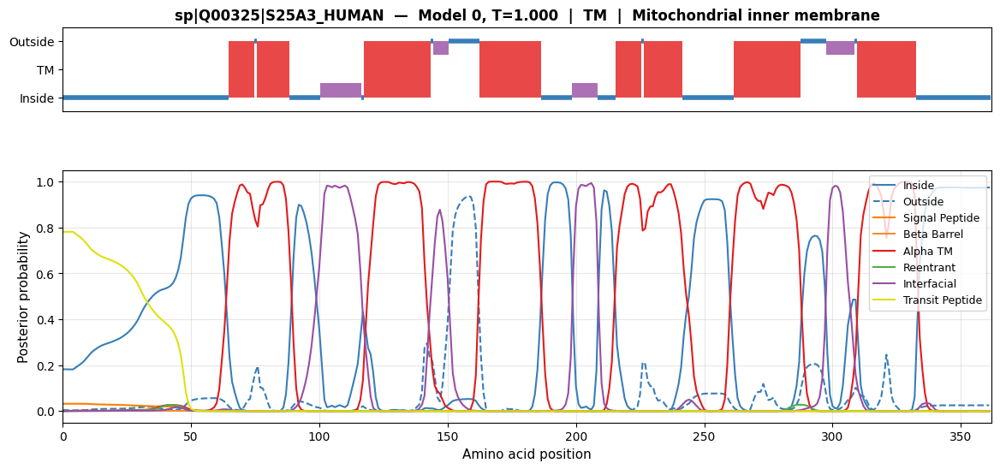

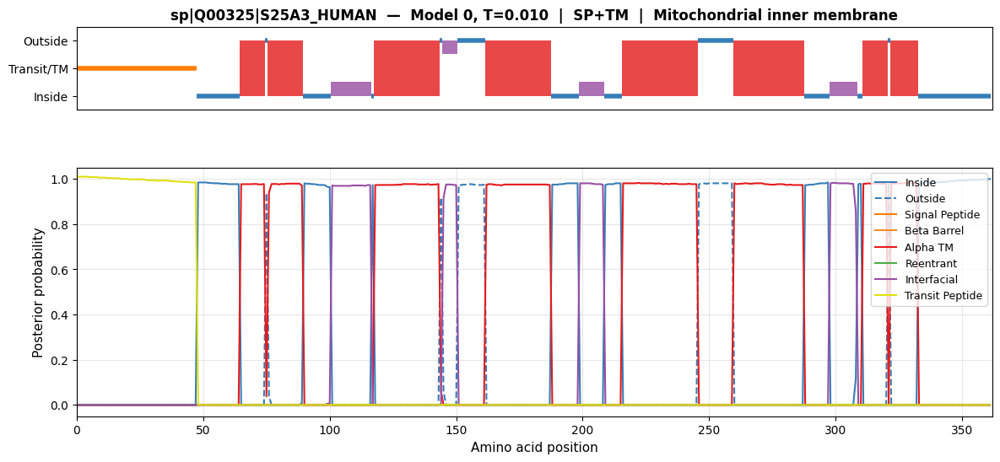

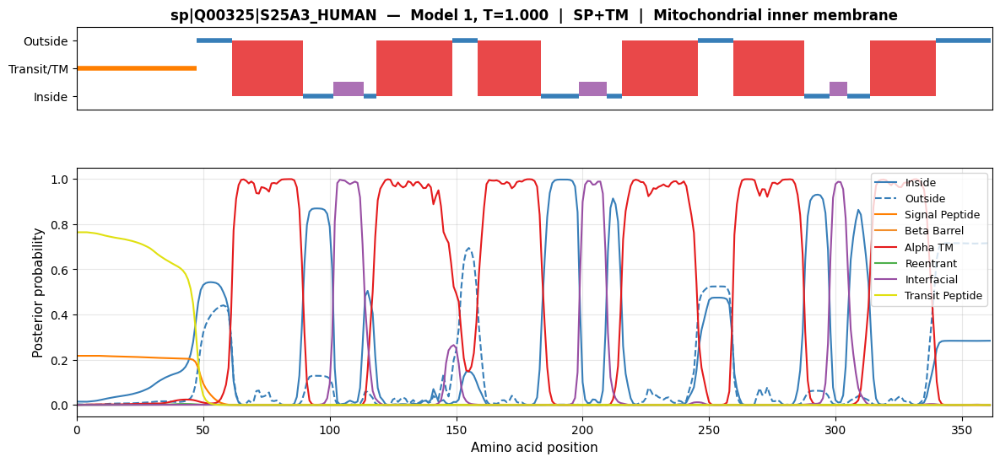

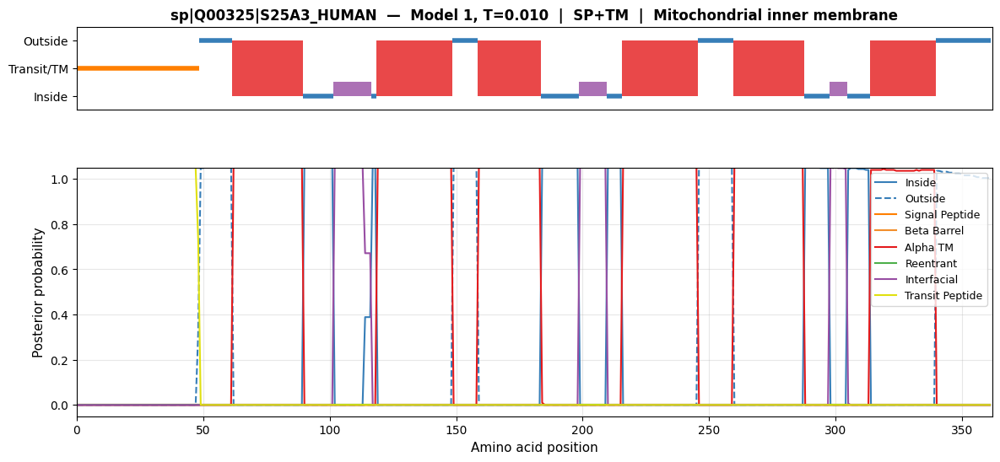

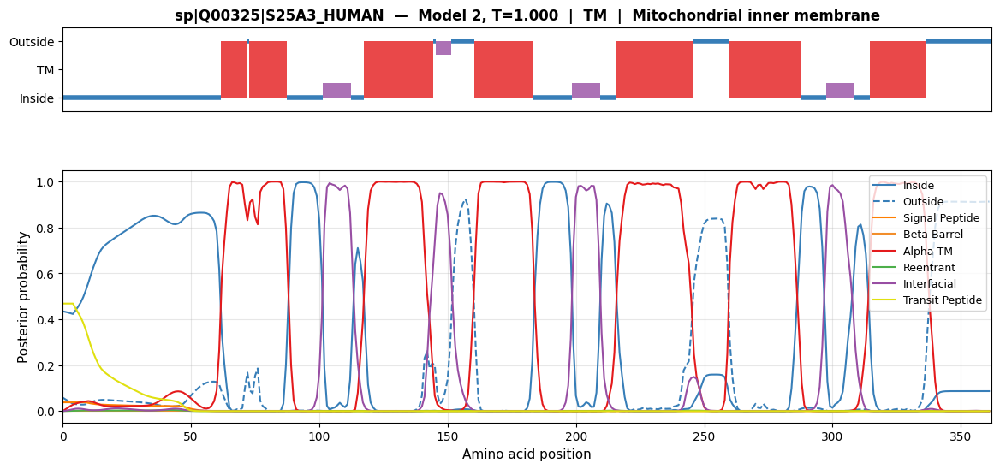

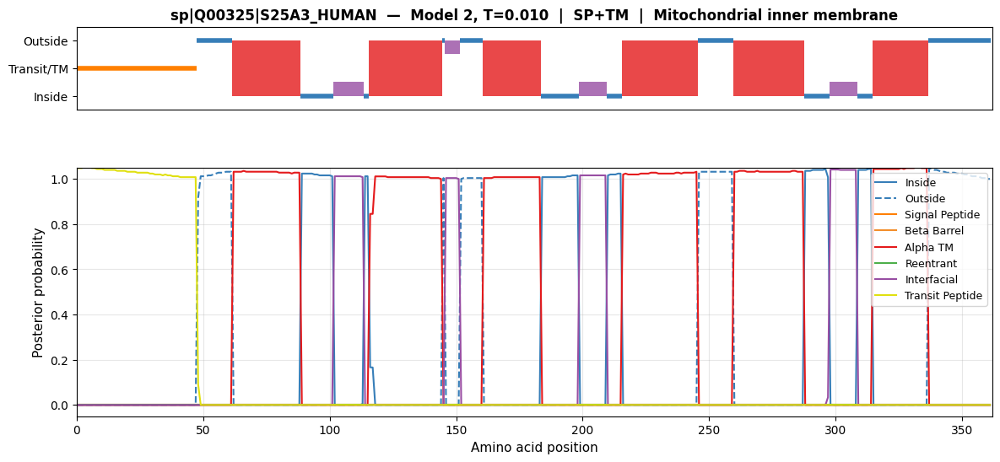

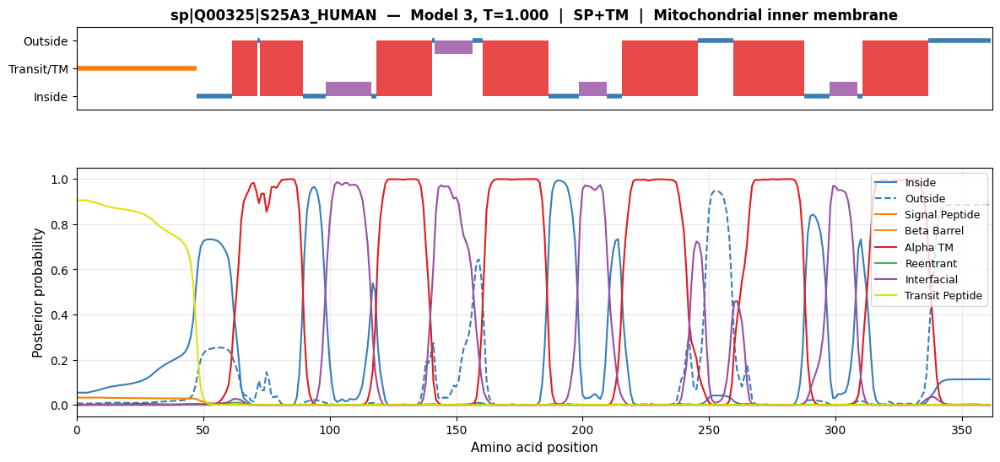

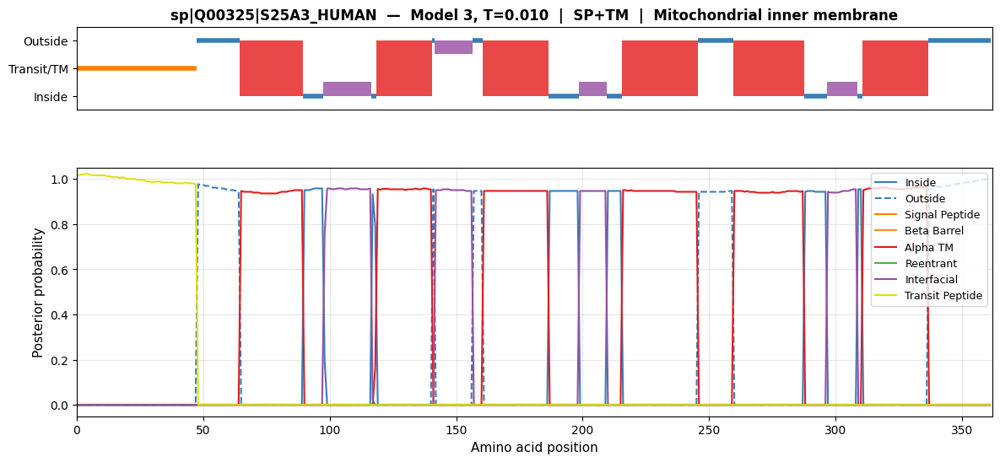

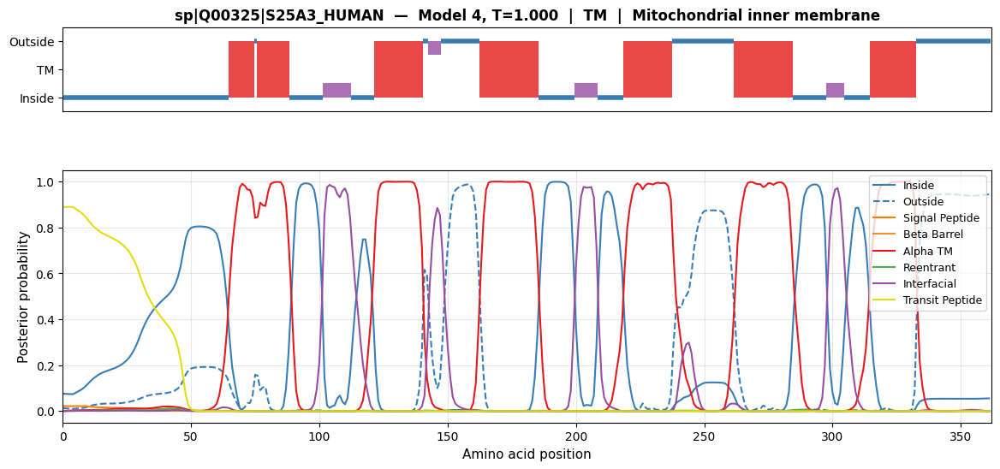

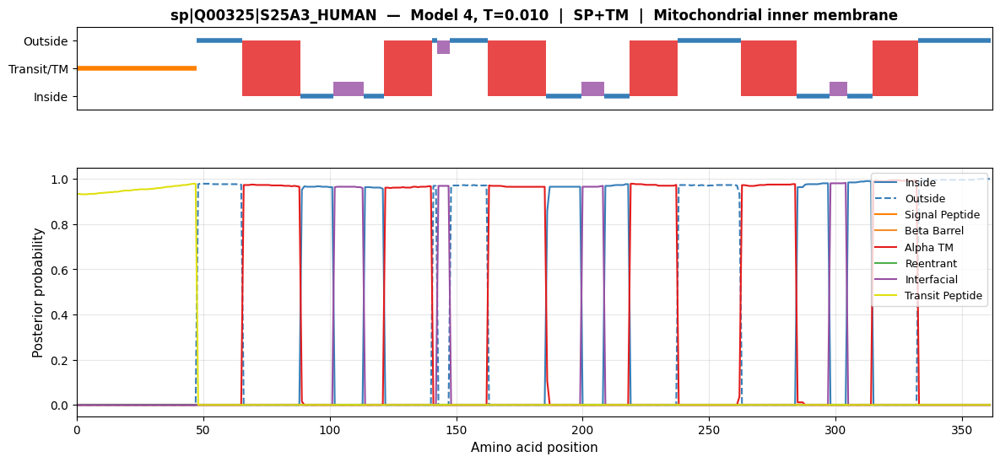

In [13]:
temperatures = [1,1/100]  # < 1 sharpens

with torch.no_grad():
    for model_idx in [0, 1, 2, 3, 4]:
        model = models.topology_models[model_idx]
        emissions = model._get_network_emissions(embedding, mask)

        for T in temperatures:
            scaled = emissions / T

            # Viterbi on scaled emissions
            raw_paths  = model.crf.decode(scaled, mask.byte())
            vit_simple = model.crf_config.convert_crf_states_to_labels(
                             torch.tensor(raw_paths[0]).numpy())
            vit_topo   = model.crf_config.get_string_from_labels(vit_simple)

            # Marginals on scaled emissions
            raw_marg   = model.crf.compute_marginal_probabilities(scaled, mask, truncate=False)
            split_marg = simplify_marginals_split_io(model.crf_config, raw_marg[0])

            plot_inline(f"{seq_id}  —  Model {model_idx}, T={T:.3f}",
                        sequence, vit_topo, mem_names, split_marg)

## Per-model posterior probability plots

The max-marginal sequences above are all CRF-invalid (LL ~−10¹⁵), because the raw-CRF-state argmax produces forbidden transitions (e.g. transit peptide → inside without going through an allowed end state). Plotting each model's posteriors individually shows where each model places its probability mass and why the argmax path breaks the grammar.

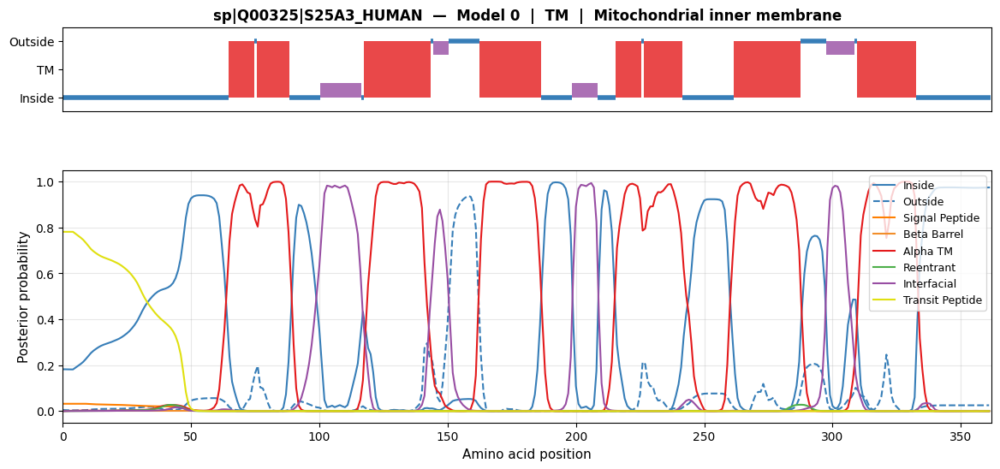

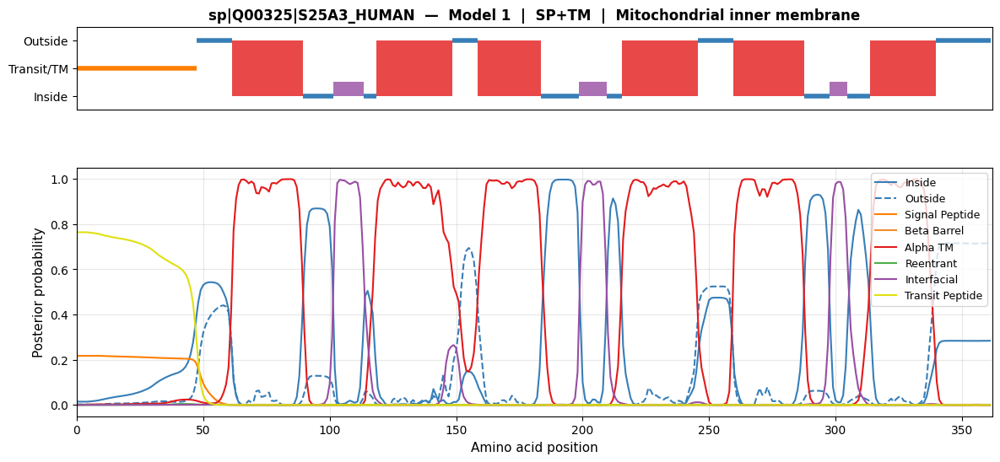

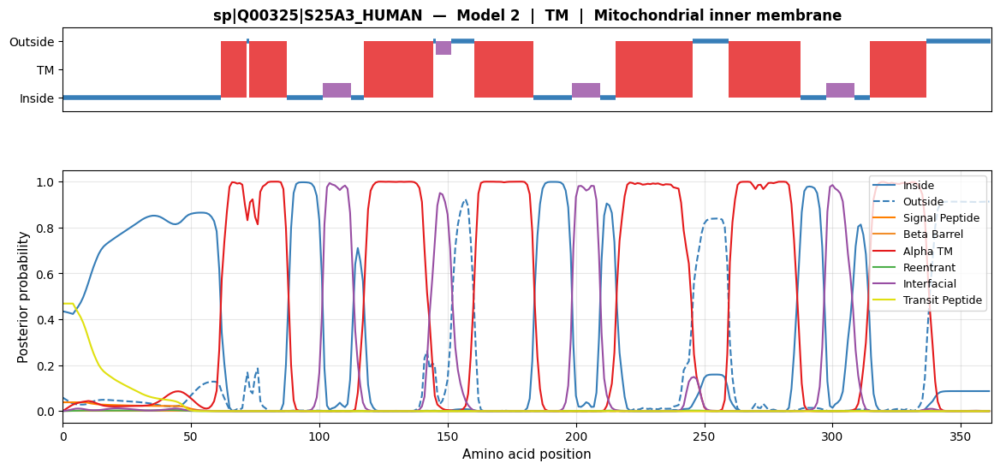

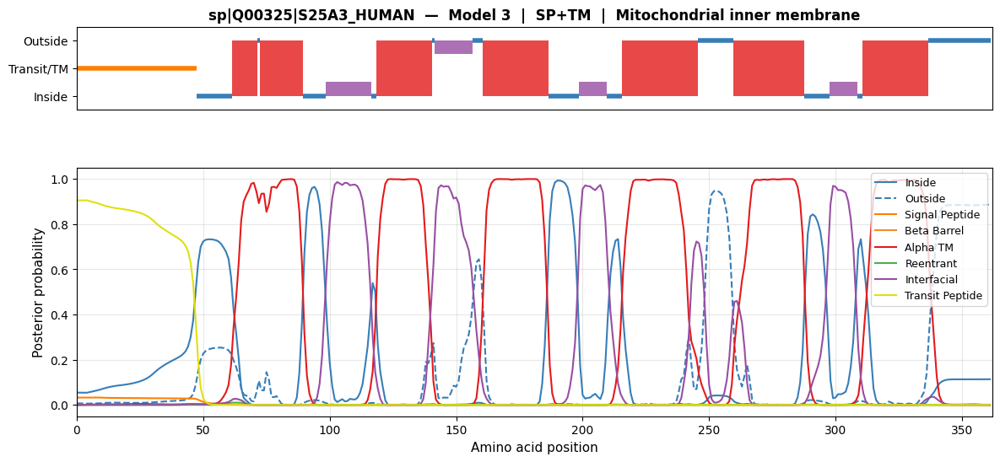

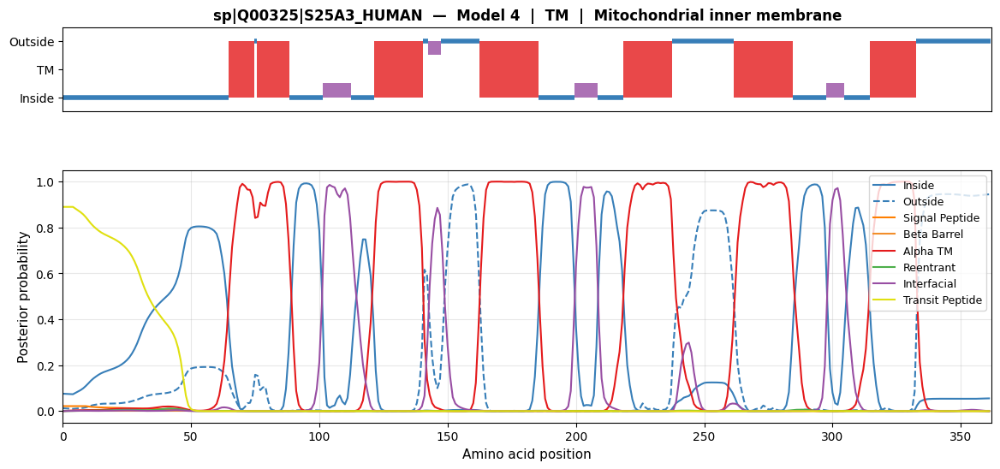

In [14]:


for i, (topo, marg) in enumerate(zip(all_topo, all_marginals_split)):
    plot_inline(f"{seq_id}  —  Model {i}", sequence, topo, mem_names, marg)

## Forward filtering + backward sampling

Instead of a single Viterbi path, we draw **N posterior samples** from the CRF using the
forward-filtering / backward-sampling algorithm:

1. Run the forward pass to get log-alphas: `α[t,j] = log p(o₁…ₜ, sₜ=j)`
2. Sample the last state: `p(s_T | o) ∝ exp(α[T,j] + end_transition[j])`
3. Sample each earlier state: `p(sₜ=j | sₜ₊₁=k, o) ∝ exp(α[t,j] + A[j,k])`

All samples are CRF-valid by construction (the grammar constraints live in the
transition scores). We then:

- Classify each sample by topology type (`infer_structural_type`).
- Vote: pick the **winning topology class**.
- Use the sample from the winning class that has the highest CRF log-likelihood
  as the final prediction.


In [15]:
import importlib, types
import deeptmhmm2_predictor.model.crf as _crf_mod
import deeptmhmm2_predictor.model.container as _container_mod
importlib.reload(_crf_mod)
importlib.reload(_container_mod)

from deeptmhmm2_predictor.utils.postprocessing import infer_structural_type
from collections import Counter

# Monkey-patch new method onto existing CRF instances (avoids full kernel restart)
for _m in models.topology_models:
    _m.crf.sample_from_posterior = types.MethodType(
        _crf_mod.CRF.sample_from_posterior, _m.crf
    )

# Monkey-patch predict_posterior_samples onto the models container
models.predict_posterior_samples = types.MethodType(
    _container_mod.ModelContainer.predict_posterior_samples, models
)

N_SAMPLES = 200  # posterior draws per model
print("Patched CRF and ModelContainer — ready for posterior sampling.")


Patched CRF and ModelContainer — ready for posterior sampling.


In [16]:
from itertools import groupby
from deeptmhmm2_predictor.utils.postprocessing import convert_to_segments, is_topologies_equal

def group_by_topology(topology_strings):
    """Cluster topology strings into equivalence classes using is_topologies_equal."""
    segments = [convert_to_segments(t) for t in topology_strings]
    groups = []  # list of (representative_segments, [indices])
    for i, segs in enumerate(segments):
        placed = False
        for rep_segs, indices in groups:
            if is_topologies_equal(rep_segs, segs):
                indices.append(i)
                placed = True
                break
        if not placed:
            groups.append((segs, [i]))
    groups.sort(key=lambda g: len(g[1]), reverse=True)
    return groups


def describe_group(topo_str):
    """Return a (type, seg_label) tuple, e.g. ('M+T', '6TM')."""
    stype = infer_structural_type(topo_str)
    segs  = convert_to_segments(topo_str)
    n_tm   = sum(1 for lbl, _, _ in segs if lbl == 'M')
    n_beta = sum(1 for lbl, _, _ in segs if lbl == 'B')
    if n_tm > 0:
        seg_str = f"{n_tm}TM"
    elif n_beta > 0:
        seg_str = f"{n_beta}B"
    else:
        seg_str = "-"
    return stype, seg_str


def posterior_sample_predict(models, model_idx, embedding, mask, n_samples=N_SAMPLES, temperature=1.0):
    """Draw posterior samples; return best representative from the winning topology equivalence class.

    Returns: best_topo, winning_type, vote_summary, vote_fraction, topology_strings
    """
    topology_strings, raw_paths, emissions = models.predict_posterior_samples(
        model_idx, embedding, mask, n_samples=n_samples, temperature=temperature
    )

    groups = group_by_topology(topology_strings)
    winning_indices = groups[0][1]
    vote_fraction = len(winning_indices) / n_samples

    # Summarise vote distribution (top-5 groups): (type, segments, count)
    vote_summary = [
        (*describe_group(topology_strings[g[1][0]]), len(g[1]))
        for g in groups[:5]
    ]

    # Score each winner sample under the CRF; pick the highest
    top_model = models.topology_models[model_idx]
    best_topo, best_score = None, float('-inf')
    for i in winning_indices:
        tags = torch.tensor([raw_paths[i]], device=emissions.device)
        with torch.no_grad():
            ll = top_model.crf(emissions, tags=tags, mask=mask.byte(), reduction='none').item()
        if ll > best_score:
            best_score = ll
            best_topo = topology_strings[i]

    winning_type = infer_structural_type(best_topo)
    return best_topo, winning_type, vote_summary, vote_fraction, topology_strings


# --- Run on all ensemble models (temperature=1.0) ---
print(f"Drawing {N_SAMPLES} posterior samples per model (T=1.0)...")
sampled_results = []
all_sample_strings = []   # all topology strings per model — used by raster plot cell
for model_idx in range(len(models.topology_models)):
    best_topo, winning_type, vote_summary, fraction, topo_strings = posterior_sample_predict(
        models, model_idx, embedding, mask, temperature=1.0
    )
    viterbi_type = infer_structural_type(all_topo[model_idx])
    sampled_results.append((best_topo, winning_type, vote_summary, fraction))
    all_sample_strings.append(topo_strings)
    print(f"Model {model_idx}:")
    print(f"  Viterbi : {viterbi_type}")
    print(f"  Sampled : {winning_type}  ({fraction:.0%} of samples)")
    print(f"  Top groups (type, segs, count): {vote_summary}")
    print(f"  Best    : {best_topo[:80]}...")
    print()


Drawing 200 posterior samples per model (T=1.0)...
Model 0:
  Viterbi : M
  Sampled : M+T  (8% of samples)
  Top groups (type, segs, count): [('M+T', '10TM', 15), ('M+T', '10TM', 7), ('M+T', '10TM', 6), ('M+T', '10TM', 5), ('M+T', '10TM', 5)]
  Best    : >>>>>>>>>>>>>>>>>>>>>>>>>>>>>aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMMMb...

Model 1:
  Viterbi : M+T
  Sampled : M+S  (6% of samples)
  Top groups (type, segs, count): [('M+S', '6TM', 11), ('M+T', '9TM', 7), ('M+T', '7TM', 6), ('M+T', '9TM', 6), ('M+T', '8TM', 5)]
  Best    : SSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSbbbbbbMMMMMMMMMMMMMMMMMMMM...

Model 2:
  Viterbi : M
  Sampled : M+T  (10% of samples)
  Top groups (type, segs, count): [('M+T', '7TM', 20), ('M', '7TM', 13), ('M', '9TM', 9), ('M', '7TM', 7), ('M+T', '9TM', 5)]
  Best    : >>>>>>>>>>>>>>>>>>>>>>>aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMbMMMMMM...

Model 3:
  Viterbi : M+T
  Sampled : M+T  (3% of samples)
  Top groups (type, segs, count): [(

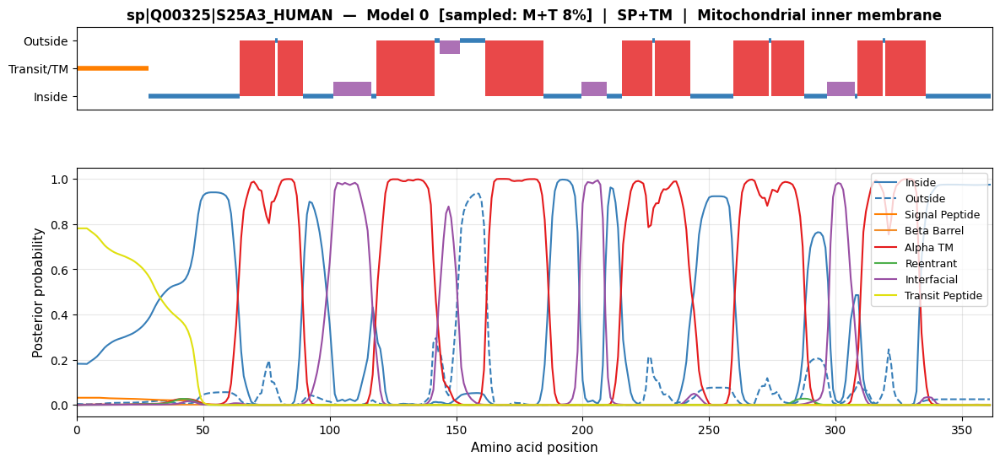

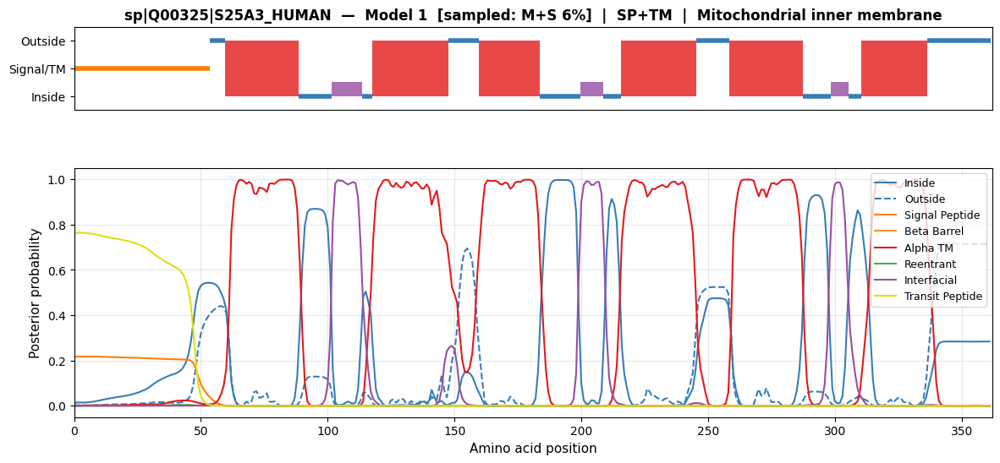

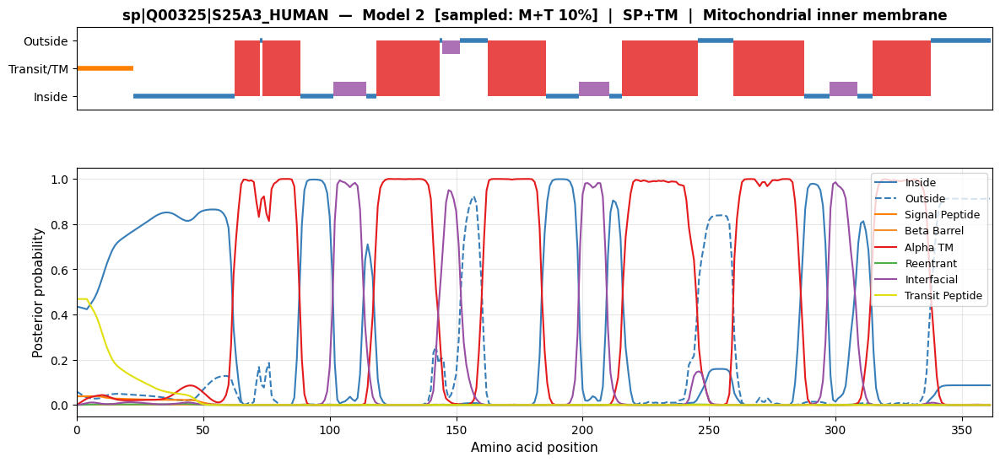

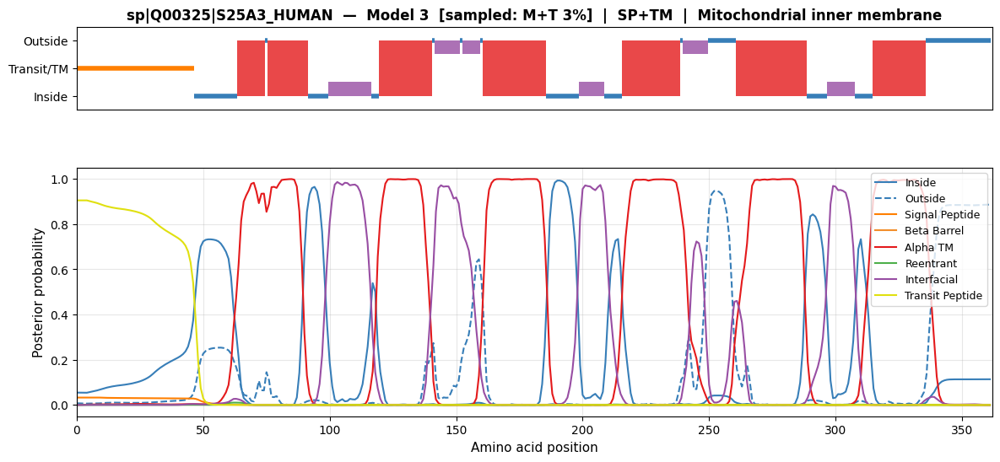

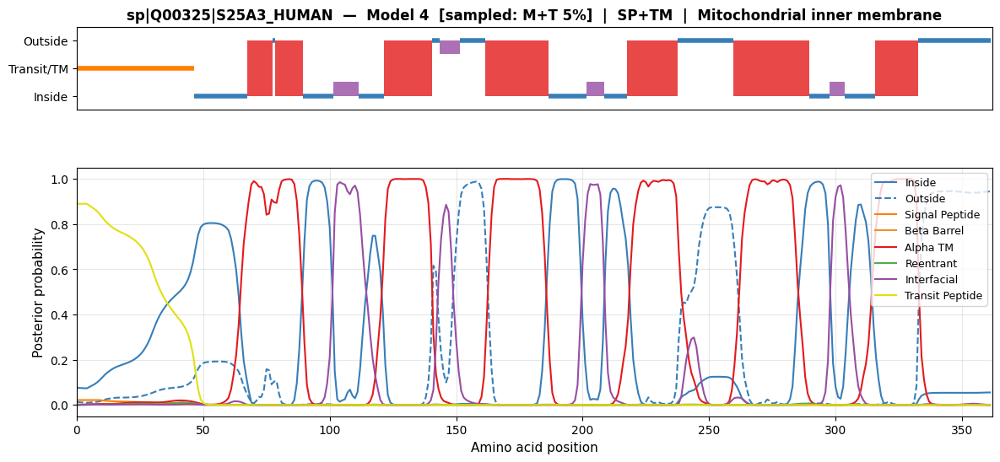

In [17]:
# --- Visualize posterior-sampled predictions for each model ---
# Uses the same marginal posteriors as before but shows the sampled topology path
for model_idx, (best_topo, winning_type, vote_counts, fraction) in enumerate(sampled_results):
    title = (
        f"{seq_id}  —  Model {model_idx}  [sampled: {winning_type} {fraction:.0%}]"
    )
    plot_inline(title, sequence, best_topo, mem_names, all_marginals_split[model_idx])


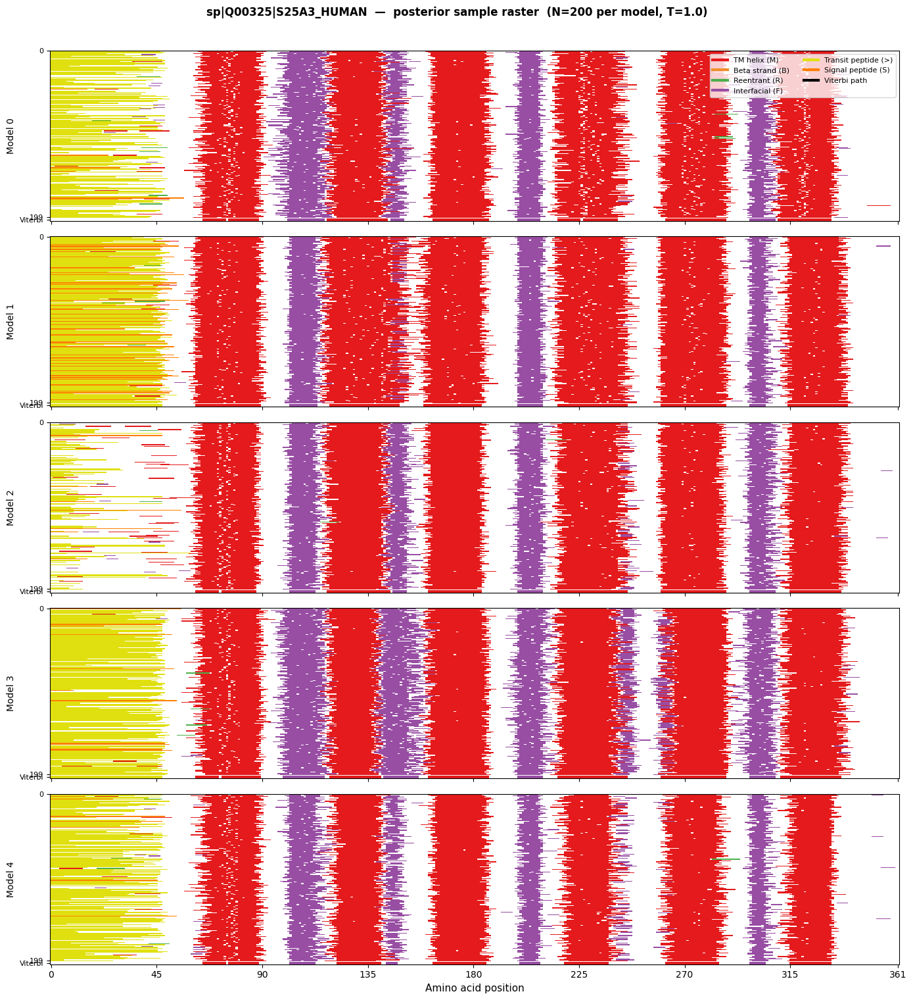

In [18]:
from matplotlib.lines import Line2D

# ── Raster plot via imshow — every sample is exactly one pixel row ───────────

def hex_to_rgb01(h):
    h = h.lstrip('#')
    return tuple(int(h[i:i+2], 16) / 255 for i in (0, 2, 4))

LABEL_RGB = {
    'M': np.array(hex_to_rgb01(COLORS['alpha'])),
    'B': np.array(hex_to_rgb01(COLORS['beta'])),
    'R': np.array(hex_to_rgb01(COLORS['reentrant'])),
    'F': np.array(hex_to_rgb01(COLORS['interfacial'])),
    '>': np.array(hex_to_rgb01(COLORS['transit'])),
    'S': np.array(hex_to_rgb01(COLORS['signal'])),
}
VITERBI_RGB = np.array([0.0, 0.0, 0.0])

L = len(sequence)
n_models = len(all_sample_strings)

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(14, n_models * 3),
    sharex=True,
)
if n_models == 1:
    axes = [axes]

for model_idx, (topo_strings, ax) in enumerate(zip(all_sample_strings, axes)):
    n = len(topo_strings)
    N_VITERBI_ROWS = 3
    img = np.ones((n + N_VITERBI_ROWS + 1, L, 3))  # white background, +1 gap row

    for sample_idx, topo in enumerate(topo_strings):
        for label, g in groupby(enumerate(topo), lambda x: x[1]):
            positions = [p for p, _ in g]
            if label in LABEL_RGB:
                img[sample_idx, positions, :] = LABEL_RGB[label]

    # Viterbi track (3 rows at the bottom, after a white gap row)
    vit = all_topo[model_idx]
    for label, g in groupby(enumerate(vit), lambda x: x[1]):
        positions = [p for p, _ in g]
        if label in LABEL_RGB:
            for vrow in range(n + 1, n + 1 + N_VITERBI_ROWS):
                img[vrow, positions, :] = LABEL_RGB[label]

    ax.imshow(img, aspect='auto', interpolation='nearest', origin='upper')
    ax.set_yticks([0, n - 1, n + 1 + N_VITERBI_ROWS // 2])
    ax.set_yticklabels(['0', str(n - 1), 'Viterbi'], fontsize=8)
    ax.set_ylabel(f'Model {model_idx}', fontsize=10)

axes[-1].set_xlabel('Amino acid position', fontsize=11)
axes[-1].set_xticks(np.linspace(0, L - 1, 9, dtype=int))

fig.suptitle(
    f'{seq_id}  —  posterior sample raster  (N={N_SAMPLES} per model, T=1.0)',
    fontweight='bold', fontsize=12, y=1.01,
)

legend_elements = [
    Line2D([0], [0], color=COLORS['alpha'],       linewidth=3, label='TM helix (M)'),
    Line2D([0], [0], color=COLORS['beta'],        linewidth=3, label='Beta strand (B)'),
    Line2D([0], [0], color=COLORS['reentrant'],   linewidth=3, label='Reentrant (R)'),
    Line2D([0], [0], color=COLORS['interfacial'], linewidth=3, label='Interfacial (F)'),
    Line2D([0], [0], color=COLORS['transit'],     linewidth=3, label='Transit peptide (>)'),
    Line2D([0], [0], color=COLORS['signal'],      linewidth=3, label='Signal peptide (S)'),
    Line2D([0], [0], color='black',               linewidth=3, label='Viterbi path'),
]
axes[0].legend(handles=legend_elements, loc='upper right', fontsize=8, ncol=2, frameon=True)

plt.tight_layout()
plt.show()


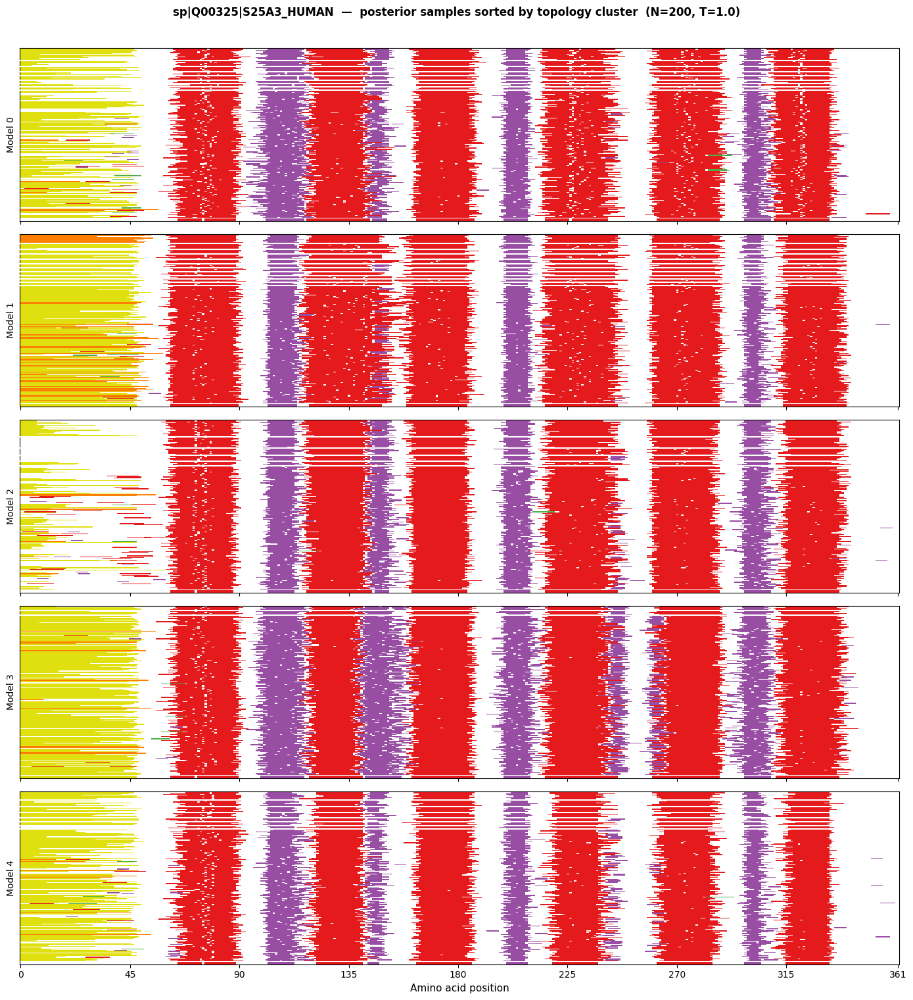

In [19]:
# ── Raster sorted by topology cluster (largest cluster at top) ───────────────

L = len(sequence)
n_models = len(all_sample_strings)

fig, axes = plt.subplots(n_models, 1, figsize=(14, n_models * 3), sharex=True)
if n_models == 1:
    axes = [axes]

for model_idx, (topo_strings, ax) in enumerate(zip(all_sample_strings, axes)):
    groups = group_by_topology(topo_strings)

    sorted_indices = [i for _, indices in groups for i in indices]

    n = len(sorted_indices)
    N_VITERBI_ROWS = 3
    img = np.ones((n + N_VITERBI_ROWS + 1, L, 3))

    for row, sample_idx in enumerate(sorted_indices):
        topo = topo_strings[sample_idx]
        for label, g in groupby(enumerate(topo), lambda x: x[1]):
            positions = [p for p, _ in g]
            if label in LABEL_RGB:
                img[row, positions, :] = LABEL_RGB[label]

    # Viterbi track
    vit = all_topo[model_idx]
    for label, g in groupby(enumerate(vit), lambda x: x[1]):
        positions = [p for p, _ in g]
        if label in LABEL_RGB:
            for vrow in range(n + 1, n + 1 + N_VITERBI_ROWS):
                img[vrow, positions, :] = LABEL_RGB[label]

    ax.imshow(img, aspect='auto', interpolation='nearest', origin='upper')

    # Dividing lines only between clusters with > 3 members
    cum = 0
    for _, indices in groups[:-1]:
        cum += len(indices)
        if len(indices) > 3:
            ax.axhline(cum - 0.5, color='white', linewidth=1.5, zorder=5)

    ax.set_yticks([])
    ax.set_ylabel(f'Model {model_idx}', fontsize=10)

axes[-1].set_xlabel('Amino acid position', fontsize=11)
axes[-1].set_xticks(np.linspace(0, L - 1, 9, dtype=int))

fig.suptitle(
    f'{seq_id}  —  posterior samples sorted by topology cluster  (N={N_SAMPLES}, T=1.0)',
    fontweight='bold', fontsize=12, y=1.01,
)
plt.tight_layout()
plt.show()


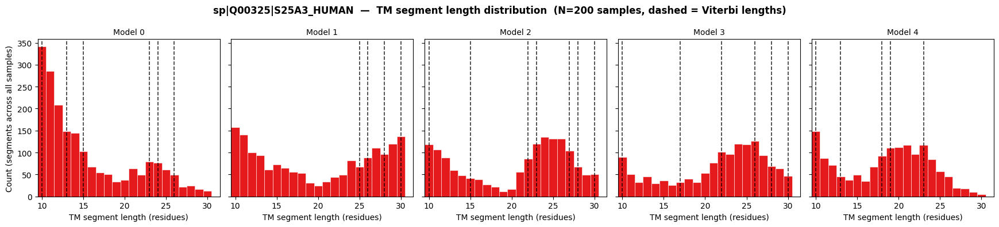

In [20]:
# ── TM segment length distributions ─────────────────────────────────────────
# For each model, collect the length of every TM segment across all samples.
# One subplot per model; x = segment length, y = count.

n_models = len(all_sample_strings)
fig, axes = plt.subplots(
    1, n_models,
    figsize=(3.5 * n_models, 4),
    sharey=True,
)
if n_models == 1:
    axes = [axes]

all_lengths_combined = []  # pooled across models for a shared bin range

for topo_strings in all_sample_strings:
    lengths = []
    for topo in topo_strings:
        for label, g in groupby(topo):
            if label == 'M':
                lengths.append(sum(1 for _ in g))
    all_lengths_combined.extend(lengths)

bin_min = min(all_lengths_combined)
bin_max = max(all_lengths_combined)
bins = range(bin_min, bin_max + 2)

for model_idx, (topo_strings, ax) in enumerate(zip(all_sample_strings, axes)):
    lengths = []
    for topo in topo_strings:
        for label, g in groupby(topo):
            if label == 'M':
                lengths.append(sum(1 for _ in g))

    ax.hist(lengths, bins=bins, align='left', color=COLORS['alpha'], edgecolor='white', linewidth=0.4)

    # Mark Viterbi segment lengths
    vit_lengths = [
        sum(1 for _ in g)
        for label, g in groupby(all_topo[model_idx])
        if label == 'M'
    ]
    for vl in set(vit_lengths):
        ax.axvline(vl, color='black', linewidth=1.2, linestyle='--', alpha=0.8)

    ax.set_xlabel('TM segment length (residues)', fontsize=10)
    if model_idx == 0:
        ax.set_ylabel('Count (segments across all samples)', fontsize=10)
    ax.set_title(f'Model {model_idx}', fontsize=10)
    ax.set_xlim(bin_min - 0.5, bin_max + 1.5)

fig.suptitle(
    f'{seq_id}  —  TM segment length distribution  (N={N_SAMPLES} samples, dashed = Viterbi lengths)',
    fontweight='bold', fontsize=12,
)
plt.tight_layout()
plt.show()


TM grammar:  min=10  max=30

Model 0: 341/1926 TM segments at min length (17.7%)
Model 1: 157/1684 TM segments at min length (9.3%)
Model 2: 119/1507 TM segments at min length (7.9%)
Model 3: 90/1377 TM segments at min length (6.5%)
Model 4: 148/1423 TM segments at min length (10.4%)


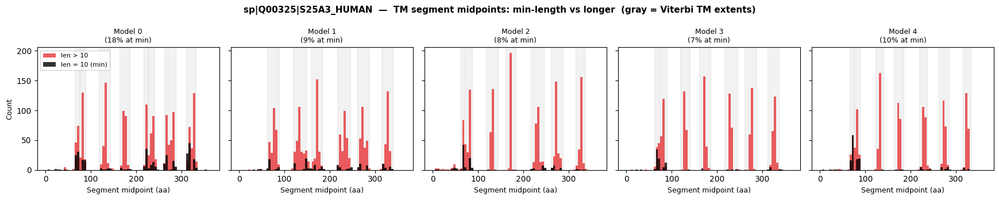

In [21]:
# ── Investigate the length-10 peak ──────────────────────────────────────────
# Hypothesis: the CRF grammar enforces a minimum TM segment length.
# Any time the model wants to "break" a long helix, each piece must be >= min_len,
# causing an artificial pile-up at exactly the minimum.

cfg = models.topology_models[0].crf_config
min_tm = cfg.min_segment_lengths["Mab"]   # Mab and Mba share the same minimum
max_tm = cfg.max_segment_lengths["Mab"]
print(f"TM grammar:  min={min_tm}  max={'unlimited' if max_tm == -1 else max_tm}")
print()

# For each model, show fraction of sampled TM segments at min length,
# and collect their midpoint positions.
fig, axes = plt.subplots(1, len(all_sample_strings), figsize=(3.5 * len(all_sample_strings), 3.5), sharey=True)
if len(all_sample_strings) == 1:
    axes = [axes]

for model_idx, (topo_strings, ax) in enumerate(zip(all_sample_strings, axes)):
    min_len_positions = []   # midpoints of all length-min_tm segments
    other_positions   = []   # midpoints of all other TM segments
    n_min, n_total = 0, 0

    for topo in topo_strings:
        pos = 0
        for label, g in groupby(topo):
            seg_len = sum(1 for _ in g)
            if label == 'M':
                mid = pos + seg_len / 2
                n_total += 1
                if seg_len == min_tm:
                    n_min += 1
                    min_len_positions.append(mid)
                else:
                    other_positions.append(mid)
            pos += seg_len

    pct = 100 * n_min / n_total if n_total else 0
    print(f"Model {model_idx}: {n_min}/{n_total} TM segments at min length ({pct:.1f}%)")

    # Plot midpoint density: where do min-length segments cluster along the sequence?
    bins = np.arange(0, len(sequence) + 5, 5)
    ax.hist(other_positions,   bins=bins, color=COLORS['alpha'], alpha=0.7, label=f'len > {min_tm}')
    ax.hist(min_len_positions, bins=bins, color='black',         alpha=0.8, label=f'len = {min_tm} (min)')
    ax.set_title(f'Model {model_idx}\n({pct:.0f}% at min)', fontsize=9)
    ax.set_xlabel('Segment midpoint (aa)', fontsize=9)
    if model_idx == 0:
        ax.set_ylabel('Count', fontsize=9)

axes[0].legend(fontsize=8)

# Mark Viterbi TM segment extents for reference
for model_idx, ax in enumerate(axes):
    for label, g in groupby(enumerate(all_topo[model_idx]), lambda x: x[1]):
        positions = [p for p, _ in g]
        if label == 'M':
            ax.axvspan(positions[0], positions[-1], alpha=0.10, color='gray', zorder=0)

fig.suptitle(
    f'{seq_id}  —  TM segment midpoints: min-length vs longer  (gray = Viterbi TM extents)',
    fontweight='bold', fontsize=11,
)
plt.tight_layout()
plt.show()


## Why does the model split TM segments?

Candidate causes investigated below:

1. **Grammar: minimum loop length = 1 residue.** Inside/outside states (`a_alpha`, `b_alpha`) are single self-loop states with no enforced minimum. The grammar permits TM(≥10) + loop(≥1) + TM(≥10), so any helix can be split for the cost of 1 transition in/out of TM — much cheaper than the ~10 extra residues each piece must carry.

2. **Learned transition weights.** If the model learned soft exit/entry weights (TM→a/b, a/b→TM), a brief loop may be nearly free in log-probability terms.

3. **Emission dips.** If the neural network's TM emission score dips at the split points (learned from training examples with mid-helix breaks), the CRF will preferentially place a loop there.

4. **Numerical / other.** Investigated below by checking emission magnitude and comparing path scores explicitly.


In [22]:
import pandas as pd
import math

cfg = models.topology_models[0].crf_config

# ── 1. Grammar: segment length constraints ───────────────────────────────────
print("=== Grammar: min / max segment lengths ===")
rows = []
for t in ["Mab", "Mba", "Bab", "Bba", "Raa", "Rbb", "Faa", "Fbb", "S", ">"]:
    mn = cfg.min_segment_lengths[t]
    mx = cfg.max_segment_lengths[t]
    rows.append({"type": t, "min": mn, "max": mx if mx != -1 else "∞"})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("Inside (a_alpha/b_alpha): self-loop state → min loop length = 1 residue")
print()

# ── 2. Learned transition weights ────────────────────────────────────────────
print("=== Transition weights (mean ± std across 5 models) ===")

def get_trans(model, from_key, to_key):
    fi = cfg.crf_states[from_key]
    ti = cfg.crf_states[to_key]
    return model.crf.transitions[fi, ti].item()

min_tm   = cfg.min_segment_lengths["Mab"]
max_tm   = cfg.max_segment_lengths["Mab"]
last_mab = f"Mab{max_tm - 1}"
last_mba = f"Mba{cfg.max_segment_lengths['Mba'] - 1}"

# Skip transition: from state (ceil(min/2)-1) to state (max - floor(min/2))
# This is the furthest skip, producing the minimum-length segment
start_seg  = math.ceil(min_tm / 2)   # = 5 for min=10
end_seg    = math.floor(min_tm / 2)  # = 5 for min=10
skip_from  = f"Mab{start_seg - 1}"                  # Mab4
skip_to    = f"Mab{max_tm - end_seg}"                # Mab(max-5), furthest landing
skip_from_mba = f"Mba{start_seg - 1}"
skip_to_mba   = f"Mba{cfg.max_segment_lengths['Mba'] - end_seg}"

keys = {
    f"TM exit     ({last_mab} → b_alpha)":       (last_mab,      "b_alpha"),
    f"TM exit     ({last_mba} → a_alpha)":       (last_mba,      "a_alpha"),
    "IO self-loop (a → a)":                       ("a_alpha",     "a_alpha"),
    "IO self-loop (b → b)":                       ("b_alpha",     "b_alpha"),
    "TM re-entry  (b → Mba0)":                   ("b_alpha",     "Mba0"),
    "TM re-entry  (a → Mab0)":                   ("a_alpha",     "Mab0"),
    f"Skip Mab    ({skip_from} → {skip_to})":    (skip_from,     skip_to),
    f"Skip Mba    ({skip_from_mba} → {skip_to_mba})": (skip_from_mba, skip_to_mba),
}

trans_rows = []
for label, (fk, tk) in keys.items():
    vals = [get_trans(m, fk, tk) for m in models.topology_models]
    mean = sum(vals) / len(vals)
    std  = (sum((v - mean)**2 for v in vals) / len(vals))**0.5
    trans_rows.append({"transition": label,
                        "mean": f"{mean:.3f}", "std": f"{std:.3f}",
                        "values": [f"{v:.3f}" for v in vals]})
print(pd.DataFrame(trans_rows)[["transition","mean","std","values"]].to_string(index=False))
print()

# ── 3. Net transition cost: split detour vs two skip transitions ──────────────
print("=== Net transition cost of a minimum-length split (Model 0) ===")
m0 = models.topology_models[0]
exit_w    = get_trans(m0, last_mab,  "b_alpha")
io_w      = get_trans(m0, "b_alpha", "b_alpha")
reentry_w = get_trans(m0, "b_alpha", "Mba0")
skip_mab_w = get_trans(m0, skip_from, skip_to)
skip_mba_w = get_trans(m0, skip_from_mba, skip_to_mba)

split_transition_cost = exit_w + io_w + reentry_w
skip_gain             = skip_mab_w + skip_mba_w   # used twice in a split path
print(f"  exit + IO_loop + reentry  = {split_transition_cost:.3f}")
print(f"  skip Mab + skip Mba       = {skip_gain:.3f}  (bonus from two skip transitions)")
print(f"  net split transition gain = {split_transition_cost + skip_gain:.3f}")
print()
print("  (A continuous path of the same length uses forward chain transitions instead of skips.)")
print("  If net gain > 0, the grammar actively incentivises splitting.")

# ── 4. Collect split positions ────────────────────────────────────────────────
split_positions = []
for model_idx, topo_strings in enumerate(all_sample_strings):
    for topo in topo_strings:
        segs = [(lbl, [p for p, _ in grp])
                for lbl, grp in groupby(enumerate(topo), lambda x: x[1])]
        for k in range(1, len(segs) - 1):
            lbl, positions = segs[k]
            if lbl in ('a', 'b') and len(positions) <= 3:
                if segs[k-1][0] == 'M' and segs[k+1][0] == 'M':
                    for p in positions:
                        split_positions.append((model_idx, p))

print(f"\nShort TM-loop-TM split positions found: {len(split_positions)} instances")
if split_positions:
    pos_counts = {}
    for _, p in split_positions:
        pos_counts[p] = pos_counts.get(p, 0) + 1
    top_splits = sorted(pos_counts.items(), key=lambda x: -x[1])[:10]
    print(f"Top split positions (pos, count): {top_splits}")


=== Grammar: min / max segment lengths ===
type  min max
 Mab   10  30
 Mba   10  30
 Bab    5  15
 Bba    5  15
 Raa    8   ∞
 Rbb    8   ∞
 Faa    5   ∞
 Fbb    5   ∞
   S   10   ∞
   >    5   ∞

Inside (a_alpha/b_alpha): self-loop state → min loop length = 1 residue

=== Transition weights (mean ± std across 5 models) ===
                   transition   mean   std                                   values
TM exit     (Mab29 → b_alpha) -0.004 0.002 [-0.003, -0.006, -0.006, -0.004, -0.002]
TM exit     (Mba29 → a_alpha)  0.054 0.001      [0.055, 0.052, 0.052, 0.054, 0.055]
         IO self-loop (a → a)  0.103 0.000      [0.103, 0.103, 0.103, 0.103, 0.103]
         IO self-loop (b → b)  0.021 0.000      [0.021, 0.021, 0.021, 0.022, 0.021]
      TM re-entry  (b → Mba0) -0.091 0.001 [-0.090, -0.092, -0.092, -0.090, -0.089]
      TM re-entry  (a → Mab0) -0.121 0.002 [-0.119, -0.122, -0.123, -0.120, -0.119]
   Skip Mab    (Mab4 → Mab25) -0.094 0.001 [-0.094, -0.093, -0.095, -0.094, -0.095]
 

In [23]:
# ── Cell 1: Formal path uniqueness verification ───────────────────────────────
# Enumerate all valid paths through the Mab subgraph (Mab0 → Mab_{max-1})
# by BFS. For each path length L, count how many distinct paths exist.
# If the grammar is correct, count should be exactly 1 for every L in [min, max].

import math
from collections import defaultdict

def verify_path_uniqueness(tm_type, cfg):
    min_seg = cfg.min_segment_lengths[tm_type]
    max_seg = cfg.max_segment_lengths[tm_type]
    if max_seg == -1:
        print(f"{tm_type}: unlimited max — skip uniqueness check")
        return

    # Build adjacency list for states within this TM type only
    states = {k: v for k, v in cfg.crf_states.items() if k.startswith(tm_type)}
    state_ids = set(states.values())
    entry_state = states[f"{tm_type}0"]
    exit_state  = states[f"{tm_type}{max_seg - 1}"]

    # Build forward graph from allowed_state_transitions
    graph = defaultdict(list)
    for (src, dst) in cfg.allowed_state_transitions:
        if src in state_ids and dst in state_ids:
            graph[src].append(dst)

    # BFS: track (current_state, path_length) → number of ways to reach it
    # paths[state][length] = count of distinct paths of that length ending at state
    from collections import Counter
    paths = defaultdict(Counter)
    paths[entry_state][1] = 1  # start: 1 way to be at entry with length 1

    # Process in topological order (states are numbered sequentially)
    for state in sorted(state_ids):
        for length, count in paths[state].items():
            for nxt in graph[state]:
                paths[nxt][length + 1] += count

    # Report path counts arriving at exit_state
    exit_counts = paths[exit_state]
    all_unique = all(c == 1 for c in exit_counts.values())

    print(f"\n{tm_type}  (min={min_seg}, max={max_seg}, states {entry_state}..{exit_state})")
    print(f"  Path uniqueness: {'✓ UNIQUE' if all_unique else '✗ NOT UNIQUE — multiple paths per length!'}")
    print(f"  {'L':>4}  {'paths':>6}")
    for length in sorted(exit_counts):
        marker = "" if exit_counts[length] == 1 else "  ← MULTIPLE"
        print(f"  {length:>4}  {exit_counts[length]:>6}{marker}")

for tm_type in ["Mab", "Mba"]:
    verify_path_uniqueness(tm_type, cfg)



Mab  (min=10, max=30, states 19..48)
  Path uniqueness: ✓ UNIQUE
     L   paths
    10       1
    11       1
    12       1
    13       1
    14       1
    15       1
    16       1
    17       1
    18       1
    19       1
    20       1
    21       1
    22       1
    23       1
    24       1
    25       1
    26       1
    27       1
    28       1
    29       1
    30       1

Mba  (min=10, max=30, states 49..78)
  Path uniqueness: ✓ UNIQUE
     L   paths
    10       1
    11       1
    12       1
    13       1
    14       1
    15       1
    16       1
    17       1
    18       1
    19       1
    20       1
    21       1
    22       1
    23       1
    24       1
    25       1
    26       1
    27       1
    28       1
    29       1
    30       1


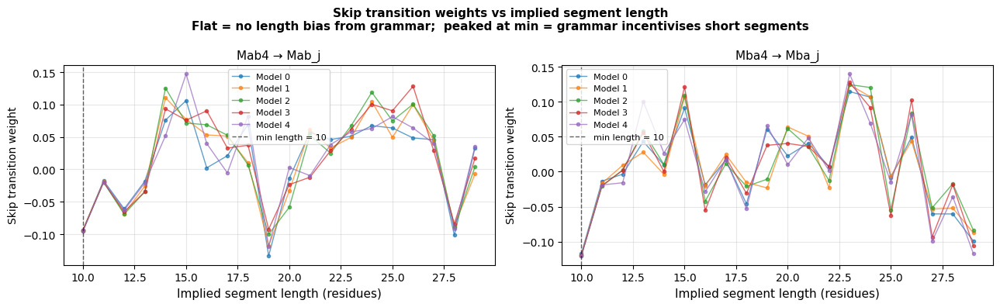

In [24]:
# ── Cell 2: Skip transition weights vs implied segment length ─────────────────
# Each skip Mab4→Mab_j implies a unique segment length L = start_seg + (max_tm - j).
# If these weights are non-uniform the grammar itself creates a length bias.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, tm_type in zip(axes, ["Mab", "Mba"]):
    min_seg   = cfg.min_segment_lengths[tm_type]
    max_seg   = cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)
    skip_src  = f"{tm_type}{start_seg - 1}"

    js      = list(range(start_seg + 1, max_seg - end_seg + 1))
    lengths = [start_seg + (max_seg - j) for j in js]

    for model_idx, model in enumerate(models.topology_models):
        weights = [model.crf.transitions[cfg.crf_states[skip_src],
                                          cfg.crf_states[f"{tm_type}{j}"]].item()
                   for j in js]
        ax.plot(lengths, weights, marker='o', markersize=3, linewidth=1,
                alpha=0.7, label=f'Model {model_idx}')

    ax.axvline(min_seg, color='black', linewidth=1, linestyle='--', alpha=0.6,
               label=f'min length = {min_seg}')
    ax.set_xlabel('Implied segment length (residues)', fontsize=11)
    ax.set_ylabel('Skip transition weight', fontsize=10)
    ax.set_title(f'{skip_src} → {tm_type}_j', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle(
    'Skip transition weights vs implied segment length\n'
    'Flat = no length bias from grammar;  peaked at min = grammar incentivises short segments',
    fontweight='bold', fontsize=11,
)
plt.tight_layout()
plt.show()


Original weights saved.
Skip weights set to per-length average of Mab and Mba.


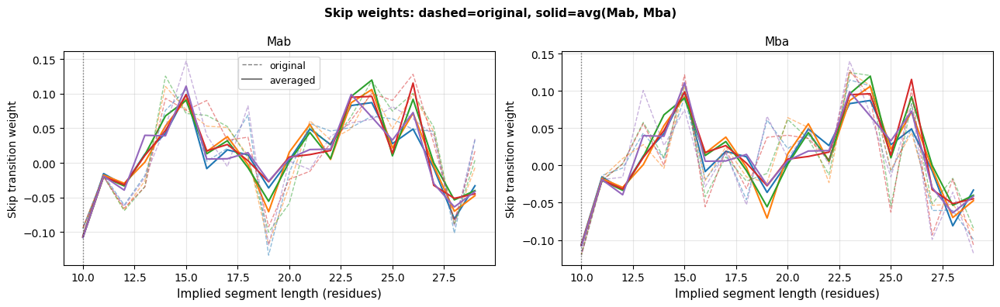

In [25]:
import copy

# ── Post-hoc correction: average Mab and Mba skip weights ────────────────────
# Mab and Mba are mirror directions through the membrane and should prefer the
# same segment lengths. We replace both with their per-length mean, which
# smooths the Mab dip/spike without imposing an external target distribution.

def get_skip_info(cfg, tm_type):
    min_seg   = cfg.min_segment_lengths[tm_type]
    max_seg   = cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)
    skip_src  = f"{tm_type}{start_seg - 1}"
    js        = list(range(start_seg + 1, max_seg - end_seg + 1))
    lengths   = [start_seg + (max_seg - j) for j in js]
    return skip_src, js, lengths, min_seg, max_seg

# Save originals
original_transitions = [m.crf.transitions.data.clone() for m in models.topology_models]
print("Original weights saved.")

# Apply per-model averaging of Mab and Mba skip weights
for model in models.topology_models:
    skip_src_ab, js_ab, lengths_ab, _, _ = get_skip_info(cfg, "Mab")
    skip_src_ba, js_ba, lengths_ba, _, _ = get_skip_info(cfg, "Mba")

    src_ab = cfg.crf_states[skip_src_ab]
    src_ba = cfg.crf_states[skip_src_ba]

    for j_ab, j_ba in zip(js_ab, js_ba):
        dst_ab = cfg.crf_states[f"Mab{j_ab}"]
        dst_ba = cfg.crf_states[f"Mba{j_ba}"]
        w_ab = model.crf.transitions.data[src_ab, dst_ab].item()
        w_ba = model.crf.transitions.data[src_ba, dst_ba].item()
        avg  = (w_ab + w_ba) / 2.0
        model.crf.transitions.data[src_ab, dst_ab] = avg
        model.crf.transitions.data[src_ba, dst_ba] = avg

print("Skip weights set to per-length average of Mab and Mba.")

# ── Before / after comparison plot ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, tm_type in zip(axes, ["Mab", "Mba"]):
    skip_src, js, lengths, min_seg, _ = get_skip_info(cfg, tm_type)

    for model_idx, (model, orig) in enumerate(zip(models.topology_models, original_transitions)):
        src_idx = cfg.crf_states[skip_src]
        old_w = [orig[src_idx, cfg.crf_states[f"{tm_type}{j}"]].item() for j in js]
        new_w = [model.crf.transitions.data[src_idx, cfg.crf_states[f"{tm_type}{j}"]].item() for j in js]
        c = plt.cm.tab10(model_idx)
        ax.plot(lengths, old_w, color=c, linewidth=1,   linestyle='--', alpha=0.5)
        ax.plot(lengths, new_w, color=c, linewidth=1.5, linestyle='-')

    ax.axvline(min_seg, color='black', linewidth=1, linestyle=':', alpha=0.5)
    ax.set_xlabel('Implied segment length (residues)', fontsize=11)
    ax.set_ylabel('Skip transition weight', fontsize=10)
    ax.set_title(f'{tm_type}', fontsize=11)
    ax.grid(alpha=0.3)

from matplotlib.lines import Line2D
axes[0].legend(handles=[
    Line2D([0],[0], color='gray', linewidth=1,   linestyle='--', label='original'),
    Line2D([0],[0], color='gray', linewidth=1.5, linestyle='-',  label='averaged'),
], fontsize=9)

fig.suptitle('Skip weights: dashed=original, solid=avg(Mab, Mba)', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()


In [26]:
# ── Manually lower the L=10 (minimum-length) skip transition weight ───────────
L10_WEIGHT = -0.4

for tm_type in ["Mab", "Mba"]:
    skip_src, js, lengths, min_seg, max_seg = get_skip_info(cfg, tm_type)
    # The L=min_seg skip is the last entry (furthest jump: skip_src → js[-1])
    j_min = js[-1]   # corresponds to L=min_seg
    src_idx = cfg.crf_states[skip_src]
    dst_idx = cfg.crf_states[f"{tm_type}{j_min}"]
    for model in models.topology_models:
        old = model.crf.transitions.data[src_idx, dst_idx].item()
        model.crf.transitions.data[src_idx, dst_idx] = L10_WEIGHT

print(f"L=10 skip weight set to {L10_WEIGHT} for Mab and Mba in all models.")
print(f"(was ~{old:.3f} before)")


L=10 skip weight set to -0.4 for Mab and Mba in all models.
(was ~-0.108 before)


In [27]:
# ── Re-run Viterbi + posterior sampling with corrected weights ────────────────

print("=== Viterbi with corrected skip weights ===")
all_topo_corrected = []
for i in range(len(models.topology_models)):
    t, m_p, marg, _ = models.predict_single_model(i, embedding, mask, temperature=TEMPERATURE)
    all_topo_corrected.append(t)
    vtype = infer_structural_type(t)
    n_tm  = sum(1 for lbl, g in groupby(t) if lbl == 'M' for _ in [g])
    segs  = [(lbl, sum(1 for _ in g)) for lbl, g in groupby(t) if lbl == 'M']
    print(f"  Model {i}: {vtype}  TM segments: {[s[1] for s in segs]}")

print()
print("=== Posterior sampling with corrected skip weights ===")
sampled_corrected = []
for model_idx in range(len(models.topology_models)):
    best_topo, winning_type, vote_summary, fraction, topo_strings = posterior_sample_predict(
        models, model_idx, embedding, mask, temperature=1.0
    )
    sampled_corrected.append((best_topo, winning_type, vote_summary, fraction))
    print(f"  Model {model_idx}: {winning_type}  ({fraction:.0%})  top groups: {vote_summary[:3]}")

# ── Restore original weights ──────────────────────────────────────────────────
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)
print("\nOriginal weights restored.")


=== Viterbi with corrected skip weights ===
  Model 0: M  TM segments: [11, 13, 23, 25, 11, 15, 26, 23]
  Model 1: M+T  TM segments: [28, 30, 25, 30, 28, 23]
  Model 2: M  TM segments: [10, 15, 27, 23, 30, 27, 22]
  Model 3: M+T  TM segments: [25, 22, 26, 30, 28, 26]
  Model 4: M+T  TM segments: [23, 19, 23, 19, 23, 18]

=== Posterior sampling with corrected skip weights ===
  Model 0: M+T  (17%)  top groups: [('M+T', '10TM', 34), ('M+T', '10TM', 7), ('M+T', '8TM', 6)]
  Model 1: M+S  (6%)  top groups: [('M+S', '6TM', 11), ('M+T', '7TM', 7), ('M+T', '6TM', 6)]
  Model 2: M+T  (12%)  top groups: [('M+T', '7TM', 23), ('M', '7TM', 21), ('M+T', '9TM', 4)]
  Model 3: M+T  (2%)  top groups: [('M+T', '7TM', 5), ('M+T', '7TM', 5), ('M+T', '7TM', 3)]
  Model 4: M+T  (6%)  top groups: [('M+T', '7TM', 13), ('M+T', '7TM', 9), ('M+T', '6TM', 7)]

Original weights restored.


In [29]:
# ── Collect per-model emission tensors ───────────────────────────────────────
# Needed by the emission-score analysis cells below.
# Shape: list of (seq_len, num_crf_states) numpy arrays, one per model.
all_emissions = []
for _model_idx in range(len(models.topology_models)):
    _top_model = models.topology_models[_model_idx]
    with torch.no_grad():
        _em = _top_model._get_network_emissions(embedding, mask)
    all_emissions.append(_em[0].cpu().numpy())  # squeeze batch dim
print(f"Collected emissions for {len(all_emissions)} models, shape: {all_emissions[0].shape}")


Collected emissions for 5 models, shape: (362, 135)


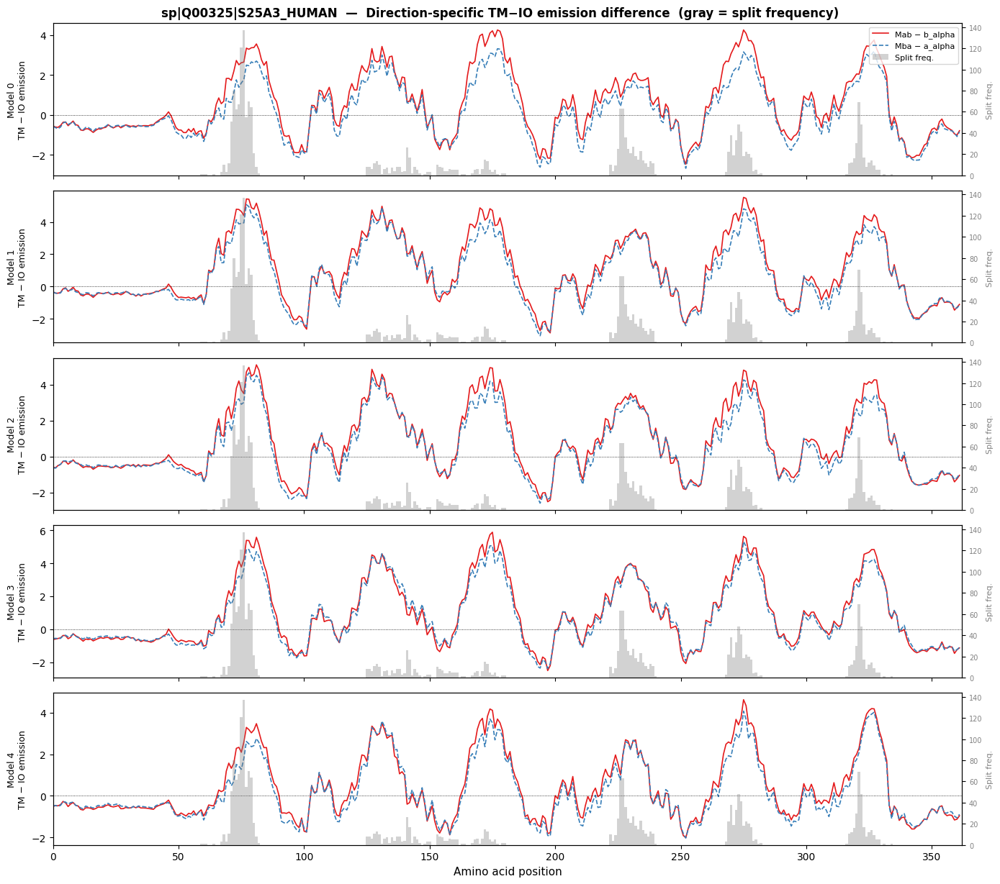

In [30]:
# ── Emission scores: direction-specific TM vs competing IO state ──────────────
# Mab (inside→outside) competes with b_alpha at its exit point
# Mba (outside→inside) competes with a_alpha at its exit point
# Plot both differences along the sequence with split-position frequency overlaid.

mab_indices = [v for k, v in cfg.crf_states.items() if k.startswith("Mab")]
mba_indices = [v for k, v in cfg.crf_states.items() if k.startswith("Mba")]
a_idx = cfg.crf_states["a_alpha"]
b_idx = cfg.crf_states["b_alpha"]

split_freq = np.zeros(len(sequence))
for _, p in split_positions:
    if 0 <= p < len(sequence):
        split_freq[p] += 1

x = np.arange(len(sequence))
fig, axes = plt.subplots(len(all_emissions), 1, figsize=(14, 2.5 * len(all_emissions)), sharex=True)
if len(all_emissions) == 1:
    axes = [axes]

for model_idx, (em, ax) in enumerate(zip(all_emissions, axes)):
    mab_mean = em[:, mab_indices].mean(axis=1)
    mba_mean = em[:, mba_indices].mean(axis=1)
    b_score  = em[:, b_idx]
    a_score  = em[:, a_idx]

    diff_mab = mab_mean - b_score   # positive = TM preferred over outside
    diff_mba = mba_mean - a_score   # positive = TM preferred over inside

    ax2 = ax.twinx()
    ax2.bar(x, split_freq, color='gray', alpha=0.35, width=1.0, label='Split freq.')
    ax2.set_ylabel('Split freq.', fontsize=8, color='gray')
    ax2.tick_params(axis='y', labelcolor='gray', labelsize=7)

    ax.plot(x, diff_mab, color=COLORS['alpha'],    linewidth=1.2, label='Mab − b_alpha')
    ax.plot(x, diff_mba, color=COLORS['outside'],  linewidth=1.2, linestyle='--', label='Mba − a_alpha')
    ax.axhline(0, color='black', linewidth=0.6, linestyle=':')

    ax.set_xlim(0, len(sequence))
    ax.set_ylabel(f'Model {model_idx}\nTM − IO emission', fontsize=9)

    if model_idx == 0:
        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=8)

axes[-1].set_xlabel('Amino acid position', fontsize=11)
fig.suptitle(
    f'{seq_id}  —  Direction-specific TM−IO emission difference  (gray = split frequency)',
    fontweight='bold', fontsize=12,
)
plt.tight_layout()
plt.show()


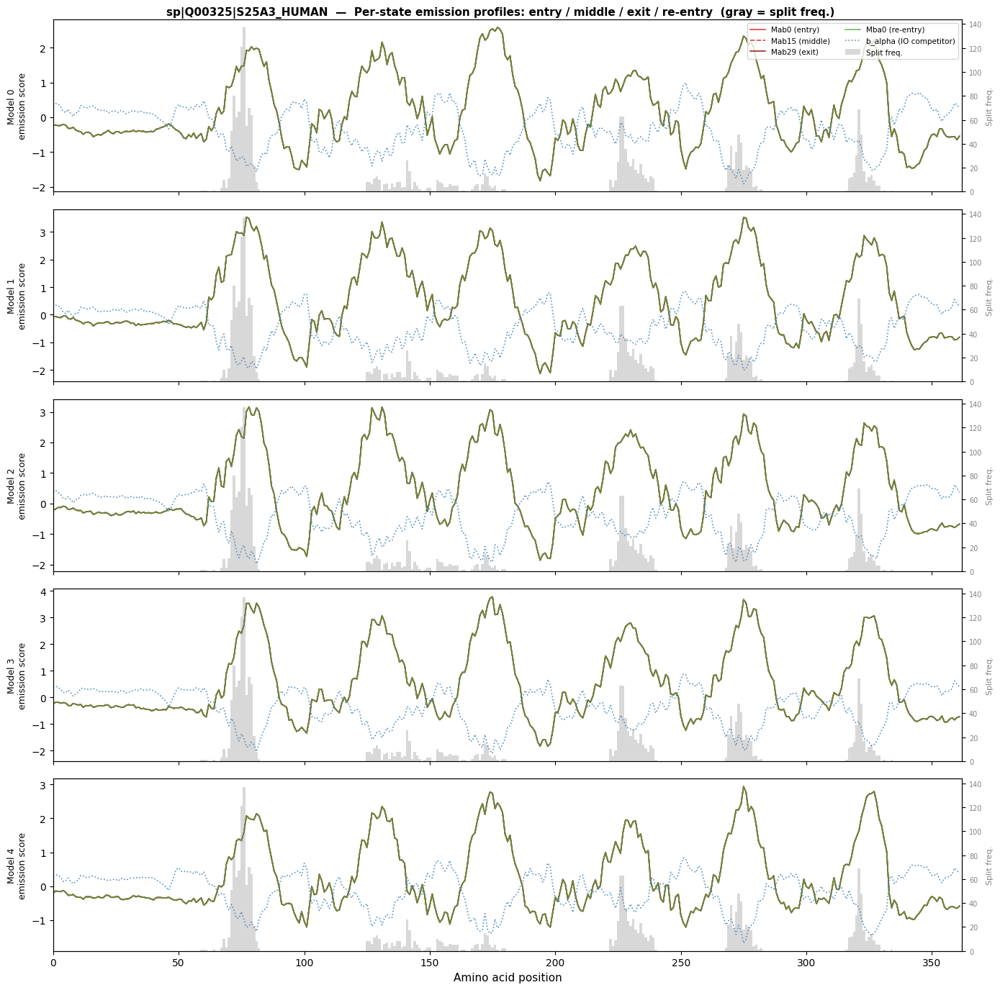

In [31]:
# ── Per-state emission profiles for key TM states ────────────────────────────
# Hypothesis: the exit state Mab(last) and re-entry state Mba0 may have
# disproportionately high emission at helix midpoints, making a split
# attractive even where the mean TM emission is at its peak.
#
# We plot emissions for:
#   Mab0       — helix entry (first mandatory state)
#   Mab(mid)   — a middle state
#   Mab(last)  — exit state (only state that can leave TM)
#   Mba0       — re-entry after a split (first state of reverse-direction TM)
#   b_alpha    — the IO competitor for Mab

max_tm   = cfg.max_segment_lengths["Mab"]
mid_mab  = max_tm // 2

state_specs = [
    ("Mab0",              f"Mab0 (entry)",          COLORS['alpha'],       '-'),
    (f"Mab{mid_mab}",     f"Mab{mid_mab} (middle)", COLORS['alpha'],       '--'),
    (f"Mab{max_tm-1}",    f"Mab{max_tm-1} (exit)",  'darkred',             '-'),
    ("Mba0",              "Mba0 (re-entry)",         COLORS['reentrant'],   '-'),
    ("b_alpha",           "b_alpha (IO competitor)", COLORS['outside'],     ':'),
]

x = np.arange(len(sequence))
fig, axes = plt.subplots(len(all_emissions), 1, figsize=(14, 2.8 * len(all_emissions)), sharex=True)
if len(all_emissions) == 1:
    axes = [axes]

for model_idx, (em, ax) in enumerate(zip(all_emissions, axes)):
    ax2 = ax.twinx()
    ax2.bar(x, split_freq, color='gray', alpha=0.3, width=1.0, label='Split freq.')
    ax2.set_ylabel('Split freq.', fontsize=8, color='gray')
    ax2.tick_params(axis='y', labelcolor='gray', labelsize=7)

    for state_key, label, color, ls in state_specs:
        idx = cfg.crf_states[state_key]
        ax.plot(x, em[:, idx], color=color, linewidth=1.2, linestyle=ls, label=label, alpha=0.85)

    ax.set_xlim(0, len(sequence))
    ax.set_ylabel(f'Model {model_idx}\nemission score', fontsize=9)

    if model_idx == 0:
        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labels1 + labels2,
                  loc='upper right', fontsize=7.5, ncol=2, frameon=True)

axes[-1].set_xlabel('Amino acid position', fontsize=11)
fig.suptitle(
    f'{seq_id}  —  Per-state emission profiles: entry / middle / exit / re-entry  (gray = split freq.)',
    fontweight='bold', fontsize=11,
)
plt.tight_layout()
plt.show()


## Corrected predictions — post-hoc skip weight adjustment

Three corrections applied permanently to all 5 ensemble models:
1. **Symmetrize**: average Mab and Mba skip weights per length
2. **Penalise L=10** (minimum-length segment): set to −0.40
3. **Penalise L=11**: set to −0.05

After applying, Viterbi is re-run and the classic topology + marginals plots are reproduced.

In [32]:
# ── Apply corrected skip weights (permanent) ──────────────────────────────────
# Corrections are applied on top of original (trained) weights.
# Run this cell once; re-running will double-apply — restart kernel and re-run
# from the top if you need a clean slate.

import math

cfg = models.topology_models[0].crf_config

def get_skip_info(cfg, tm_type):
    """Return (skip_src_name, js, lengths, min_seg, max_seg) for Mab or Mba."""
    min_seg   = cfg.min_segment_lengths[tm_type]
    max_seg   = cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)
    skip_src  = f"{tm_type}{start_seg - 1}"
    js        = list(range(start_seg + 1, max_seg - end_seg + 1))
    lengths   = [start_seg + (max_seg - j) for j in js]
    return skip_src, js, lengths, min_seg, max_seg

# ── 1. Symmetrize Mab and Mba skip weights per length ─────────────────────────
skip_src_ab, js_ab, _, _, _ = get_skip_info(cfg, "Mab")
skip_src_ba, js_ba, _, _, _ = get_skip_info(cfg, "Mba")

for model in models.topology_models:
    for j_ab, j_ba in zip(js_ab, js_ba):
        src_ab = cfg.crf_states[skip_src_ab]
        dst_ab = cfg.crf_states[f"Mab{j_ab}"]
        src_ba = cfg.crf_states[skip_src_ba]
        dst_ba = cfg.crf_states[f"Mba{j_ba}"]
        w_ab = model.crf.transitions.data[src_ab, dst_ab].item()
        w_ba = model.crf.transitions.data[src_ba, dst_ba].item()
        avg  = (w_ab + w_ba) / 2.0
        model.crf.transitions.data[src_ab, dst_ab] = avg
        model.crf.transitions.data[src_ba, dst_ba] = avg

print("Step 1 done: Mab and Mba skip weights symmetrized.")

# ── 2. Penalise L=10 ──────────────────────────────────────────────────────────
L10_WEIGHT = -0.6
for tm_type in ["Mab", "Mba"]:
    skip_src, js, lengths, min_seg, _ = get_skip_info(cfg, tm_type)
    j_min   = js[lengths.index(min_seg)]
    src_idx = cfg.crf_states[skip_src]
    dst_idx = cfg.crf_states[f"{tm_type}{j_min}"]
    for model in models.topology_models:
        model.crf.transitions.data[src_idx, dst_idx] = L10_WEIGHT

print(f"Step 2 done: L=10 skip weight → {L10_WEIGHT}.")

# ── 3. Penalise L=11 ──────────────────────────────────────────────────────────
L11_WEIGHT = -0.5
for tm_type in ["Mab", "Mba"]:
    skip_src, js, lengths, _, _ = get_skip_info(cfg, tm_type)
    j11 = js[lengths.index(11)]
    src_idx = cfg.crf_states[skip_src]
    dst_idx = cfg.crf_states[f"{tm_type}{j11}"]
    for model in models.topology_models:
        model.crf.transitions.data[src_idx, dst_idx] = L11_WEIGHT

print(f"Step 3 done: L=11 skip weight → {L11_WEIGHT}.")
print("All corrections applied.")

Step 1 done: Mab and Mba skip weights symmetrized.
Step 2 done: L=10 skip weight → -0.6.
Step 3 done: L=11 skip weight → -0.5.
All corrections applied.


In [33]:
# ── Re-run Viterbi + marginals with corrected weights ─────────────────────────
all_topo_corr, all_mem_probs_corr, all_marginals_corr = [], [], []

with torch.no_grad():
    for i in range(len(models.topology_models)):
        t, m_p, marg, _ = models.predict_single_model(i, embedding, mask, temperature=TEMPERATURE)
        all_topo_corr.append(t)
        all_mem_probs_corr.append(m_p)
        all_marginals_corr.append(marg)

# Aggregate consensus
final_topo_corr, final_marg_corr = aggregate_topology_predictions(all_topo_corr, all_marginals_corr)
pred_mem_indices_corr, mem_probs_corr = aggregate_memtype_predictions(all_mem_probs_corr)
final_topo_corr = suppress_implausible_predictions(final_topo_corr)

main_mem_idx_corr = max(pred_mem_indices_corr, key=lambda i: mem_probs_corr[i])
type_code_corr    = infer_structural_type(final_topo_corr)
final_topo_out_corr = translate_ab_topology(final_topo_corr, main_mem_idx_corr)

# Recompute split marginals for heatmap
all_marg_split_corr = []
with torch.no_grad():
    for i, model in enumerate(models.topology_models):
        emissions = model._get_network_emissions(embedding, mask)
        if TEMPERATURE != 1.0:
            emissions = emissions * TEMPERATURE
        raw_marg  = model.crf.compute_marginal_probabilities(emissions, mask, truncate=False)
        all_marg_split_corr.append(simplify_marginals_split_io(model.crf_config, raw_marg[0]))

best_idx_corr = all_topo_corr.index(final_topo_corr)
final_marg_split_corr = all_marg_split_corr[best_idx_corr]

print(f"Protein type : {DISPLAY_PROT_TYPE_MAPPING[type_code_corr]}")
print(f"Topology     : {final_topo_out_corr}")
print()
for i, topo in enumerate(all_topo_corr):
    from itertools import groupby as _gb
    segs = [len(list(g)) for lbl, g in _gb(topo) if lbl == 'M']
    print(f"  Model {i}: {topo[:6]}...  TM lengths: {segs}")

Protein type : Alpha TM + TP
Topology     : >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>gggggggggggggggggMMMMMMMMMMMMMMMMMMMMMMMMMGGGGGGGGGFFFFFFFFFFFFFFFFFFGGMMMMMMMMMMMMMMMMMMMMMMgFFFFFFFFFFFFFFFggggMMMMMMMMMMMMMMMMMMMMMMMMMMGGGGGGGGGGGGFFFFFFFFFFFGGGGGGMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMggggggggggggggMMMMMMMMMMMMMMMMMMMMMMMMMMMMGGGGGGGGGGFFFFFFFFFFFGGMMMMMMMMMMMMMMMMMMMMMMMMMMggggggggggggggggggggggggg

  Model 0: aaaaaa...  TM lengths: [12, 13, 23, 25, 10, 15, 26, 23]
  Model 1: >>>>>>...  TM lengths: [28, 30, 25, 30, 28, 23]
  Model 2: aaaaaa...  TM lengths: [10, 15, 27, 23, 30, 27, 22]
  Model 3: >>>>>>...  TM lengths: [25, 22, 26, 30, 28, 26]
  Model 4: >>>>>>...  TM lengths: [23, 19, 23, 19, 23, 18]


/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/134209942.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


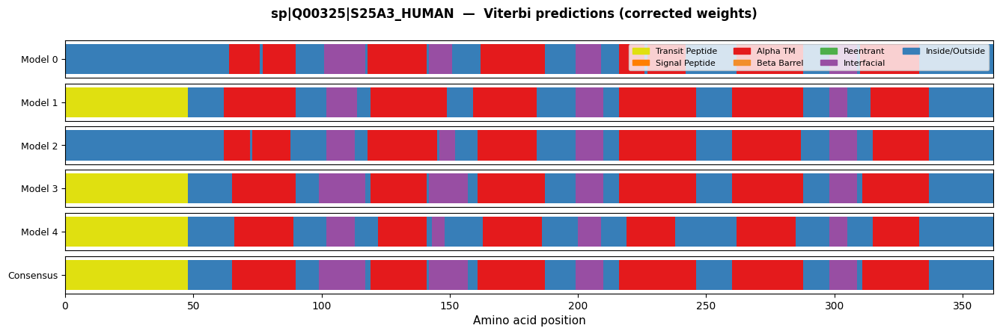

/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/134209942.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


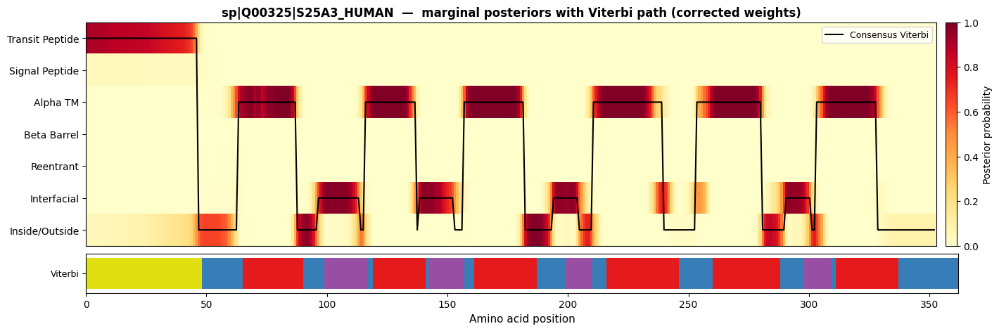

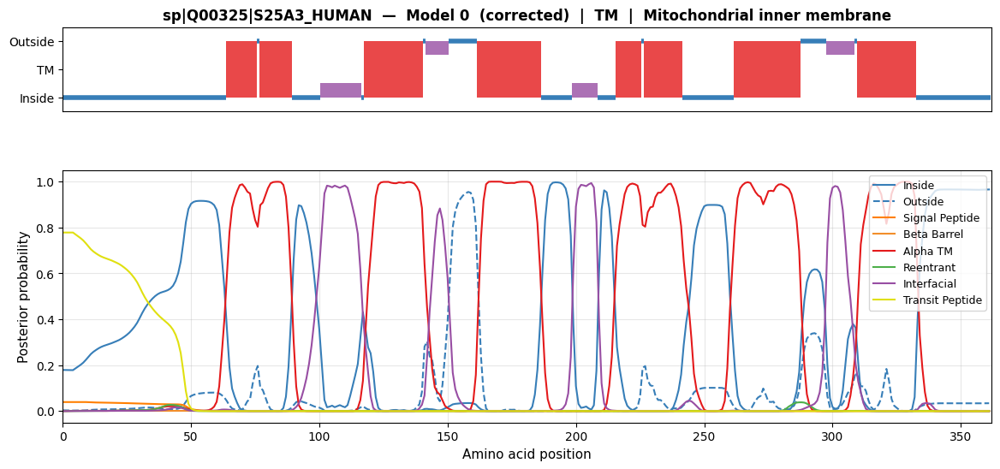

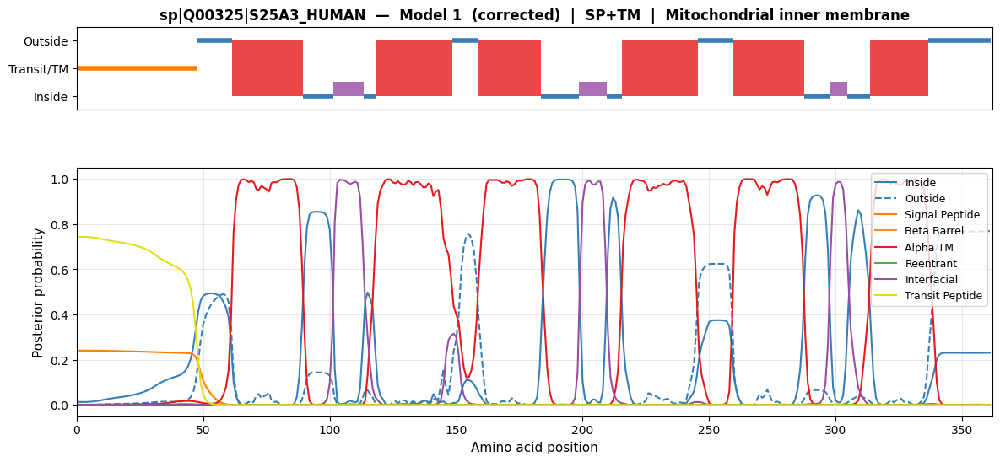

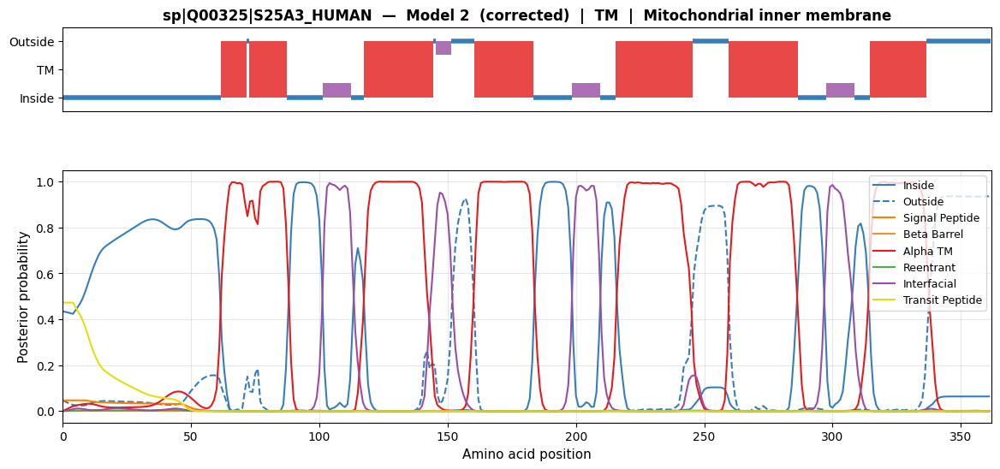

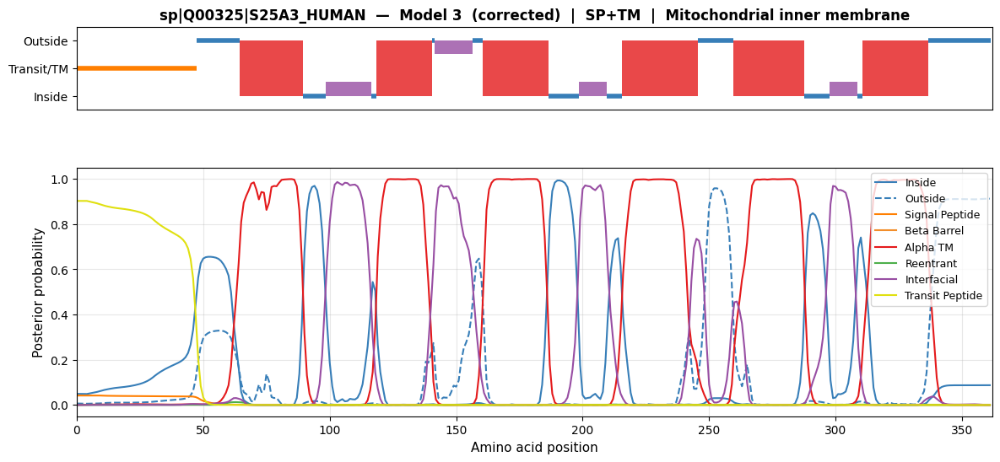

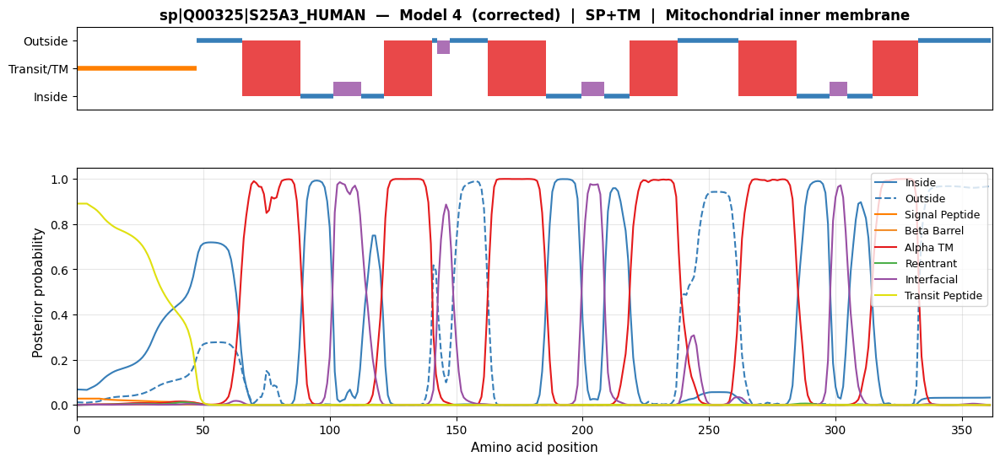

In [34]:
# ── Classic plots: per-model topology bars + marginal heatmap ─────────────────
import matplotlib.gridspec as gridspec

n_models = len(all_topo_corr)
L = len(sequence)

# ── Figure 1: Per-model topology bars ─────────────────────────────────────────
fig, axes = plt.subplots(
    n_models + 1, 1, figsize=(16, 0.6 * (n_models + 1) + 0.8),
    gridspec_kw={'hspace': 0.15},
)
for ei, topo in enumerate(all_topo_corr + [final_topo_corr]):
    ax = axes[ei]
    for k, g in groupby(enumerate(topo), lambda x: x[1]):
        seg = list(g)
        ax.barh(0, seg[-1][0] - seg[0][0] + 1, left=seg[0][0], height=0.8,
                color=VCAT_COLORS[CHAR_TO_CAT.get(k, 0)], linewidth=0)
    ax.set_xlim(0, L)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([0])
    ax.set_yticklabels(['Consensus' if ei == n_models else f'Model {ei}'], fontsize=9)
    ax.tick_params(bottom=(ei == n_models), labelbottom=(ei == n_models))
    if ei == n_models:
        ax.set_xlabel('Amino acid position', fontsize=11)

legend_patches = [
    mpatches.Patch(color=COLORS[k], label=v)
    for k, v in [
        ('transit', 'Transit Peptide'), ('signal', 'Signal Peptide'),
        ('alpha', 'Alpha TM'), ('beta', 'Beta Barrel'),
        ('reentrant', 'Reentrant'), ('interfacial', 'Interfacial'),
        ('inside', 'Inside/Outside'),
    ]
]
axes[0].legend(handles=legend_patches, loc='upper right', ncol=4, fontsize=8, frameon=True)
fig.suptitle(f'{seq_id}  —  Viterbi predictions (corrected weights)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# ── Figure 2: Marginal heatmap with consensus Viterbi overlay ─────────────────
prob_matrix_corr = np.zeros((len(CAT_ORDER), L))
for row_i, cat in enumerate(CAT_ORDER):
    if cat in final_marg_split_corr:
        prob_matrix_corr[row_i] = final_marg_split_corr[cat]

viterbi_row_corr = np.array([cat_to_row[CHAR_TO_CAT.get(c, 0)] for c in final_topo_corr], dtype=float)

fig2, (ax_heat, ax_v) = plt.subplots(
    2, 1, figsize=(16, 5),
    gridspec_kw={'height_ratios': [4, 0.7], 'hspace': 0.06},
)
im = ax_heat.imshow(prob_matrix_corr, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1, origin='upper')
ax_heat.plot(np.arange(L), viterbi_row_corr, color='black', linewidth=1.5,
             label='Consensus Viterbi', zorder=5)
ax_heat.set_yticks(range(len(CAT_ORDER)))
ax_heat.set_yticklabels([CAT_LABELS[c] for c in CAT_ORDER], fontsize=10)
ax_heat.set_xlim(0, L)
ax_heat.tick_params(bottom=False, labelbottom=False)
ax_heat.set_title(f'{seq_id}  —  marginal posteriors with Viterbi path (corrected weights)',
                  fontweight='bold', fontsize=12)
ax_heat.legend(loc='upper right', fontsize=9)
plt.colorbar(im, ax=ax_heat, fraction=0.015, pad=0.01, label='Posterior probability')

for k, g in groupby(enumerate(final_topo_corr), lambda x: x[1]):
    seg = list(g)
    ax_v.barh(0, seg[-1][0] - seg[0][0] + 1, left=seg[0][0], height=0.8,
              color=VCAT_COLORS[CHAR_TO_CAT.get(k, 0)], linewidth=0)
ax_v.set_xlim(0, L)
ax_v.set_ylim(-0.5, 0.5)
ax_v.set_yticks([0])
ax_v.set_yticklabels(['Viterbi'], fontsize=9)
ax_v.set_xlabel('Amino acid position', fontsize=11)

plt.tight_layout()
plt.show()

# ── Figure 3: Per-model marginals (using existing plot_inline helper) ──────────
for i, (topo, marg) in enumerate(zip(all_topo_corr, all_marg_split_corr)):
    plot_inline(f"{seq_id}  —  Model {i}  (corrected)", sequence, topo, mem_names, marg)

In [35]:
# ── Grammar parameter count: alpha TM (Mab + Mba) ────────────────────────────
import math

cfg = models.topology_models[0].crf_config

def count_tm_transitions(cfg, tm_type):
    min_seg = cfg.min_segment_lengths[tm_type]
    max_seg = cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)

    n_forward = max_seg - 1                             # state_i → state_{i+1}
    n_skip    = len(range(start_seg + 1,                # from state_{start-1}
                          max_seg - end_seg + 1)) - 1   # -1: skip to last state is
                                                        # the exit path (L=min), counted separately
    # Actually count directly from the grammar definition
    n_skip = sum(
        1 for i in range(max_seg - 1)
        if i >= start_seg + 1 and i <= max_seg - end_seg
    )
    n_exit  = 1                                         # last_state → IO

    return n_forward, n_skip, n_exit, min_seg, max_seg, start_seg

rows = []
for tm_type in ["Mab", "Mba"]:
    n_fwd, n_skip, n_exit, min_seg, max_seg, start_seg = count_tm_transitions(cfg, tm_type)
    n_states = max_seg
    rows.append((tm_type, n_states, n_fwd, n_skip, n_exit, n_fwd + n_skip + n_exit))

# Entry transitions (IO → TM)
n_entry = 2   # a_alpha→Mab0,  b_alpha→Mba0

print(f"{'Type':<6}  {'States':>6}  {'Forward':>8}  {'Skip(len)':>10}  {'Exit':>5}  {'Subtotal':>9}")
print("-" * 55)
for tm_type, n_states, n_fwd, n_skip, n_exit, sub in rows:
    print(f"{tm_type:<6}  {n_states:>6}  {n_fwd:>8}  {n_skip:>10}  {n_exit:>5}  {sub:>9}")
print("-" * 55)
total_tm = sum(r[-1] for r in rows)
print(f"{'':6}  {'':6}  {'':8}  {'':10}  {'':5}  {total_tm:>9}  (within-TM)")
print(f"+ entry transitions (IO→TM):                       {n_entry:>9}")
print(f"{'Total CRF transition parameters (alpha TM)':45s}  {total_tm + n_entry:>9}")
print()
print(f"Of which encode segment *length* (skip transitions): {sum(r[3] for r in rows)}")
print()
# Emission parameters
print(f"Emission channels in NN output:           {cfg.num_emissions}")
print(f"Emission channels used by Mab+Mba:        1  (shared — index 6 in tile_emissions)")
print(f"Distinct CRF emission parameters:         0  (emissions come entirely from NN)")

Type    States   Forward   Skip(len)   Exit   Subtotal
-------------------------------------------------------
Mab         30        29          20      1         50
Mba         30        29          20      1         50
-------------------------------------------------------
                                                   100  (within-TM)
+ entry transitions (IO→TM):                               2
Total CRF transition parameters (alpha TM)           102

Of which encode segment *length* (skip transitions): 40

Emission channels in NN output:           10
Emission channels used by Mab+Mba:        1  (shared — index 6 in tile_emissions)
Distinct CRF emission parameters:         0  (emissions come entirely from NN)


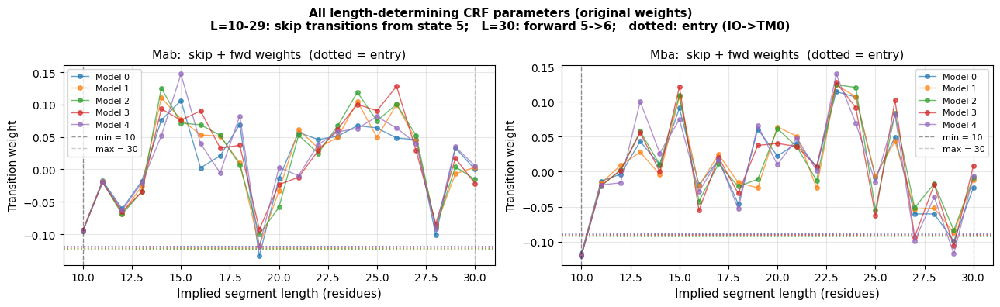

In [78]:
# -- All length-determining parameters: skips (5->26..7) + forward (5->6) --
# For min=10, max=30: 21 lengths, 21 weights -- skip(5,26)..skip(5,7), fwd(5,6)
# Uses original_transitions so plots are unaffected by post-hoc corrections.
# Entry transitions (IO -> TM0) shown as a horizontal dashed line per model.

import math

ENTRY_STATE = {
    'Mab': 'a_alpha',
    'Mba': 'b_alpha',
    'Bab': 'a_beta',
    'Bba': 'b_beta',
}

cfg = models.topology_models[0].crf_config
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, tm_type in zip(axes, ['Mab', 'Mba']):
    min_seg   = cfg.min_segment_lengths[tm_type]
    max_seg   = cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)

    skip_src   = cfg.crf_states[f'{tm_type}{start_seg - 1}']
    fwd_dst    = cfg.crf_states[f'{tm_type}{start_seg}']
    entry_src  = cfg.crf_states[ENTRY_STATE[tm_type]]
    entry_dst  = cfg.crf_states[f'{tm_type}0']

    js      = list(range(max_seg - end_seg, start_seg, -1))
    lengths = [start_seg + (max_seg - j) for j in js]
    js.append(start_seg)
    lengths.append(max_seg)

    for model_idx, orig in enumerate(original_transitions):
        weights = []
        for j in js[:-1]:
            weights.append(orig[skip_src, cfg.crf_states[f'{tm_type}{j}']].item())
        weights.append(orig[skip_src, fwd_dst].item())
        line, = ax.plot(lengths, weights, marker='o', markersize=4, linewidth=1,
                        alpha=0.7, label=f'Model {model_idx}')

        entry_w = orig[entry_src, entry_dst].item()
        ax.axhline(entry_w, color=line.get_color(), linewidth=1.2, linestyle=':',
                   alpha=0.7)

    ax.axvline(min_seg, color='black', linewidth=1, linestyle='--', alpha=0.4,
               label=f'min = {min_seg}')
    ax.axvline(max_seg, color='gray',  linewidth=1, linestyle='--', alpha=0.4,
               label=f'max = {max_seg}')
    ax.set_xlabel('Implied segment length (residues)', fontsize=11)
    ax.set_ylabel('Transition weight', fontsize=10)
    ax.set_title(f'{tm_type}:  skip + fwd weights  (dotted = entry)', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle(
    'All length-determining CRF parameters (original weights)\n'
    'L=10-29: skip transitions from state 5;   L=30: forward 5->6;   dotted: entry (IO->TM0)',
    fontweight='bold', fontsize=11,
)
plt.tight_layout()
plt.show()


---
## Second example — false positive single short TM segment

Comparison of original vs. corrected skip weights (L=10 → −0.4, L=11 → −0.05, Mab/Mba symmetrized) on a new sequence.

In [39]:
# ── Load A0A369NIV7 from UniProt ──────────────────────────────────────────────
# Training example — only model 0 is relevant (others saw this sequence too,
# but the user specifically flagged checkpoint 0).
import urllib.request, io

uniprot_id = "A0A369NIV7"
url = f"https://www.uniprot.org/uniprot/{uniprot_id}.fasta"
with urllib.request.urlopen(url) as r:
    fasta_text = r.read().decode()

record2   = next(SeqIO.parse(io.StringIO(fasta_text), "fasta"))
seq_id2   = uniprot_id
sequence2 = str(record2.seq)
print(f"{seq_id2}  ({len(sequence2)} aa)")
print(sequence2)

embedding2 = get_embedding(sequence2, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
mask2      = torch.ones(1, len(sequence2), device=DEVICE)

A0A369NIV7  (1017 aa)
MGNLTMSRRTFVKTAAITGAAAAAFGASTHTALAEETYSSVSGNDTVAVKTCCRGCGKMECGVKVIVQNGRAIRVEGDEGAFQSMGNCCTKSQSSIQAAYHPDRLHYPMKRTNPKGEEPGWQRISWDEAMQSIVDNFMDIKAKHGGEAIACQVGTSRIWCMHSESILKNMLETPNNVEAWQICKGPRHFATTMVSQFAMSWMETITRPKVYVQWGGASELSNYDDSCRTTVDVASRADVHISVDPRMANMGKEADYWQHLRPGTDGALALAWTNVIIEKKLYDELYVKKWTNAPFLVCEDMEPSGFPTVRTDGSYWDVKTALLKESDIKEGGSPYKFLVYDNNWEKLKAEGVEHEYGAFTWFNADQEGVIDETGGFWEGENYDSEKARQGREAAQDNLLPGQTQGWLPDPMPFDPAIDPALEGEFEITLKDGKTVKVKPVWEHYKARAAEYKPEVAAEITGIPASEIEAAATAYGTRIDPSTGYGNGGIQYMLAVEHFCSAIQNCRAFDNLVGITGNMDTPGGNRGPTIVPIDGDLQGFSAWAPGATTPPEEVNRKQIGIDKFPLLGWWQYWCDSHSLWDAVITGDPYPVRALWNESGNFMSQTNTTRAWEALCSLDFYVDLNLWHTPQNDTADIILPVAHWIELNSPRASQGSAGAMGATVKCVQPPAEAKYDPEIVMDLARRMNWKWTDEPGNEWPDINWQLDDSIKLLTDDELTYTTWHVENGKPTFERHGVPMAEVTPKYKTWDEYVKAFQEHGWWQAKDIEPRNWGTYRRYQTGAMRARDRVWGRLDYTAGKGIGDWKPGWFTPTMKQEIWSTVMESHHPDHPEWRLPTYTEPPHGPKDGDRIKEYPLTATTGRRIPVYFHSEHRQLPWCRELWPVPRVEINPKTAAEYGIEQGDWVWIETEWGKIREVADLYYGVKEDVINLEHTWWYPEVKDAGHGWQFSQVNQLIDHYAQDPHSGTSNLRAYQVKIYKAT

In [98]:
# -- Flexible weight correction function --
# mab_overrides / mba_overrides: {length: weight} for skip transitions
# entry_overrides: {tm_type: weight} for the IO->TM entry transition
# ab_weight: if not None, unlock and set a_alpha<->b_alpha direct transitions

import copy, math

ENTRY_STATE = {
    'Mab': 'a_alpha',
    'Mba': 'b_alpha',
    'Bab': 'a_beta',
    'Bba': 'b_beta',
}

def apply_corrected_weights(model, cfg,
                             mab_overrides={},
                             mba_overrides={},
                             entry_overrides={},
                             ab_weight=None):
    m = copy.deepcopy(model)
    T = m.crf.transitions.data

    for tm_type, overrides in [('Mab', mab_overrides), ('Mba', mba_overrides)]:
        if not overrides:
            continue
        min_seg   = cfg.min_segment_lengths[tm_type]
        max_seg   = cfg.max_segment_lengths[tm_type]
        start_seg = math.ceil(min_seg / 2)
        skip_src  = cfg.crf_states[f'{tm_type}{start_seg - 1}']
        js        = list(range(start_seg + 1, max_seg - math.floor(min_seg / 2) + 1))
        lengths   = [start_seg + (max_seg - j) for j in js]
        for target_L, target_w in overrides.items():
            if target_L in lengths:
                T[skip_src, cfg.crf_states[f'{tm_type}{js[lengths.index(target_L)]}']] = target_w
            else:
                print(f'Warning: L={target_L} out of range for {tm_type}, skipped.')

    for tm_type, new_w in entry_overrides.items():
        if tm_type not in ENTRY_STATE:
            print(f'Warning: unknown tm_type {tm_type!r} in entry_overrides, skipped.')
            continue
        T[cfg.crf_states[ENTRY_STATE[tm_type]], cfg.crf_states[f'{tm_type}0']] = new_w

    if ab_weight is not None:
        a = cfg.crf_states['a_alpha']
        b = cfg.crf_states['b_alpha']
        m.crf._constraint_mask.data[a, b] = 1.0
        m.crf._constraint_mask.data[b, a] = 1.0
        T[a, b] = ab_weight
        T[b, a] = ab_weight

    return m


MAB_OVERRIDES   = {10: -0.6, 11: -0.6, 12: -0.5}
MBA_OVERRIDES   = {10: -0.4, 11: -0.05}
ENTRY_OVERRIDES = {'Mab': -10.0, 'Mba': -10.0}
AB_WEIGHT       = -2.0


=== Original weights ===
  TM = [10]


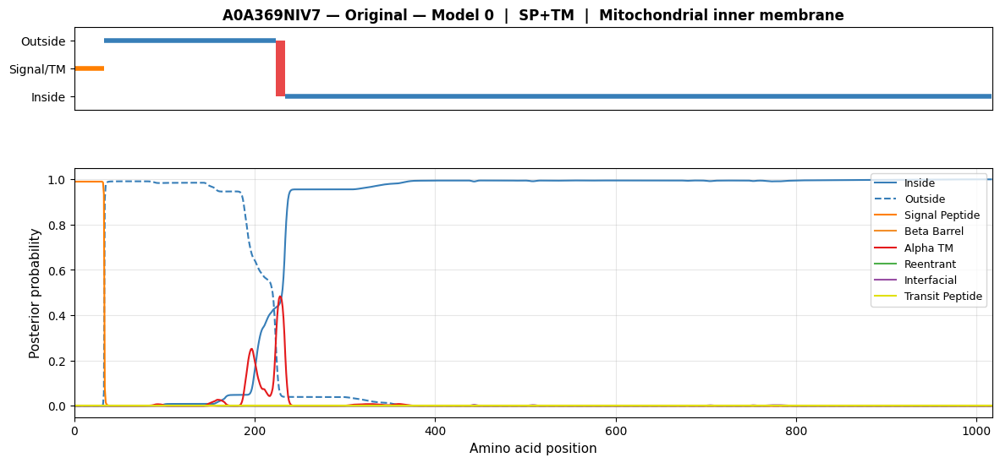


=== Corrected  Mab={10: -0.6, 11: -0.6, 12: -0.5}  Mba={10: -0.4, 11: -0.05} Entry={'Mab': -10.0, 'Mba': -10.0} === 
  TM = []


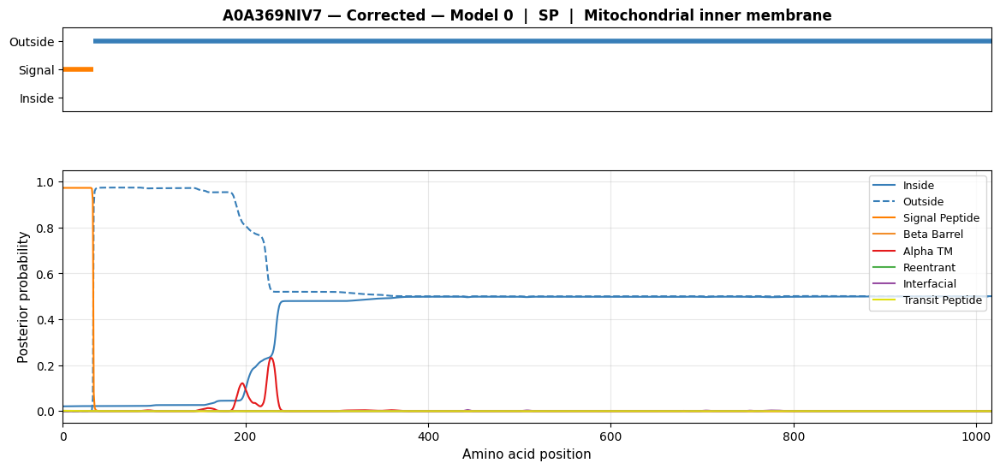

In [88]:
# ── Predict with model 0 only (training example) ─────────────────────────────
# Edit MAB_OVERRIDES / MBA_OVERRIDES in the cell above and re-run both cells.
MODEL_IDX = 0

def predict_single(sequence, embedding, mask, model):
    with torch.no_grad():
        emiss    = model._get_network_emissions(embedding, mask)
        if TEMPERATURE != 1.0:
            emiss = emiss * TEMPERATURE
        paths    = model.crf.decode(emiss, mask.byte())
        topo_arr = model.simplify_labels(paths)[0]
        topo_str = model.crf_config.get_string_from_labels(topo_arr)
        raw_marg = model.crf.compute_marginal_probabilities(emiss, mask, truncate=False)
        marg     = simplify_marginals_split_io(model.crf_config, raw_marg[0])
    return topo_str, marg

from itertools import groupby as _gb

# ── Restore originals before each run ─────────────────────────────────────────
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

print("=== Original weights ===")
topo2_orig, marg2_orig = predict_single(sequence2, embedding2, mask2,
                                        models.topology_models[MODEL_IDX])
print(f"  TM = {[len(list(g)) for lbl,g in _gb(topo2_orig) if lbl=='M']}")
plot_inline(f"{seq_id2} — Original — Model 0", sequence2, topo2_orig, mem_names, marg2_orig)

print(f"\n=== Corrected  Mab={MAB_OVERRIDES}  Mba={MBA_OVERRIDES} Entry={ENTRY_OVERRIDES} === ")
model0_corr = apply_corrected_weights(models.topology_models[MODEL_IDX], cfg,
                                      mab_overrides=MAB_OVERRIDES,
                                      mba_overrides=MBA_OVERRIDES,
                                      entry_overrides=ENTRY_OVERRIDES)
topo2_corr, marg2_corr = predict_single(sequence2, embedding2, mask2, model0_corr)
print(f"  TM = {[len(list(g)) for lbl,g in _gb(topo2_corr) if lbl=='M']}")
plot_inline(f"{seq_id2} — Corrected — Model 0", sequence2, topo2_corr, mem_names, marg2_corr)

=== Truncated to 480 aa (full-sequence ESM embedding) ===
  TM = []


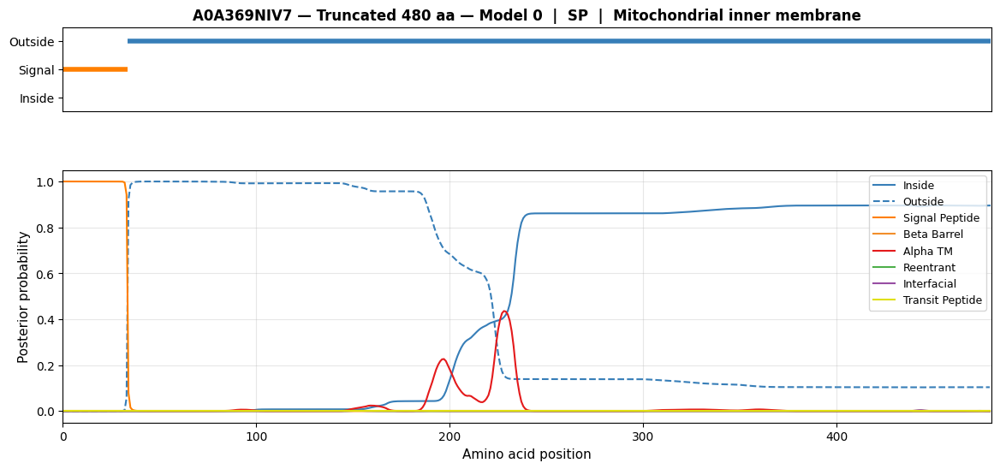

In [62]:
# ── Reproduce Felix truncation experiment ─────────────────────────────────────
# Embed the full sequence (ESM sees all 1017 aa) but pass only the first
# TRUNC_LEN positions to the network + CRF.  Felix found the false positive
# disappears when truncating to ~400 residues.
TRUNC_LEN = 480

embedding2_trunc = embedding2[:, :TRUNC_LEN, :]
mask2_trunc      = mask2[:, :TRUNC_LEN]
sequence2_trunc  = sequence2[:TRUNC_LEN]

# Restore original weights before running
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

print(f"=== Truncated to {TRUNC_LEN} aa (full-sequence ESM embedding) ===")
topo2_trunc, marg2_trunc = predict_single(sequence2_trunc, embedding2_trunc,
                                           mask2_trunc,
                                           models.topology_models[MODEL_IDX])
print(f"  TM = {[len(list(g)) for lbl,g in _gb(topo2_trunc) if lbl=='M']}")
plot_inline(f"{seq_id2} — Truncated {TRUNC_LEN} aa — Model 0",
            sequence2_trunc, topo2_trunc, mem_names, marg2_trunc)


=== Exp B: full BiLSTM + CRF on first 480 aa ===
  TM = []


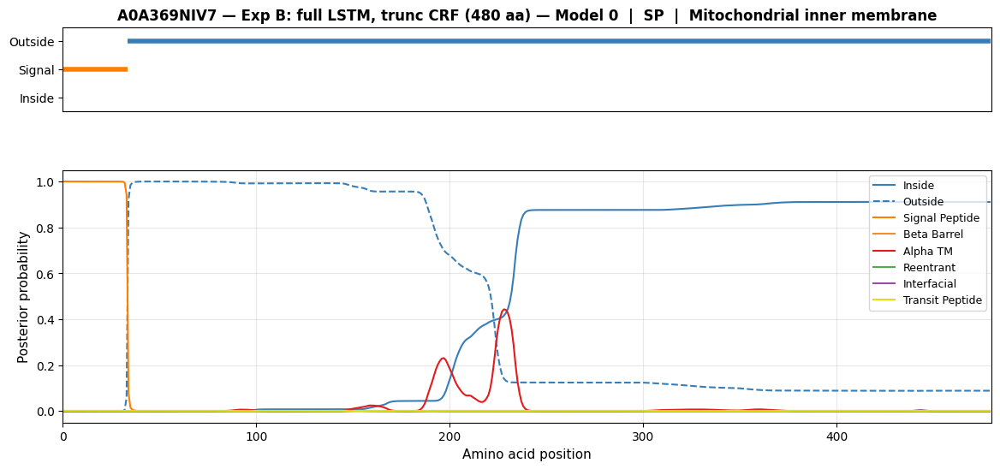

In [63]:
# ── Experiment B: full-sequence BiLSTM, truncated CRF decoding ───────────────
# BiLSTM sees all 1017 aa (full bidirectional context), but CRF decodes
# only the first TRUNC_LEN positions.  Isolates whether the fix comes from
# the CRF/decoding side or from the BiLSTM losing tail context.
TRUNC_LEN = 480

# Restore original weights
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

top_model = models.topology_models[MODEL_IDX]
with torch.no_grad():
    emiss_full = top_model._get_network_emissions(embedding2, mask2)   # full sequence
    emiss_trunc = emiss_full[:, :TRUNC_LEN, :]                         # slice emissions
    mask2_trunc_B = mask2[:, :TRUNC_LEN]

    paths = top_model.crf.decode(emiss_trunc, mask2_trunc_B.byte())
    topo_arr = top_model.simplify_labels(paths)[0]
    topo2_expB = top_model.crf_config.get_string_from_labels(topo_arr)
    raw_marg = top_model.crf.compute_marginal_probabilities(emiss_trunc, mask2_trunc_B, truncate=False)
    marg2_expB = simplify_marginals_split_io(top_model.crf_config, raw_marg[0])

print(f"=== Exp B: full BiLSTM + CRF on first {TRUNC_LEN} aa ===")
print(f"  TM = {[len(list(g)) for lbl,g in _gb(topo2_expB) if lbl=='M']}")
plot_inline(f"{seq_id2} — Exp B: full LSTM, trunc CRF ({TRUNC_LEN} aa) — Model 0",
            sequence2[:TRUNC_LEN], topo2_expB, mem_names, marg2_expB)


In [66]:
# ── Log-likelihood: Viterbi (false positive) vs no-TM path ───────────────────
# "Correct" path = first 100 positions same as Viterbi, rest = b_alpha (outside).

# Restore original weights
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

top_model = models.topology_models[MODEL_IDX]
with torch.no_grad():
    emiss2_full = top_model._get_network_emissions(embedding2, mask2)

    # --- Viterbi path ---
    viterbi_raw = top_model.crf.decode(emiss2_full, mask2.byte())  # list of lists
    tags_viterbi = torch.tensor(viterbi_raw, device=emiss2_full.device)  # (1, seq_len)
    ll_viterbi = top_model.crf(emiss2_full, tags=tags_viterbi, mask=mask2.byte(), reduction='none').item()

    # --- No-TM path: first 100 labels from Viterbi, rest = b_alpha (outside) ---
    b_alpha_idx = top_model.crf_config.crf_states["b_alpha"]
    tags_notm = tags_viterbi.clone()
    tags_notm[0, 100:] = b_alpha_idx
    ll_notm = top_model.crf(emiss2_full, tags=tags_notm, mask=mask2.byte(), reduction='none').item()

simple_viterbi = top_model.simplify_labels(viterbi_raw)
topo2_full = top_model.crf_config.get_string_from_labels(simple_viterbi[0])
tm_segs = [len(list(g)) for lbl, g in _gb(topo2_full) if lbl == 'M']

print(f"Viterbi topology : TM segments = {tm_segs}")
print(f"  LL (Viterbi)   = {ll_viterbi:.2f}")
print(f"  LL (no-TM)     = {ll_notm:.2f}")
print(f"  Delta LL       = {ll_viterbi - ll_notm:.2f}  (positive = CRF prefers TM path)")


Viterbi topology : TM segments = [10]
  LL (Viterbi)   = -2.88
  LL (no-TM)     = -10.27
  Delta LL       = 7.39  (positive = CRF prefers TM path)


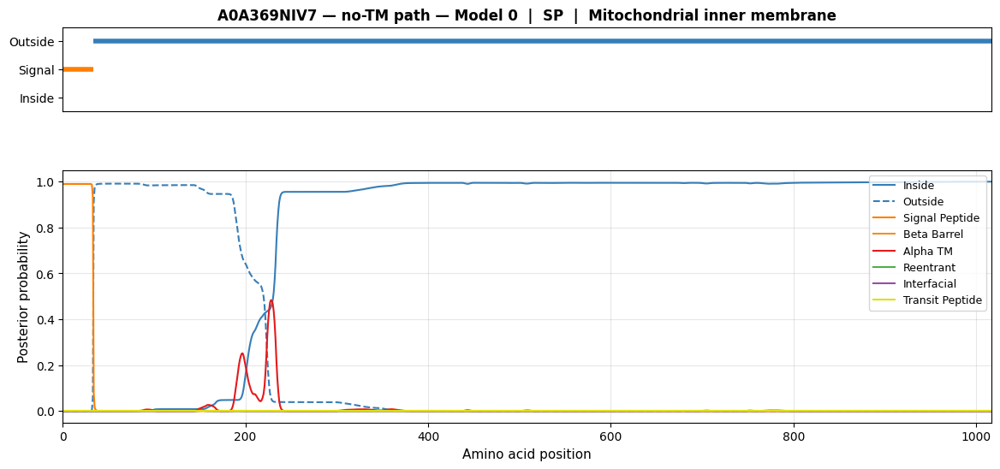

In [67]:
# ── Visualise the no-TM path ─────────────────────────────────────────────────
simple_notm = top_model.simplify_labels(tags_notm.tolist())
topo2_notm  = top_model.crf_config.get_string_from_labels(simple_notm[0])
with torch.no_grad():
    raw_marg2_notm = top_model.crf.compute_marginal_probabilities(emiss2_full, mask2, truncate=False)
marg2_notm = simplify_marginals_split_io(top_model.crf_config, raw_marg2_notm[0])
plot_inline(f"{seq_id2} — no-TM path — Model 0", sequence2, topo2_notm, mem_names, marg2_notm)


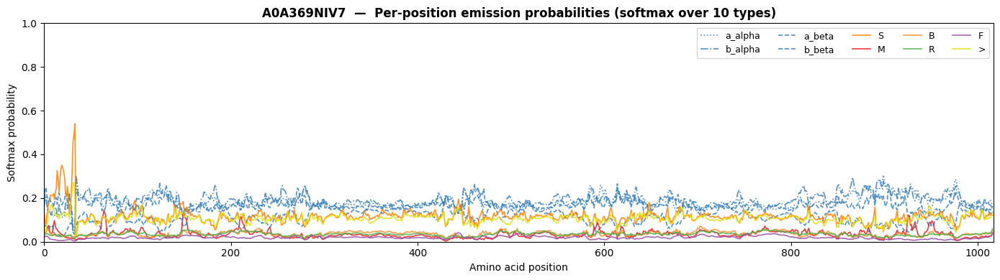

In [75]:
# ── Softmax emission probabilities along full A0A369NIV7 sequence ─────────────
# The network outputs 10 unique logits (one per label type); all CRF states of
# the same type share the same score.  Softmax across the 10 types gives a
# per-position probability distribution over label categories.
import torch.nn.functional as F

EMISSION_LABELS = ['a_alpha', 'b_alpha', 'a_beta', 'b_beta', 'S', 'M', 'B', 'R', 'F', '>']
EMISSION_COLORS = [
    COLORS['inside'], COLORS['outside'], COLORS['inside'], COLORS['outside'],
    COLORS['signal'], COLORS['alpha'], COLORS['beta'],
    COLORS['reentrant'], COLORS['interfacial'], COLORS['transit'],
]
EMISSION_LS = [':', '-.', '--', '--', '-', '-', '-', '-', '-', '-']

# Pick one representative CRF state per label type (all states of a type share the same logit)
cfg2 = top_model.crf_config
rep_indices = [
    cfg2.crf_states['a_alpha'],
    cfg2.crf_states['b_alpha'],
    cfg2.crf_states['a_beta'],
    cfg2.crf_states['b_beta'],
    cfg2.crf_states['S0'],
    cfg2.helix_state_inds[0],
    cfg2.beta_state_inds[0],
    cfg2.reentrant_state_inds[0],
    cfg2.interfacial_state_inds[0],
    cfg2.transit_state_inds[0],
]

logits_10 = emiss2_full[0, :, rep_indices].cpu()   # (seq_len, 10)
probs_10  = F.softmax(logits_10, dim=-1).numpy()      # (seq_len, 10)

x2 = np.arange(len(sequence2))
fig, ax = plt.subplots(figsize=(14, 4))
for i, (label, color, ls) in enumerate(zip(EMISSION_LABELS, EMISSION_COLORS, EMISSION_LS)):
    ax.plot(x2, probs_10[:, i], color=color, linewidth=1.2, linestyle=ls, label=label, alpha=0.85)
ax.set_xlim(0, len(sequence2))
ax.set_ylim(0, 1)
ax.set_xlabel('Amino acid position')
ax.set_ylabel('Softmax probability')
ax.set_title(f'{seq_id2}  —  Per-position emission probabilities (softmax over 10 types)', fontweight='bold')
ax.legend(ncol=5, fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()


  TM = []


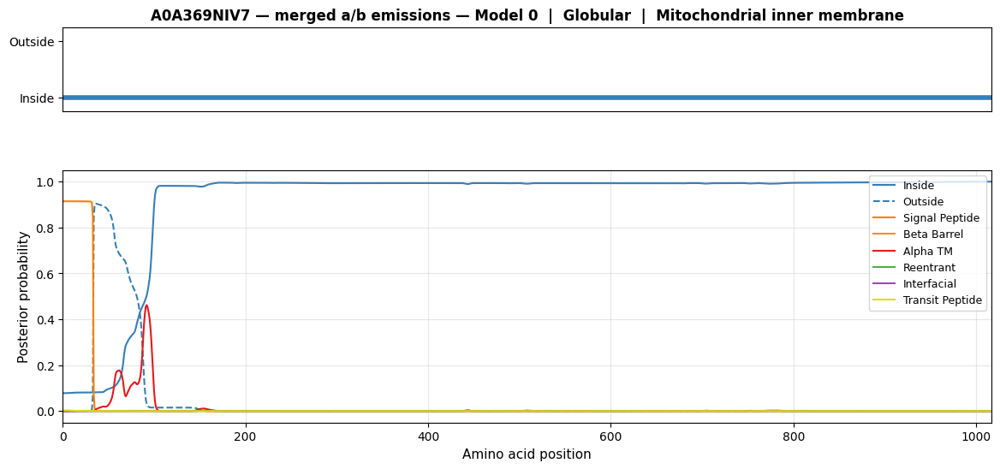

In [76]:
# ── Experiment: merge a_alpha/b_alpha (and a_beta/b_beta) emissions ───────────
# Replace each pair with their average so the CRF cannot distinguish inside
# from outside via emissions alone.  Only TM emission evidence can drive a
# topology prediction.

with torch.no_grad():
    emiss2_merged = emiss2_full.clone()

    a_idx = cfg2.crf_states['a_alpha']
    b_idx = cfg2.crf_states['b_alpha']
    ab_mean = (emiss2_merged[:, :, a_idx] + emiss2_merged[:, :, b_idx]) / 2
    emiss2_merged[:, :, a_idx] = ab_mean
    emiss2_merged[:, :, b_idx] = ab_mean

    ab_idx = cfg2.crf_states['a_beta']
    bb_idx = cfg2.crf_states['b_beta']
    abeta_mean = (emiss2_merged[:, :, ab_idx] + emiss2_merged[:, :, bb_idx]) / 2
    emiss2_merged[:, :, ab_idx] = abeta_mean
    emiss2_merged[:, :, bb_idx] = abeta_mean

    paths_merged = top_model.crf.decode(emiss2_merged, mask2.byte())
    simple_merged = top_model.simplify_labels(paths_merged)
    topo2_merged  = top_model.crf_config.get_string_from_labels(simple_merged[0])
    raw_marg_merged = top_model.crf.compute_marginal_probabilities(emiss2_merged, mask2, truncate=False)
    marg2_merged = simplify_marginals_split_io(top_model.crf_config, raw_marg_merged[0])

print(f"  TM = {[len(list(g)) for lbl,g in _gb(topo2_merged) if lbl=='M']}")
plot_inline(f"{seq_id2} — merged a/b emissions — Model 0", sequence2, topo2_merged, mem_names, marg2_merged)


In [89]:
# -- Experiment: allow direct a_alpha <-> b_alpha transitions ----------------
# Adds two new grammar transitions (a->b and b->a) so the CRF can explain
# inside/outside asymmetry without inserting a TM segment.
# Sweep over transition weights to find the operating range.

# Restore original weights
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

top_model = models.topology_models[MODEL_IDX]
a_idx = cfg2.crf_states['a_alpha']
b_idx = cfg2.crf_states['b_alpha']

with torch.no_grad():
    emiss2_full = top_model._get_network_emissions(embedding2, mask2)

for ab_weight in [0.0, -1.0, -2.0, -3.0, -5.0]:
    m = copy.deepcopy(top_model)

    # Unlock the constraint mask for a->b and b->a
    m.crf._constraint_mask.data[a_idx, b_idx] = 1.0
    m.crf._constraint_mask.data[b_idx, a_idx] = 1.0

    # Set the transition weights
    m.crf.transitions.data[a_idx, b_idx] = ab_weight
    m.crf.transitions.data[b_idx, a_idx] = ab_weight

    with torch.no_grad():
        paths = m.crf.decode(emiss2_full, mask2.byte())
        simple = m.simplify_labels(paths)
        topo   = m.crf_config.get_string_from_labels(simple[0])

    tm_segs = [len(list(g)) for lbl, g in _gb(topo) if lbl == 'M']
    n_ab = sum(1 for a, b in zip(topo, topo[1:]) if a in 'ab' and b in 'ab' and a != b)
    print(f'  weight={ab_weight:5.1f}  TM={tm_segs}  direct a<->b flips={n_ab}')


  weight=  0.0  TM=[]  direct a<->b flips=49
  weight= -1.0  TM=[]  direct a<->b flips=5
  weight= -2.0  TM=[]  direct a<->b flips=3
  weight= -3.0  TM=[]  direct a<->b flips=3
  weight= -5.0  TM=[]  direct a<->b flips=1


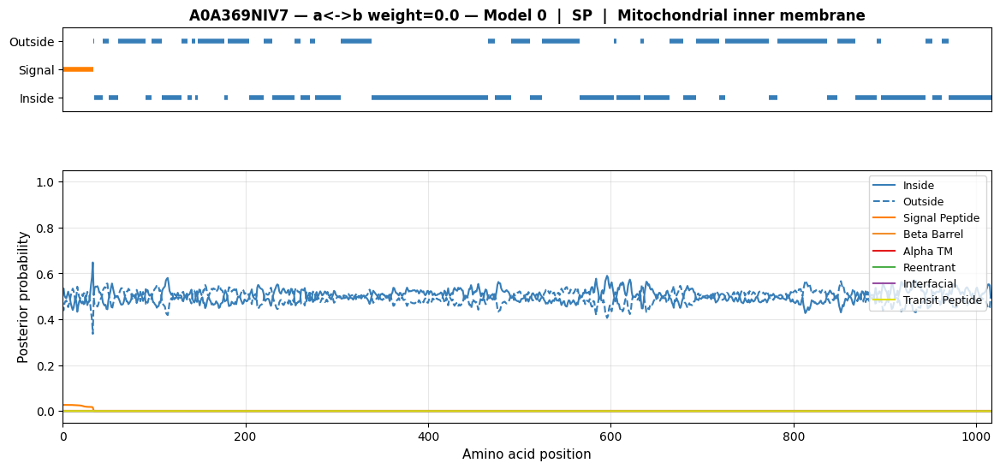

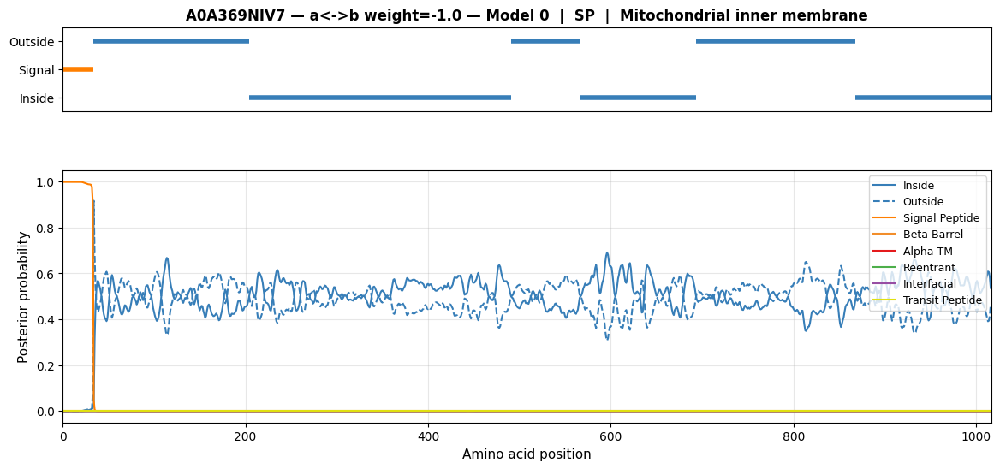

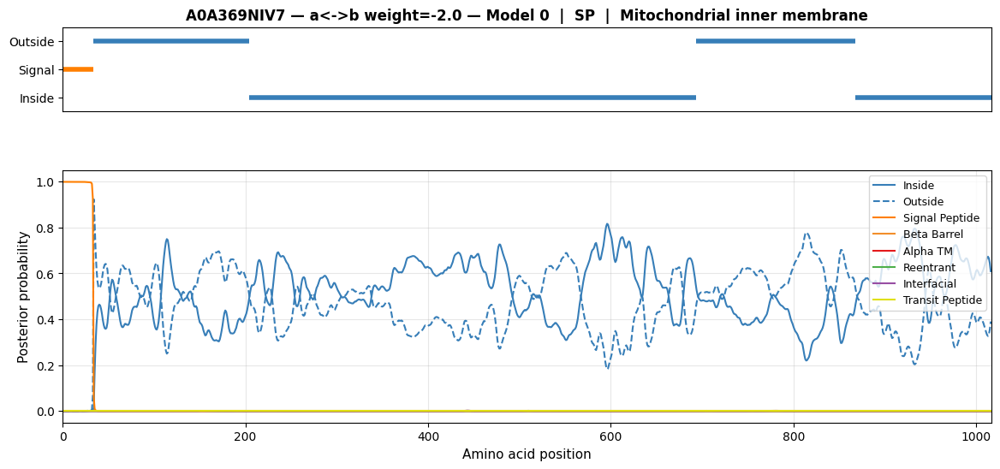

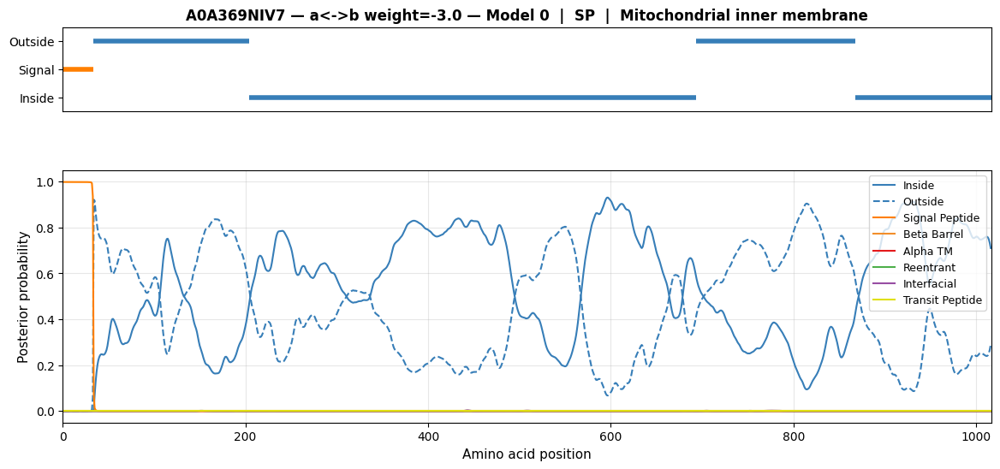

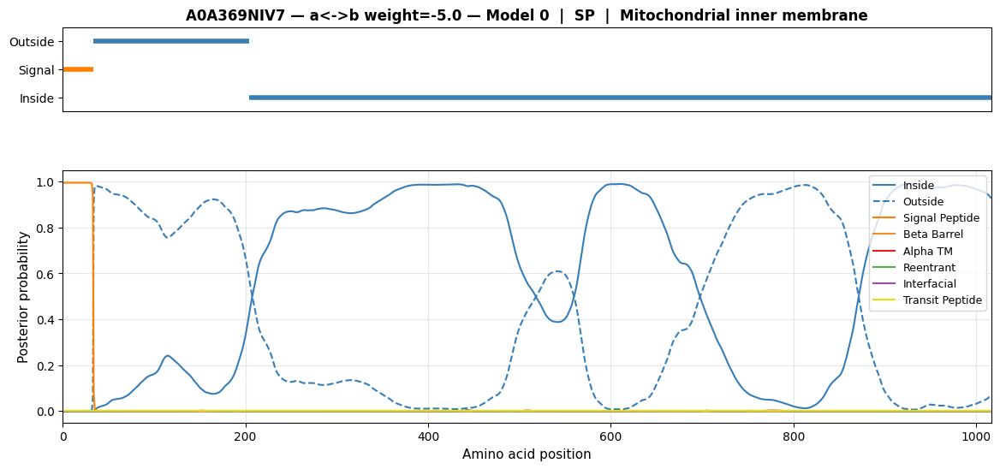

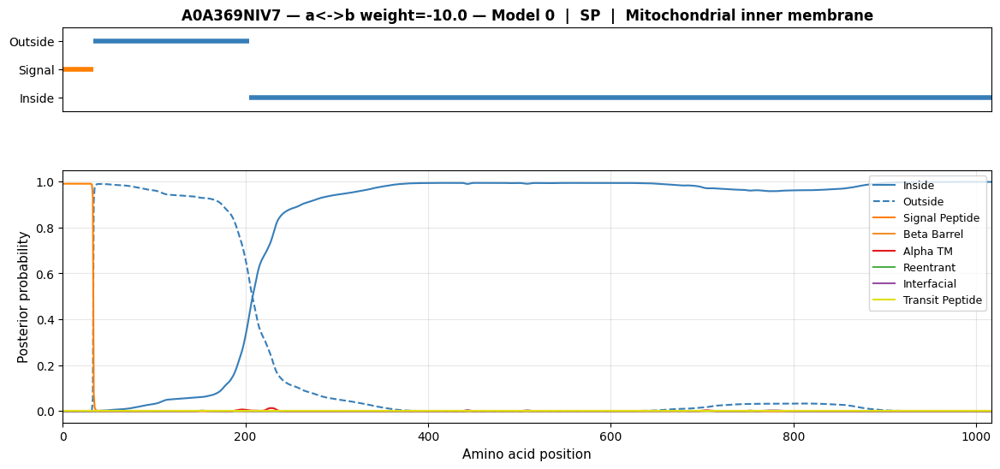

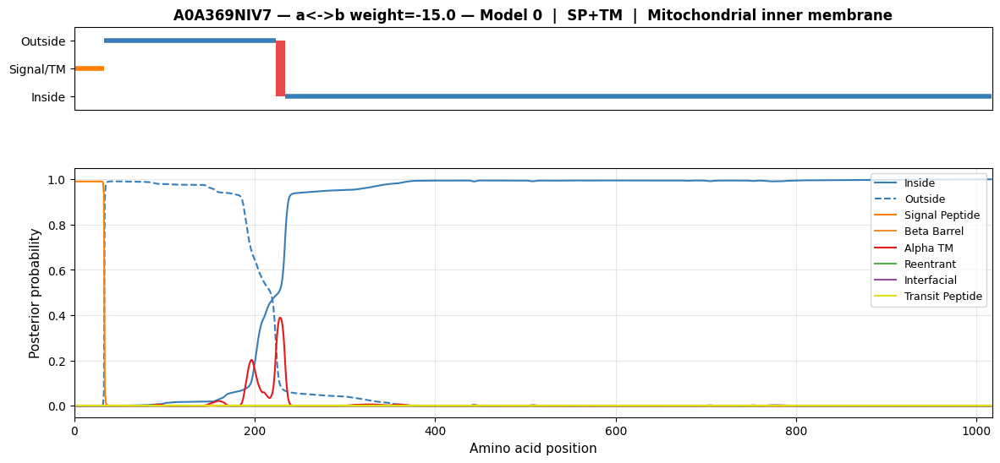

In [92]:
# -- Plot topologies for each a<->b weight -----------------------------------
for ab_weight in [0.0, -1.0, -2.0, -3.0, -5.0, -10.0, -15.0]:
    m = copy.deepcopy(top_model)
    m.crf._constraint_mask.data[a_idx, b_idx] = 1.0
    m.crf._constraint_mask.data[b_idx, a_idx] = 1.0
    m.crf.transitions.data[a_idx, b_idx] = ab_weight
    m.crf.transitions.data[b_idx, a_idx] = ab_weight

    with torch.no_grad():
        paths = m.crf.decode(emiss2_full, mask2.byte())
        simple = m.simplify_labels(paths)
        topo   = m.crf_config.get_string_from_labels(simple[0])
        raw_marg = m.crf.compute_marginal_probabilities(emiss2_full, mask2, truncate=False)
        marg = simplify_marginals_split_io(m.crf_config, raw_marg[0])

    plot_inline(f'{seq_id2} — a<->b weight={ab_weight} — Model 0',
                sequence2, topo, mem_names, marg)


Model 0  weight= -1.0  TM=[24, 26, 24, 10, 15, 28, 22]


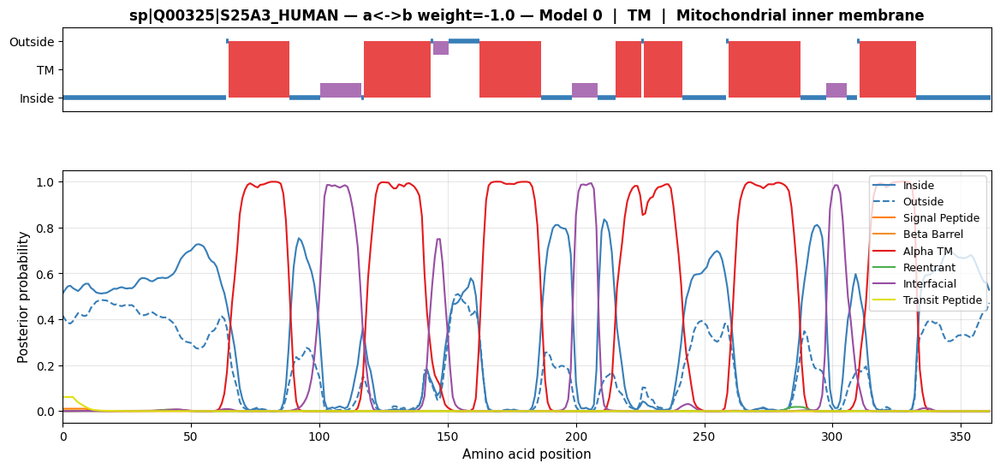

Model 1  weight= -1.0  TM=[28, 30, 25, 30, 28, 23]


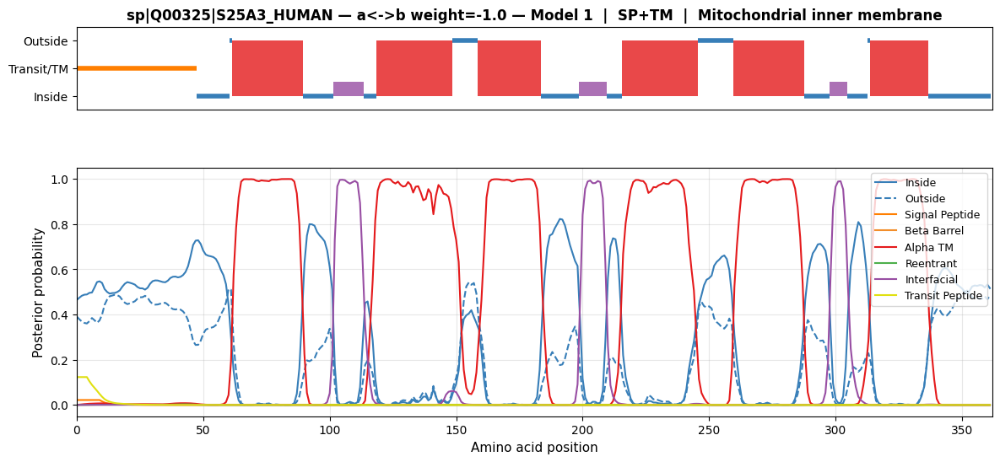

Model 2  weight= -1.0  TM=[23, 27, 23, 30, 28, 22]


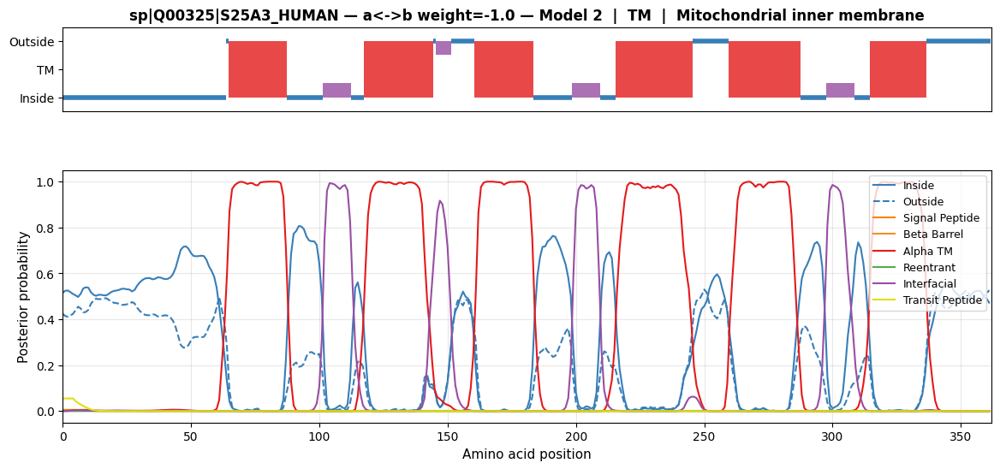

Model 3  weight= -1.0  TM=[25, 22, 26, 30, 28, 26]


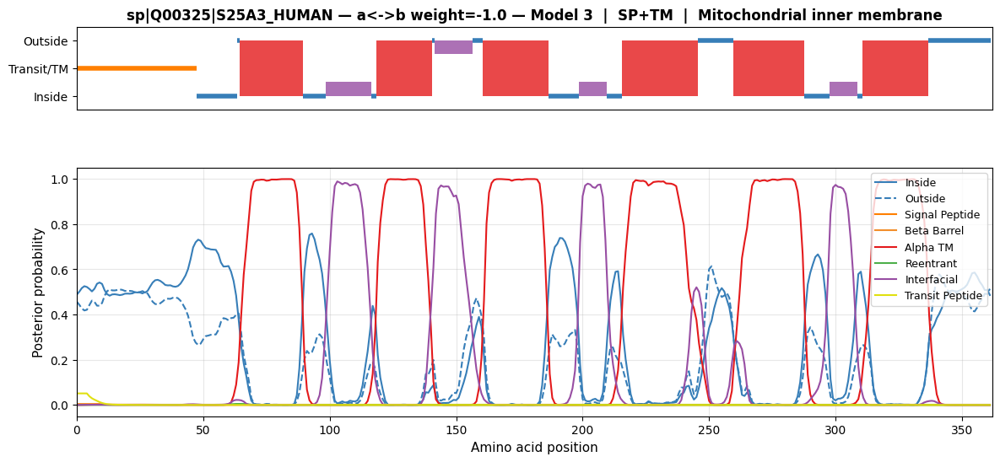

Model 4  weight= -1.0  TM=[20, 19, 23, 19, 22, 18]


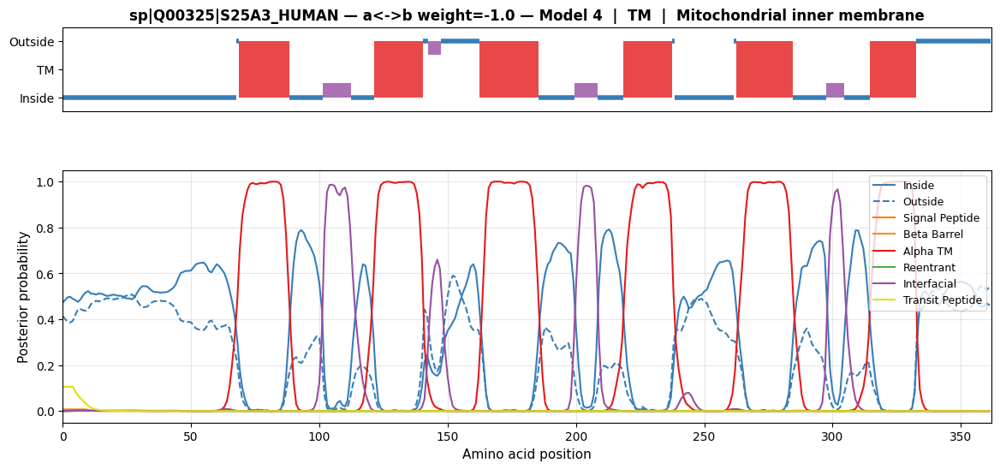

In [97]:
# -- Q00325: allowed a<->b transitions, all 5 models, sweep over weights -----
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

for model_idx in range(len(models.topology_models)):
    top_m = models.topology_models[model_idx]
    with torch.no_grad():
        emiss_q = top_m._get_network_emissions(embedding, mask)

    for ab_weight in [-1.0]:
        m = copy.deepcopy(top_m)
        m.crf._constraint_mask.data[a_idx, b_idx] = 1.0
        m.crf._constraint_mask.data[b_idx, a_idx] = 1.0
        m.crf.transitions.data[a_idx, b_idx] = ab_weight
        m.crf.transitions.data[b_idx, a_idx] = ab_weight

        with torch.no_grad():
            paths  = m.crf.decode(emiss_q, mask.byte())
            simple = m.simplify_labels(paths)
            topo   = m.crf_config.get_string_from_labels(simple[0])
            raw_marg = m.crf.compute_marginal_probabilities(emiss_q, mask, truncate=False)
            marg = simplify_marginals_split_io(m.crf_config, raw_marg[0])

        tm_segs = [len(list(g)) for lbl, g in _gb(topo) if lbl == 'M']
        print(f'Model {model_idx}  weight={ab_weight:5.1f}  TM={tm_segs}')
        plot_inline(f'{seq_id} — a<->b weight={ab_weight} — Model {model_idx}',
                    sequence, topo, mem_names, marg)


Model 0  TM=[24, 26, 24, 30, 28, 22]


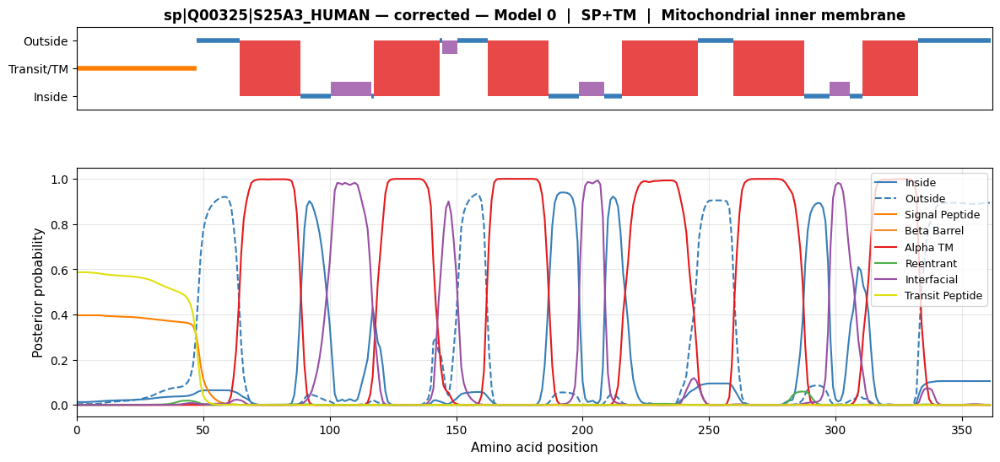

Model 1  TM=[28, 30, 25, 30, 28, 26]


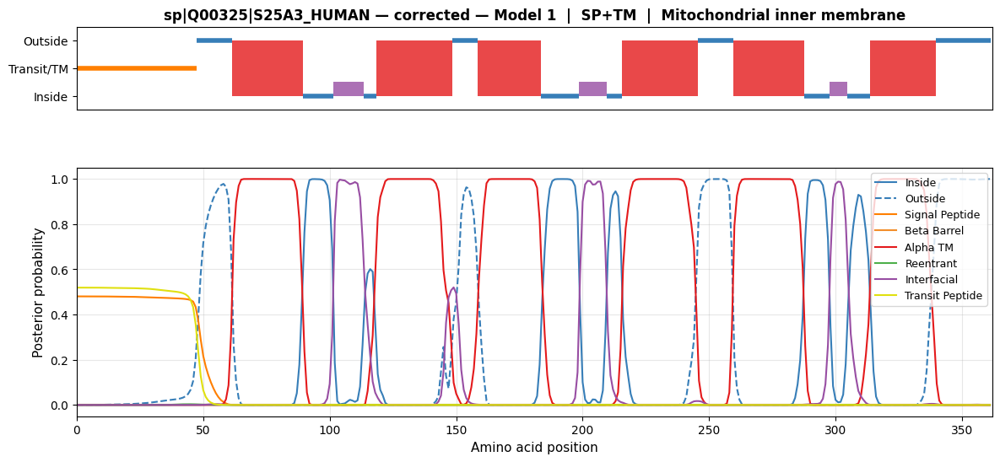

Model 2  TM=[26, 27, 23, 30, 28, 22]


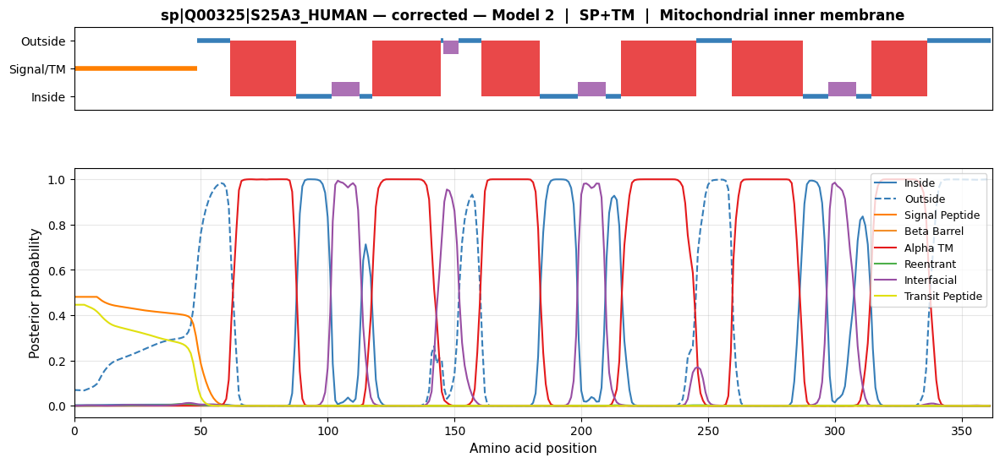

Model 3  TM=[25, 22, 26, 30, 28, 26]


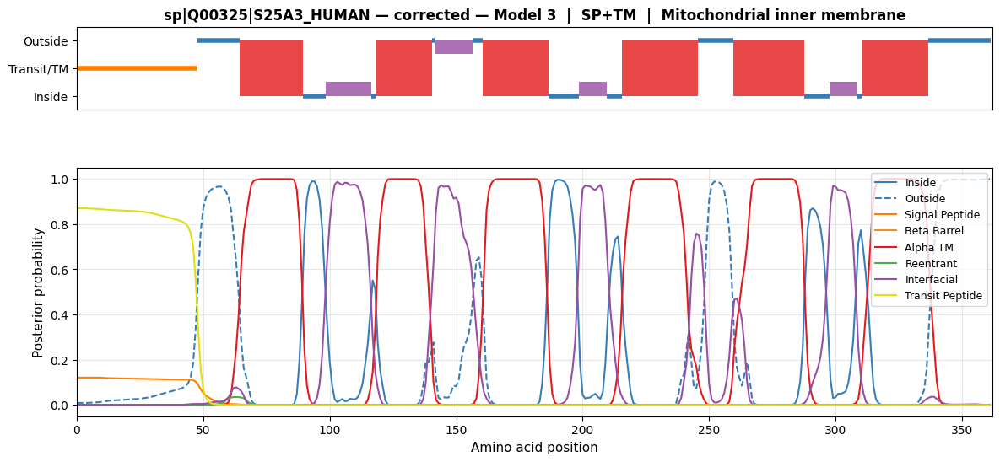

Model 4  TM=[23, 19, 23, 19, 23, 18]


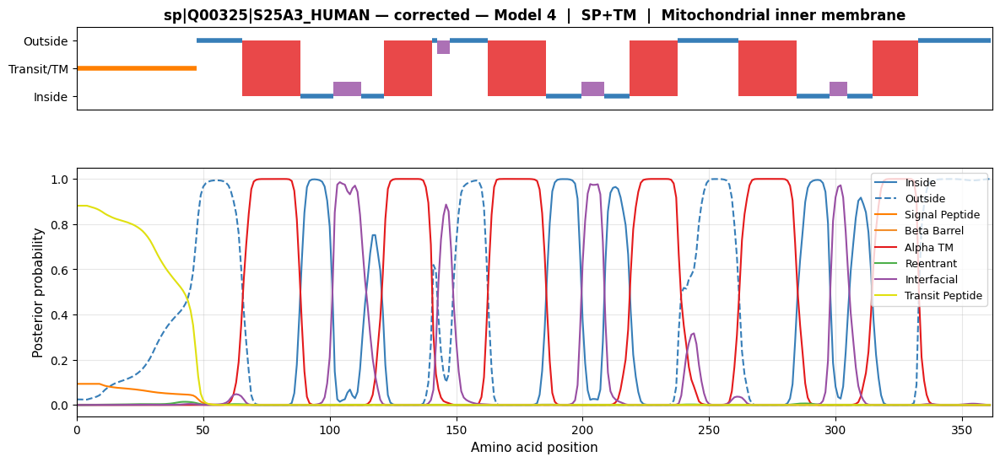

In [117]:
# -- Q00325: apply_corrected_weights for all 5 models ------------------------
MAB_OVERRIDES   = {} #{10: -0.6, 11: -0.6, 12: -0.5}
MBA_OVERRIDES   = {} #{10: -0.4, 11: -0.05}
ENTRY_OVERRIDES = {'Mab': -8.0, 'Mba': -8.0}
AB_WEIGHT       = None

for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

for model_idx in range(len(models.topology_models)):
    m = apply_corrected_weights(
        models.topology_models[model_idx], cfg,
        mab_overrides=MAB_OVERRIDES,
        mba_overrides=MBA_OVERRIDES,
        entry_overrides=ENTRY_OVERRIDES,
        ab_weight=AB_WEIGHT,
    )
    with torch.no_grad():
        emiss_q = m._get_network_emissions(embedding, mask)
        paths   = m.crf.decode(emiss_q, mask.byte())
        simple  = m.simplify_labels(paths)
        topo    = m.crf_config.get_string_from_labels(simple[0])
        raw_marg = m.crf.compute_marginal_probabilities(emiss_q, mask, truncate=False)
        marg    = simplify_marginals_split_io(m.crf_config, raw_marg[0])

    tm_segs = [len(list(g)) for lbl, g in _gb(topo) if lbl == 'M']
    print(f'Model {model_idx}  TM={tm_segs}')
    plot_inline(f'{seq_id} — corrected — Model {model_idx}', sequence, topo, mem_names, marg)


Model 0  TM=[]


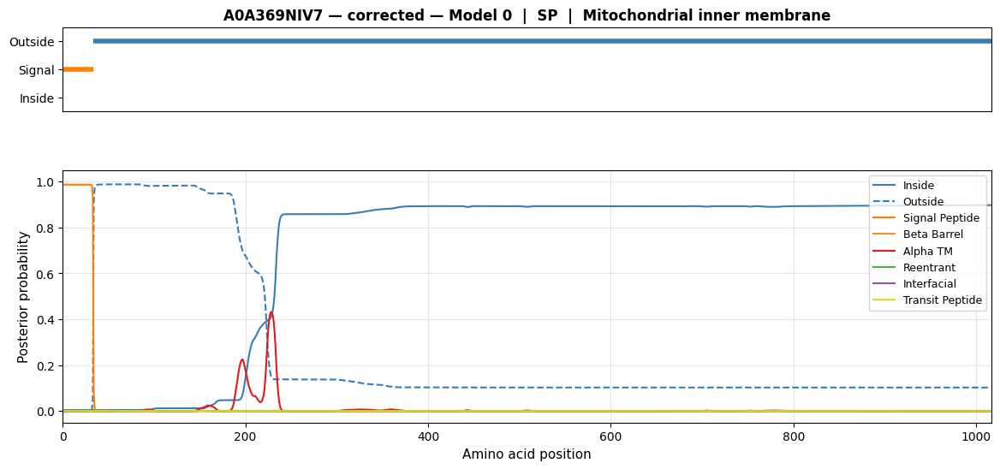

In [118]:
# -- A0A369NIV7: apply_corrected_weights for all 5 models --------------------
for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

for model_idx in [0]: #range(len(models.topology_models)):
    m = apply_corrected_weights(
        models.topology_models[model_idx], cfg,
        mab_overrides=MAB_OVERRIDES,
        mba_overrides=MBA_OVERRIDES,
        entry_overrides=ENTRY_OVERRIDES,
        ab_weight=AB_WEIGHT,
    )
    with torch.no_grad():
        emiss = m._get_network_emissions(embedding2, mask2)
        paths = m.crf.decode(emiss, mask2.byte())
        simple = m.simplify_labels(paths)
        topo   = m.crf_config.get_string_from_labels(simple[0])
        raw_marg = m.crf.compute_marginal_probabilities(emiss, mask2, truncate=False)
        marg = simplify_marginals_split_io(m.crf_config, raw_marg[0])

    tm_segs = [len(list(g)) for lbl, g in _gb(topo) if lbl == 'M']
    print(f'Model {model_idx}  TM={tm_segs}')
    plot_inline(f'{seq_id2} — corrected — Model {model_idx}', sequence2, topo, mem_names, marg)


In [132]:
# -- Test current overrides on sequences with few TM segments ----------------
# Uses the held-out model (cluster index) for each sequence — same as Felix.
import pandas as pd
from itertools import groupby as _igb

MAB_OVERRIDES   = {} #{10: -0.6, 11: -0.6, 12: -0.5}
MBA_OVERRIDES   = {} #{10: -0.4, 11: -0.05}
ENTRY_OVERRIDES = {'Mab': -8.0, 'Mba': -8.0}
AB_WEIGHT       = None

def count_tm(s):
    return sum(1 for lbl, _ in _igb(s) if lbl == 'M') if isinstance(s, str) else 0

df = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df['n_tm_true']  = df['label'].apply(count_tm)
df['n_tm_felix'] = df['pred_topology_deeptm'].apply(count_tm)

few_tm = df[(df['protein_type'] == 'M') & (df['n_tm_true'].isin([1, 2]))]
sample = pd.concat([
    few_tm[few_tm['n_tm_true'] == n].sample(5, random_state=42) for n in [1, 2]
]).reset_index(drop=True)
print(f'Testing {len(sample)} sequences  (1-TM: 5, 2-TM: 5)  — WITH overrides')
print(f'{"identifier":25s}  true  felix  held-out  match_felix?')
print('-' * 65)

for _, row in sample.iterrows():
    seq      = row['sequence']
    n_true   = row['n_tm_true']
    n_felix  = row['n_tm_felix']
    fold     = int(row['cluster'])  # held-out model index

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m = apply_corrected_weights(
        models.topology_models[fold], cfg,
        mab_overrides=MAB_OVERRIDES,
        mba_overrides=MBA_OVERRIDES,
        entry_overrides=ENTRY_OVERRIDES,
        ab_weight=AB_WEIGHT,
    )
    with torch.no_grad():
        em    = m._get_network_emissions(emb, msk)
        paths = m.crf.decode(em, msk.byte())
        topo  = m.crf_config.get_string_from_labels(m.simplify_labels(paths)[0])
    n_ours = count_tm(topo)

    match = 'OK' if n_ours == n_felix else 'DIFF'
    print(f"{row['identifier']:25s}  {n_true:4d}  {n_felix:5d}  {n_ours:8d}  {match}")


Testing 10 sequences  (1-TM: 5, 2-TM: 5)  — WITH overrides
identifier                 true  felix  held-out  match_felix?
-----------------------------------------------------------------
>Q8YVQ2|M|7                   1      1         1  OK
>A0A480KM09|M|5               1      1         1  OK
>W5QF73|M|5                   1      1         1  OK
>P50369|M|7                   1      1         1  OK
>O50335|M|3                   1      1         1  OK
>G0S812|M|5                   2      2         2  OK
>A0A096P8E8|M|7               2      2         1  DIFF
>U5NME9|M|2                   2      2         1  DIFF
>A0A1D8NGI5|M|5               2      2         2  OK
>P40540|M|6                   2      2         2  OK


In [131]:
# -- Same test with original model weights (no overrides) --------------------
print(f'Testing {len(sample)} sequences  — WITHOUT overrides')
print(f'{"identifier":25s}  true  felix  held-out  match_felix?')
print('-' * 65)

for _, row in sample.iterrows():
    seq     = row['sequence']
    n_true  = row['n_tm_true']
    n_felix = row['n_tm_felix']
    fold    = int(row['cluster'])

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_ours = count_tm(topo)

    match = 'OK' if n_ours == n_felix else 'DIFF'
    print(f"{row['identifier']:25s}  {n_true:4d}  {n_felix:5d}  {n_ours:8d}  {match}")


Testing 10 sequences  — WITHOUT overrides
identifier                 true  felix  held-out  match_felix?
-----------------------------------------------------------------
>Q8YVQ2|M|7                   1      1         1  OK
>A0A480KM09|M|5               1      1         1  OK
>W5QF73|M|5                   1      1         1  OK
>P50369|M|7                   1      1         1  OK
>O50335|M|3                   1      1         1  OK
>G0S812|M|5                   2      2         2  OK
>A0A096P8E8|M|7               2      2         2  OK
>U5NME9|M|2                   2      2         2  OK
>A0A1D8NGI5|M|5               2      2         2  OK
>P40540|M|6                   2      2         2  OK


In [154]:
MAB_OVERRIDES   = {} #{10: -0.6, 11: -0.6, 12: -0.5}
MBA_OVERRIDES   = {} #{10: -0.4, 11: -0.05}
ENTRY_OVERRIDES = {'Mab': -3.0, 'Mba': -3.0}
AB_WEIGHT       = None

In [138]:
# -- Systematic sweep: M-type sequences with 1-4 true TM segments ------------
# For each sequence, run held-out model with and without overrides.
# Summarise: how many sequences get fewer / same / more TM predicted.

df2 = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df2['n_tm_true']  = df2['label'].apply(count_tm)
df2['n_tm_felix'] = df2['pred_topology_deeptm'].apply(count_tm)

sweep = df2[df2['protein_type'] == 'M'].copy()
print(f'Sequences to test: {len(sweep)}  (all TM counts, pure M-type)')
print(sweep['n_tm_true'].value_counts().sort_index().to_string())
print()

results = []
for i, (_, row) in enumerate(sweep.iterrows()):
    seq    = row['sequence']
    n_true = row['n_tm_true']
    fold   = int(row['cluster'])

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    # --- original ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_orig = count_tm(topo)

    # --- overrides ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m = apply_corrected_weights(
        models.topology_models[fold], cfg,
        mab_overrides=MAB_OVERRIDES,
        mba_overrides=MBA_OVERRIDES,
        entry_overrides=ENTRY_OVERRIDES,
        ab_weight=AB_WEIGHT,
    )
    with torch.no_grad():
        em    = m._get_network_emissions(emb, msk)
        paths = m.crf.decode(em, msk.byte())
        topo  = m.crf_config.get_string_from_labels(m.simplify_labels(paths)[0])
    n_over = count_tm(topo)

    results.append({'AC': row.get('AC', row['identifier']), 'n_true': n_true,
                    'n_orig': n_orig, 'n_over': n_over})
    if (i + 1) % 20 == 0:
        print(f'  {i+1}/{len(sweep)} done...')

res = pd.DataFrame(results)

print()
print(f'{"n_tm_true":>10} {"n_seqs":>8} | {"fewer(orig)":>11} {"same(orig)":>11} {"more(orig)":>11} | {"fewer(over)":>11} {"same(over)":>11} {"more(over)":>11}')
print('-' * 95)
for n, grp in res.groupby('n_true'):
    fewer_orig = (grp['n_orig'] < grp['n_true']).sum()
    same_orig  = (grp['n_orig'] == grp['n_true']).sum()
    more_orig  = (grp['n_orig'] > grp['n_true']).sum()
    fewer_over = (grp['n_over'] < grp['n_true']).sum()
    same_over  = (grp['n_over'] == grp['n_true']).sum()
    more_over  = (grp['n_over'] > grp['n_true']).sum()
    print(f'{n:>10} {len(grp):>8} | {fewer_orig:>11} {same_orig:>11} {more_orig:>11} | {fewer_over:>11} {same_over:>11} {more_over:>11}')

# Show the cases where override predicts fewer than original
new_fn = res[(res['n_over'] < res['n_true']) & (res['n_orig'] >= res['n_true'])]
if len(new_fn):
    print(f'\nNew false negatives introduced by override ({len(new_fn)} sequences):')
    print(new_fn.to_string(index=False))
else:
    print('\nNo new false negatives introduced by override.')


Sequences to test: 449  (all TM counts, pure M-type)
n_tm_true
1     195
2      69
3      37
4      30
5      14
6      26
7      20
8       9
9       5
10     11
11      5
12     17
13      2
14      8
15      1

  20/449 done...
  40/449 done...
  60/449 done...
  80/449 done...
  100/449 done...
  120/449 done...
  140/449 done...
  160/449 done...
  180/449 done...
  200/449 done...
  220/449 done...
  240/449 done...
  260/449 done...
  280/449 done...
  300/449 done...
  320/449 done...
  340/449 done...
  360/449 done...
  380/449 done...
  400/449 done...
  420/449 done...
  440/449 done...

 n_tm_true   n_seqs | fewer(orig)  same(orig)  more(orig) | fewer(over)  same(over)  more(over)
-----------------------------------------------------------------------------------------------
         1      195 |          15         165          15 |          26         156          13
         2       69 |           2          62           5 |           2          62           5
         

In [143]:
# -- Ground truth + original prediction overview table -----------------------
# Uses pred_topology_deeptm from CSV (held-out cross-val predictions).

dfo = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)

def count_seg(s, lbl='M'):
    return sum(1 for l, _ in _igb(s) if l == lbl) if isinstance(s, str) else 0

dfo['n_tm_true']  = dfo.apply(lambda r: count_seg(r['label'], 'B') if r.get('protein_type','') == 'B' else count_seg(r['label']), axis=1)
dfo['n_tm_pred']  = dfo.apply(lambda r: count_seg(r['pred_topology_deeptm'], 'B') if r.get('protein_type','') == 'B' else count_seg(r['pred_topology_deeptm']), axis=1)

def classify(pt):
    """Return (topology_class, signal_class)."""
    if pt in ('I',):
        return 'Globular', 'none'
    if pt in ('S',):
        return 'Globular', 'signal'
    if pt in ('T',):
        return 'Globular', 'transit'
    if pt in ('B',):
        return 'Beta TM', 'none'
    if 'M' in pt:
        if '+S' in pt: sig = 'signal'
        elif '+T' in pt: sig = 'transit'
        else: sig = 'none'
        return 'Alpha TM', sig
    return 'Other', 'none'

dfo[['topo_class', 'signal_class']] = dfo['protein_type'].apply(
    lambda x: pd.Series(classify(x))
)

rows = []
CLASS_ORDER = [('Globular', 'none'), ('Globular', 'signal'), ('Globular', 'transit'),
               ('Alpha TM', 'none'), ('Alpha TM', 'signal'), ('Alpha TM', 'transit'),
               ('Beta TM', 'none')]

for topo_cls, sig_cls in CLASS_ORDER:
    grp = dfo[(dfo['topo_class'] == topo_cls) & (dfo['signal_class'] == sig_cls)]
    if len(grp) == 0:
        continue

    if topo_cls == 'Globular':
        # No TM split — single row
        fewer = (grp['n_tm_pred'] < grp['n_tm_true']).sum()
        same  = (grp['n_tm_pred'] == grp['n_tm_true']).sum()
        more  = (grp['n_tm_pred'] > grp['n_tm_true']).sum()
        rows.append({'class': f'{topo_cls} / {sig_cls}', 'n_tm': '-',
                     'n_seqs': len(grp), 'fewer': fewer, 'same': same, 'more': more})
    else:
        # Split by n_tm_true
        first = True
        for n_tm, sgrp in grp.groupby('n_tm_true'):
            fewer = (sgrp['n_tm_pred'] < sgrp['n_tm_true']).sum()
            same  = (sgrp['n_tm_pred'] == sgrp['n_tm_true']).sum()
            more  = (sgrp['n_tm_pred'] > sgrp['n_tm_true']).sum()
            label = f'{topo_cls} / {sig_cls}' if first else ''
            rows.append({'class': label, 'n_tm': int(n_tm),
                         'n_seqs': len(sgrp), 'fewer': fewer, 'same': same, 'more': more})
            first = False

res_df = pd.DataFrame(rows)
print(f'{"Class / signal":25s} {"n_tm":>6} {"n_seqs":>8} {"fewer":>8} {"same":>8} {"more":>8}')
print('-' * 70)
prev_class = None
for _, r in res_df.iterrows():
    if r['class'] and r['class'] != prev_class and prev_class is not None:
        print()
    if r['class']:
        prev_class = r['class']
    print(f"{r['class']:25s} {str(r['n_tm']):>6} {r['n_seqs']:>8} {r['fewer']:>8} {r['same']:>8} {r['more']:>8}")


Class / signal              n_tm   n_seqs    fewer     same     more
----------------------------------------------------------------------
Globular / none                -     5909        0     5876       33

Globular / signal              -      918        0      884       34

Globular / transit             -      395        0      383       12

Alpha TM / none                1      226       16      191       19
                               2       79        2       71        6
                               3       49        0       46        3
                               4       48        0       46        2
                               5       24        1       20        3
                               6       61        0       54        7
                               7       41        0       38        3
                               8       16        0       15        1
                               9        8        0        8        0
                             

In [148]:
import importlib
import deeptmhmm2_predictor.model.crf_config_with_tp_split_io as _crf_cfg_mod
importlib.reload(_crf_cfg_mod)
from deeptmhmm2_predictor.model.crf_config_with_tp_split_io import SplitIOCRFwithTPConfig

# -- Extended-grammar: weight transfer function --------------------------------
# Creates a new model with the first-TM track (Mab1/Mba1 + post states),
# copying all weights so that predictions are initially IDENTICAL to the original.

import copy, sys
sys.path.insert(0, '..')
from deeptmhmm2_predictor.model.crf import CRF

def make_extended_model(original_model, original_cfg):
    """Return (extended_model, extended_cfg) with weights transferred from original.

    With default (copied) weights the predictions are identical to the original.
    The caller can then separately lower T[a_alpha, Mab1_0] / T[b_alpha, Mba1_0]
    (first-TM entry) while raising T[a_alpha_post, Mab0] / T[b_alpha_post, Mba0]
    (second+ TM entry) to change the behaviour.
    """
    ext_cfg = SplitIOCRFwithTPConfig(
        maximum_segment_lengths=original_cfg.max_segment_lengths,
        minimum_segment_lengths=original_cfg.min_segment_lengths,
        use_start_end_transitions=original_cfg.use_start_end_transitions,
        extend_first_tm=True,
    )

    device = next(original_model.parameters()).device
    N_orig = len(original_cfg.crf_states)
    N_ext  = len(ext_cfg.crf_states)

    m = copy.deepcopy(original_model)

    # Replace CRF with extended version
    m.crf = CRF(
        N_ext,
        batch_first=True,
        init_weight=0.1,
        allowed_transitions=ext_cfg.allowed_state_transitions,
        allowed_start=ext_cfg.allowed_start_states,
        allowed_end=ext_cfg.allowed_end_states,
        include_start_end_transitions=ext_cfg.use_start_end_transitions,
        constrain_every=True,
    ).to(device)

    T_orig = original_model.crf.transitions.data
    T_ext  = m.crf.transitions.data

    # ── Copy all original-state transitions verbatim ─────────────────────────
    T_ext[:N_orig, :N_orig] = T_orig

    # ── Copy start/end transitions for original states ───────────────────────
    m.crf.start_transitions.data[:N_orig] = original_model.crf.start_transitions.data
    m.crf.end_transitions.data[:N_orig]   = original_model.crf.end_transitions.data

    # Helpers
    max_mab = original_cfg.max_segment_lengths['Mab']
    max_mba = original_cfg.max_segment_lengths['Mba']
    a_alpha  = original_cfg.crf_states['a_alpha']
    b_alpha  = original_cfg.crf_states['b_alpha']
    Mab0     = original_cfg.crf_states['Mab0']
    Mba0     = original_cfg.crf_states['Mba0']
    Mab_last = original_cfg.crf_states[f'Mab{max_mab-1}']
    Mba_last = original_cfg.crf_states[f'Mba{max_mba-1}']
    Raa0 = original_cfg.crf_states['Raa0']
    Rbb0 = original_cfg.crf_states['Rbb0']
    Faa0 = original_cfg.crf_states['Faa0']
    Fbb0 = original_cfg.crf_states['Fbb0']

    a_post   = ext_cfg.crf_states['a_alpha_post']
    b_post   = ext_cfg.crf_states['b_alpha_post']

    # ── Mab1 internal transitions (mirror Mab) ────────────────────────────────
    for i in range(max_mab):
        for j in range(max_mab):
            T_ext[ext_cfg.crf_states[f'Mab1_{i}'], ext_cfg.crf_states[f'Mab1_{j}']] = \
                T_orig[original_cfg.crf_states[f'Mab{i}'], original_cfg.crf_states[f'Mab{j}']]

    # ── Mba1 internal transitions (mirror Mba) ────────────────────────────────
    for i in range(max_mba):
        for j in range(max_mba):
            T_ext[ext_cfg.crf_states[f'Mba1_{i}'], ext_cfg.crf_states[f'Mba1_{j}']] = \
                T_orig[original_cfg.crf_states[f'Mba{i}'], original_cfg.crf_states[f'Mba{j}']]

    # ── Entry into first TM (a_alpha / b_alpha → Mab1_0 / Mba1_0) ────────────
    T_ext[a_alpha, ext_cfg.crf_states['Mab1_0']] = T_orig[a_alpha, Mab0]
    T_ext[b_alpha, ext_cfg.crf_states['Mba1_0']] = T_orig[b_alpha, Mba0]

    # ── Exit from Mab1/Mba1 → post states ────────────────────────────────────
    T_ext[ext_cfg.crf_states[f'Mab1_{max_mab-1}'], b_post] = T_orig[Mab_last, b_alpha]
    T_ext[ext_cfg.crf_states[f'Mba1_{max_mba-1}'], a_post] = T_orig[Mba_last, a_alpha]

    # ── Exit from Mab/Mba → post states (second+ TM exits) ───────────────────
    T_ext[Mab_last, b_post] = T_orig[Mab_last, b_alpha]
    T_ext[Mba_last, a_post] = T_orig[Mba_last, a_alpha]

    # ── Post-state self-loops ─────────────────────────────────────────────────
    T_ext[a_post, a_post] = T_orig[a_alpha, a_alpha]
    T_ext[b_post, b_post] = T_orig[b_alpha, b_alpha]

    # ── Second+ TM entries from post states ───────────────────────────────────
    T_ext[a_post, Mab0] = T_orig[a_alpha, Mab0]
    T_ext[b_post, Mba0] = T_orig[b_alpha, Mba0]

    # ── Reentrant / interfacial from post states ──────────────────────────────
    T_ext[a_post, Raa0] = T_orig[a_alpha, Raa0]
    T_ext[b_post, Rbb0] = T_orig[b_alpha, Rbb0]
    T_ext[a_post, Faa0] = T_orig[a_alpha, Faa0]
    T_ext[b_post, Fbb0] = T_orig[b_alpha, Fbb0]

    # ── End transitions for post states ──────────────────────────────────────
    m.crf.end_transitions.data[a_post] = original_model.crf.end_transitions.data[a_alpha]
    m.crf.end_transitions.data[b_post] = original_model.crf.end_transitions.data[b_alpha]

    # Apply constraint mask (zero-out forbidden transitions)
    m.crf.do_transition_constraint()

    # Update config references on the model
    m.crf_config  = ext_cfg
    m.simplify_labels  = ext_cfg.convert_crf_states_to_labels_batch
    m._tile_emissions  = ext_cfg.tile_emissions

    return m, ext_cfg


print('make_extended_model() ready.')
print(f'Original # CRF states : {len(cfg.crf_states)}')
ext_cfg_check = SplitIOCRFwithTPConfig(
    maximum_segment_lengths=cfg.max_segment_lengths,
    minimum_segment_lengths=cfg.min_segment_lengths,
    use_start_end_transitions=cfg.use_start_end_transitions,
    extend_first_tm=True,
)
print(f'Extended  # CRF states : {len(ext_cfg_check.crf_states)}')
print('New states:', [k for k in ext_cfg_check.crf_states if k not in cfg.crf_states][:8], '...')


make_extended_model() ready.
Original # CRF states : 135
Extended  # CRF states : 197
New states: ['a_alpha_post', 'b_alpha_post', 'Mab1_0', 'Mab1_1', 'Mab1_2', 'Mab1_3', 'Mab1_4', 'Mab1_5'] ...


In [150]:
# -- Sanity check: extended model with copied weights → identical predictions --
# Tests Q00325 (SLC25A3_HUMAN) and A0A369NIV7 across all 5 fold models.

test_seqs = [
    ('Q00325', sequence),
    ('A0A369NIV7', sequence2[:200]),  # truncate for speed
]

print("{:20s}  {:>4}  {:>30}  {:>30}  {}".format("identifier", "fold", "original", "extended", "match?"))
print('-' * 95)
all_ok = True
for name, seqstr in test_seqs:
    for fold in range(5):
        orig_model = models.topology_models[fold]
        orig_model.crf.transitions.data.copy_(original_transitions[fold])

        ext_model, ext_cfg_tmp = make_extended_model(orig_model, cfg)

        emb = get_embedding(seqstr, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
        msk = torch.ones(1, len(seqstr), device=DEVICE)

        with torch.no_grad():
            em_orig   = orig_model._get_network_emissions(emb, msk)
            path_orig = orig_model.crf.decode(em_orig, msk.byte())
            topo_orig = orig_model.crf_config.get_string_from_labels(
                            orig_model.simplify_labels(path_orig)[0])

            em_ext    = ext_model._get_network_emissions(emb, msk)
            path_ext  = ext_model.crf.decode(em_ext, msk.byte())
            topo_ext  = ext_model.crf_config.get_string_from_labels(
                            ext_model.simplify_labels(path_ext)[0])

        match = topo_orig == topo_ext
        if not match:
            all_ok = False
        status = "OK" if match else "MISMATCH"
        print("{:20s}  {:>4}  {:>30}  {:>30}  {}".format(name, fold, topo_orig[:30], topo_ext[:30], status))

print()
print('All predictions identical:', all_ok)


identifier            fold                        original                        extended  match?
-----------------------------------------------------------------------------------------------
Q00325                   0  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  OK
Q00325                   1  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>  OK
Q00325                   2  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  OK
Q00325                   3  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>  OK
Q00325                   4  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  aaaaaaaaaaaaaaaaaaaaaaaaaaaaaa  OK
A0A369NIV7               0  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSS  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSS  OK
A0A369NIV7               1  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSS  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSS  OK
A0A369NIV7               2  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSS  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSS  OK
A0A369NIV7               3  SSSSSSSSSSSSSSSSS

In [151]:
# -- apply_extended_weights: entry/skip overrides for extended grammar --------
# first_tm_entry  : override T[a_alpha->Mab1_0] and T[b_alpha->Mba1_0]
#                   (None = keep trained weight, identical to original entry cost)
# second_tm_entry : override T[a_alpha_post->Mab0] and T[b_alpha_post->Mba0]
#                   (None = keep trained weight)

def apply_extended_weights(
        original_model,
        original_cfg,
        first_tm_entry=None,
        second_tm_entry=None,
        mab_skip_overrides={},
        mba_skip_overrides={},
        mab1_skip_overrides={},
        mba1_skip_overrides={},
):
    """Build extended model; optionally override entry and skip weights.

    first_tm_entry  : if set, replaces the cost of entering the FIRST TM.
    second_tm_entry : if set, replaces the cost of entering the SECOND+ TM.
    mab_skip_overrides / mba_skip_overrides  : {seg_len: value} for Mab/Mba.
    mab1_skip_overrides / mba1_skip_overrides: {seg_len: value} for Mab1/Mba1.
    """
    m, ext_cfg = make_extended_model(original_model, original_cfg)
    T = m.crf.transitions.data

    # -- First-TM entry ---------------------------------------------------
    if first_tm_entry is not None:
        a = ext_cfg.crf_states["a_alpha"]
        b = ext_cfg.crf_states["b_alpha"]
        T[a, ext_cfg.crf_states["Mab1_0"]] = first_tm_entry
        T[b, ext_cfg.crf_states["Mba1_0"]] = first_tm_entry

    # -- Second+ TM entry -------------------------------------------------
    if second_tm_entry is not None:
        ap = ext_cfg.crf_states["a_alpha_post"]
        bp = ext_cfg.crf_states["b_alpha_post"]
        T[ap, ext_cfg.crf_states["Mab0"]] = second_tm_entry
        T[bp, ext_cfg.crf_states["Mba0"]] = second_tm_entry

    # -- Skip-weight overrides for Mab / Mba (second+ TM) ----------------
    for seg_type, overrides in [("Mab", mab_skip_overrides), ("Mba", mba_skip_overrides)]:
        min_len = original_cfg.min_segment_lengths[seg_type]
        start   = math.ceil(min_len / 2) - 1
        src_idx = ext_cfg.crf_states[seg_type + str(start)]
        for seg_len, val in overrides.items():
            dst_idx = ext_cfg.crf_states[seg_type + str(seg_len - 1)]
            T[src_idx, dst_idx] = val

    # -- Skip-weight overrides for Mab1 / Mba1 (first TM) ----------------
    for seg_type, base, overrides in [("Mab1_", "Mab", mab1_skip_overrides),
                                      ("Mba1_", "Mba", mba1_skip_overrides)]:
        min_len = original_cfg.min_segment_lengths[base]
        start   = math.ceil(min_len / 2) - 1
        src_idx = ext_cfg.crf_states[seg_type + str(start)]
        for seg_len, val in overrides.items():
            dst_idx = ext_cfg.crf_states[seg_type + str(seg_len - 1)]
            T[src_idx, dst_idx] = val

    m.crf.do_transition_constraint()
    return m, ext_cfg


# -- Quick demo: Q00325 with cheap first entry, expensive second entry --------
FIRST_ENTRY  = None    # keep trained weight
SECOND_ENTRY = -10.0  # expensive second+ TM entry

print("Q00325  (first_tm_entry=None, second_tm_entry={})".format(SECOND_ENTRY))
print("{:>5}  {}".format("fold", "topology[:80]"))
print("-" * 60)
for fold in range(5):
    orig_model = models.topology_models[fold]
    orig_model.crf.transitions.data.copy_(original_transitions[fold])
    m_ext, _ = apply_extended_weights(
        orig_model, cfg,
        first_tm_entry=FIRST_ENTRY,
        second_tm_entry=SECOND_ENTRY,
    )
    emb = get_embedding(sequence, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(sequence), device=DEVICE)
    with torch.no_grad():
        em   = m_ext._get_network_emissions(emb, msk)
        path = m_ext.crf.decode(em, msk.byte())
        topo = m_ext.crf_config.get_string_from_labels(m_ext.simplify_labels(path)[0])
    from itertools import groupby as _igb
    n_tm = sum(1 for k, _ in _igb(topo) if k == 'M')
    print("{:>5}  n_tm={}  {}".format(fold, n_tm, topo[:80]))


Q00325  (first_tm_entry=None, second_tm_entry=-10.0)
 fold  topology[:80]
------------------------------------------------------------
    0  n_tm=6  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>bbbbbbbbbbbbbbbbbMMMMMMMMMMMMMMM
    1  n_tm=6  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>bbbbbbbbbbbbbbMMMMMMMMMMMMMMMMMM
    2  n_tm=6  SSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSbbbbbbbbbbbbbMMMMMMMMMMMMMMMMMM
    3  n_tm=6  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>bbbbbbbbbbbbbbbbbMMMMMMMMMMMMMMM
    4  n_tm=6  >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>bbbbbbbbbbbbbbbbbbMMMMMMMMMMMMMM


Model 0  TM segments: [10]  (n_tm=1)


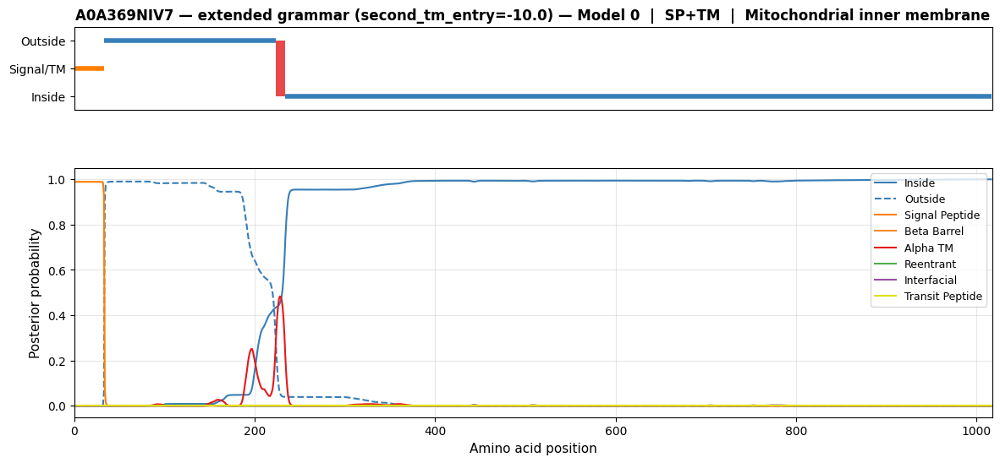

In [152]:
# -- A0A369NIV7: extended grammar, fold 0, second_tm_entry=-10.0 --------------
# Same settings as the Q00325 demo above. This globular protein is a false
# positive in the original model; the extended grammar may or may not fix it.

for model, orig in zip(models.topology_models, original_transitions):
    model.crf.transitions.data.copy_(orig)

m_ext2, _ = apply_extended_weights(
    models.topology_models[0], cfg,
    first_tm_entry=FIRST_ENTRY,
    second_tm_entry=SECOND_ENTRY,
)

with torch.no_grad():
    emiss2 = m_ext2._get_network_emissions(embedding2, mask2)
    paths2 = m_ext2.crf.decode(emiss2, mask2.byte())
    simple2 = m_ext2.simplify_labels(paths2)
    topo2   = m_ext2.crf_config.get_string_from_labels(simple2[0])
    raw_marg2 = m_ext2.crf.compute_marginal_probabilities(emiss2, mask2, truncate=False)
    marg2 = simplify_marginals_split_io(m_ext2.crf_config, raw_marg2[0])

from itertools import groupby as _igb2
tm_segs2 = [len(list(g)) for lbl, g in _igb2(topo2) if lbl == 'M']
print(f'Model 0  TM segments: {tm_segs2}  (n_tm={len(tm_segs2)})')
plot_inline(f'{seq_id2} — extended grammar (second_tm_entry={SECOND_ENTRY}) — Model 0',
            sequence2, topo2, mem_names, marg2)


In [158]:
# -- Systematic sweep: extended grammar, FIRST_ENTRY=None, SECOND_ENTRY=-2.0 --
# Same structure as cell 69 but the 'override' model uses apply_extended_weights.
# Hypothesis: n_tm=1 unchanged (first entry = trained weight), n_tm>1 improved.

EXT_FIRST  = -0.3
EXT_SECOND = -2.5

df3 = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df3['n_tm_true']  = df3['label'].apply(count_tm)

sweep3 = df3[df3['protein_type'] == 'M'].copy()
print(f'Sequences to test: {len(sweep3)}  (all TM counts, pure M-type)')
print(sweep3['n_tm_true'].value_counts().sort_index().to_string())
print()

results3 = []
for i, (_, row) in enumerate(sweep3.iterrows()):
    seq    = row['sequence']
    n_true = row['n_tm_true']
    fold   = int(row['cluster'])

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    # --- original ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_orig = count_tm(topo)

    # --- extended grammar override ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m_ext, _ = apply_extended_weights(
        models.topology_models[fold], cfg,
        first_tm_entry=EXT_FIRST,
        second_tm_entry=EXT_SECOND,
    )
    with torch.no_grad():
        em    = m_ext._get_network_emissions(emb, msk)
        paths = m_ext.crf.decode(em, msk.byte())
        topo  = m_ext.crf_config.get_string_from_labels(m_ext.simplify_labels(paths)[0])
    n_over = count_tm(topo)

    results3.append({'AC': row.get('AC', row['identifier']), 'n_true': n_true,
                     'n_orig': n_orig, 'n_over': n_over})
    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{len(sweep3)} done...')

res3 = pd.DataFrame(results3)

print()
print(f'Extended grammar: first_tm_entry={EXT_FIRST}, second_tm_entry={EXT_SECOND}')
print(f'{"n_tm_true":>10} {"n_seqs":>8} | {"fewer(orig)":>11} {"same(orig)":>11} {"more(orig)":>11} | {"fewer(ext)":>11} {"same(ext)":>11} {"more(ext)":>11}')
print('-' * 95)
for n, grp in res3.groupby('n_true'):
    fewer_orig = (grp['n_orig'] < grp['n_true']).sum()
    same_orig  = (grp['n_orig'] == grp['n_true']).sum()
    more_orig  = (grp['n_orig'] > grp['n_true']).sum()
    fewer_over = (grp['n_over'] < grp['n_true']).sum()
    same_over  = (grp['n_over'] == grp['n_true']).sum()
    more_over  = (grp['n_over'] > grp['n_true']).sum()
    print(f'{n:>10} {len(grp):>8} | {fewer_orig:>11} {same_orig:>11} {more_orig:>11} | {fewer_over:>11} {same_over:>11} {more_over:>11}')

new_fn3 = res3[(res3['n_over'] < res3['n_true']) & (res3['n_orig'] >= res3['n_true'])]
if len(new_fn3):
    print(f'\nNew false negatives introduced by extended grammar ({len(new_fn3)} sequences):')
    print(new_fn3.to_string(index=False))
else:
    print('\nNo new false negatives introduced by extended grammar.')


Sequences to test: 449  (all TM counts, pure M-type)
n_tm_true
1     195
2      69
3      37
4      30
5      14
6      26
7      20
8       9
9       5
10     11
11      5
12     17
13      2
14      8
15      1

  50/449 done...
  100/449 done...
  150/449 done...
  200/449 done...
  250/449 done...
  300/449 done...
  350/449 done...
  400/449 done...

Extended grammar: first_tm_entry=-0.3, second_tm_entry=-2.5
 n_tm_true   n_seqs | fewer(orig)  same(orig)  more(orig) |  fewer(ext)   same(ext)   more(ext)
-----------------------------------------------------------------------------------------------
         1      195 |          15         165          15 |          16         168          11
         2       69 |           2          62           5 |           2          63           4
         3       37 |           0          36           1 |           0          36           1
         4       30 |           0          28           2 |           0          30           0
      

In [159]:
# -- Extended grammar sweep: Globular/signal (S) and Globular/transit (T) ----
# For globular proteins n_tm_true = 0; 'more' = false positives.
# Key question: does the extended grammar introduce new false positives here?

df_glob = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_glob = df_glob[df_glob['protein_type'].isin(['S', 'T'])].copy()
df_glob['n_tm_true'] = df_glob['label'].apply(count_tm)
print(f'Sequences: S={( df_glob["protein_type"]=="S").sum()}  T={(df_glob["protein_type"]=="T").sum()}')
print()

results_glob = []
for i, (_, row) in enumerate(df_glob.iterrows()):
    seq    = row['sequence']
    n_true = row['n_tm_true']
    fold   = int(row['cluster'])
    ptype  = row['protein_type']

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    # --- original ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_orig = count_tm(topo)

    # --- extended grammar ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m_ext, _ = apply_extended_weights(
        models.topology_models[fold], cfg,
        first_tm_entry=EXT_FIRST,
        second_tm_entry=EXT_SECOND,
    )
    with torch.no_grad():
        em    = m_ext._get_network_emissions(emb, msk)
        paths = m_ext.crf.decode(em, msk.byte())
        topo  = m_ext.crf_config.get_string_from_labels(m_ext.simplify_labels(paths)[0])
    n_over = count_tm(topo)

    results_glob.append({'ptype': ptype, 'n_true': n_true,
                         'n_orig': n_orig, 'n_over': n_over})
    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{len(df_glob)} done...')

res_glob = pd.DataFrame(results_glob)

print()
print(f'Extended grammar: first_tm_entry={EXT_FIRST}, second_tm_entry={EXT_SECOND}')
print(f'{"protein_type":>15} {"n_seqs":>8} | {"fp(orig)":>10} {"ok(orig)":>10} | {"fp(ext)":>10} {"ok(ext)":>10} | {"delta_fp":>10}')
print('-' * 80)
for ptype, grp in res_glob.groupby('ptype'):
    fp_orig = (grp['n_orig'] > 0).sum()
    ok_orig = (grp['n_orig'] == 0).sum()
    fp_ext  = (grp['n_over'] > 0).sum()
    ok_ext  = (grp['n_over'] == 0).sum()
    label   = 'Globular/signal' if ptype == 'S' else 'Globular/transit'
    print(f'{label:>15} {len(grp):>8} | {fp_orig:>10} {ok_orig:>10} | {fp_ext:>10} {ok_ext:>10} | {fp_ext-fp_orig:>+10}')

# Show sequences that changed status
changed = res_glob[(res_glob['n_orig'] != res_glob['n_over'])]
if len(changed):
    print(f'\nSequences where prediction changed ({len(changed)} total):')
    print(f'  new false positives (0->TM): {((changed["n_orig"]==0) & (changed["n_over"]>0)).sum()}')
    print(f'  fixed false positives (TM->0): {((changed["n_orig"]>0) & (changed["n_over"]==0)).sum()}')
else:
    print('\nNo sequences changed prediction.')


Sequences: S=918  T=395

  50/1313 done...
  100/1313 done...
  150/1313 done...
  200/1313 done...
  250/1313 done...
  300/1313 done...
  350/1313 done...
  400/1313 done...
  450/1313 done...
  500/1313 done...
  550/1313 done...
  600/1313 done...
  650/1313 done...
  700/1313 done...
  750/1313 done...
  800/1313 done...
  850/1313 done...
  900/1313 done...
  950/1313 done...
  1000/1313 done...
  1050/1313 done...
  1100/1313 done...
  1150/1313 done...
  1200/1313 done...
  1250/1313 done...
  1300/1313 done...

Extended grammar: first_tm_entry=-0.3, second_tm_entry=-2.5
   protein_type   n_seqs |   fp(orig)   ok(orig) |    fp(ext)    ok(ext) |   delta_fp
--------------------------------------------------------------------------------
Globular/signal      918 |         33        885 |         29        889 |         -4
Globular/transit      395 |         12        383 |         11        384 |         -1

Sequences where prediction changed (8 total):
  new false positives (0->T

In [160]:
# -- Extended grammar sweep: Globular/none (I) --------------------------------

df_glob_i = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_glob_i = df_glob_i[df_glob_i['protein_type'] == 'I'].copy()
df_glob_i['n_tm_true'] = df_glob_i['label'].apply(count_tm)
print(f'Sequences: I={len(df_glob_i)}')
print()

results_glob_i = []
for i, (_, row) in enumerate(df_glob_i.iterrows()):
    seq  = row['sequence']
    fold = int(row['cluster'])

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    # --- original ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_orig = count_tm(topo)

    # --- extended grammar ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m_ext, _ = apply_extended_weights(
        models.topology_models[fold], cfg,
        first_tm_entry=EXT_FIRST,
        second_tm_entry=EXT_SECOND,
    )
    with torch.no_grad():
        em    = m_ext._get_network_emissions(emb, msk)
        paths = m_ext.crf.decode(em, msk.byte())
        topo  = m_ext.crf_config.get_string_from_labels(m_ext.simplify_labels(paths)[0])
    n_over = count_tm(topo)

    results_glob_i.append({'n_orig': n_orig, 'n_over': n_over})
    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{len(df_glob_i)} done...')

res_glob_i = pd.DataFrame(results_glob_i)

fp_orig = (res_glob_i['n_orig'] > 0).sum()
ok_orig = (res_glob_i['n_orig'] == 0).sum()
fp_ext  = (res_glob_i['n_over'] > 0).sum()
ok_ext  = (res_glob_i['n_over'] == 0).sum()

print(f'Extended grammar: first_tm_entry={EXT_FIRST}, second_tm_entry={EXT_SECOND}')
print(f'{"protein_type":>15} {"n_seqs":>8} | {"fp(orig)":>10} {"ok(orig)":>10} | {"fp(ext)":>10} {"ok(ext)":>10} | {"delta_fp":>10}')
print('-' * 80)
print(f'{"Globular/none":>15} {len(res_glob_i):>8} | {fp_orig:>10} {ok_orig:>10} | {fp_ext:>10} {ok_ext:>10} | {fp_ext-fp_orig:>+10}')

changed = res_glob_i[res_glob_i['n_orig'] != res_glob_i['n_over']]
if len(changed):
    print(f'\nSequences where prediction changed ({len(changed)} total):')
    print(f'  new false positives (0->TM): {((changed["n_orig"]==0) & (changed["n_over"]>0)).sum()}')
    print(f'  fixed false positives (TM->0): {((changed["n_orig"]>0) & (changed["n_over"]==0)).sum()}')
else:
    print('\nNo sequences changed prediction.')


Sequences: I=5909

  50/5909 done...
  100/5909 done...
  150/5909 done...
  200/5909 done...
  250/5909 done...
  300/5909 done...
  350/5909 done...
  400/5909 done...
  450/5909 done...
  500/5909 done...
  550/5909 done...
  600/5909 done...
  650/5909 done...
  700/5909 done...
  750/5909 done...
  800/5909 done...
  850/5909 done...
  900/5909 done...
  950/5909 done...
  1000/5909 done...
  1050/5909 done...
  1100/5909 done...
  1150/5909 done...
  1200/5909 done...
  1250/5909 done...
  1300/5909 done...
  1350/5909 done...
  1400/5909 done...
  1450/5909 done...
  1500/5909 done...
  1550/5909 done...
  1600/5909 done...
  1650/5909 done...
  1700/5909 done...
  1750/5909 done...
  1800/5909 done...
  1850/5909 done...
  1900/5909 done...
  1950/5909 done...
  2000/5909 done...
  2050/5909 done...
  2100/5909 done...
  2150/5909 done...
  2200/5909 done...
  2250/5909 done...
  2300/5909 done...
  2350/5909 done...
  2400/5909 done...
  2450/5909 done...
  2500/5909 done...
 

In [162]:
# -- Extended grammar sweep: Beta TM (B) --------------------------------------
# Beta barrels use "B" labels. The extended grammar only directly modifies
# alpha-TM entries, but making alpha TM more expensive shifts competition
# toward beta TM states — so some changes here are expected and interesting.

df_beta = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_beta = df_beta[df_beta['protein_type'] == 'B'].copy()
df_beta['n_tm_true'] = df_beta['label'].apply(lambda s: count_seg(s, 'B'))
print(f'Sequences: B={len(df_beta)}')
print()

results_beta = []
for i, (_, row) in enumerate(df_beta.iterrows()):
    seq  = row['sequence']
    fold = int(row['cluster'])

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    # --- original ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_orig = count_seg(topo, 'B')

    # --- extended grammar ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m_ext, _ = apply_extended_weights(
        models.topology_models[fold], cfg,
        first_tm_entry=EXT_FIRST,
        second_tm_entry=EXT_SECOND,
    )
    with torch.no_grad():
        em    = m_ext._get_network_emissions(emb, msk)
        paths = m_ext.crf.decode(em, msk.byte())
        topo  = m_ext.crf_config.get_string_from_labels(m_ext.simplify_labels(paths)[0])
    n_over = count_seg(topo, 'B')

    results_beta.append({'n_true': row['n_tm_true'], 'n_orig': n_orig, 'n_over': n_over})
    if (i + 1) % 20 == 0:
        print(f'  {i+1}/{len(df_beta)} done...')

res_beta = pd.DataFrame(results_beta)

print(f'Extended grammar: first_tm_entry={EXT_FIRST}, second_tm_entry={EXT_SECOND}')
print(f'{"n_seqs":>8} | {"fewer(orig)":>11} {"same(orig)":>11} {"more(orig)":>11} | {"fewer(ext)":>11} {"same(ext)":>11} {"more(ext)":>11}')
print('-' * 85)
fewer_orig = (res_beta['n_orig'] < res_beta['n_true']).sum()
same_orig  = (res_beta['n_orig'] == res_beta['n_true']).sum()
more_orig  = (res_beta['n_orig'] > res_beta['n_true']).sum()
fewer_ext  = (res_beta['n_over'] < res_beta['n_true']).sum()
same_ext   = (res_beta['n_over'] == res_beta['n_true']).sum()
more_ext   = (res_beta['n_over'] > res_beta['n_true']).sum()
print(f'{len(res_beta):>8} | {fewer_orig:>11} {same_orig:>11} {more_orig:>11} | {fewer_ext:>11} {same_ext:>11} {more_ext:>11}')

changed = res_beta[res_beta['n_orig'] != res_beta['n_over']]
if len(changed):
    print(f'Note: {len(changed)} beta TM predictions changed (competition effect):') 
    print(changed)
else:
    print('\nSanity check passed: all beta TM predictions identical.')


Sequences: B=92

  20/92 done...
  40/92 done...
  60/92 done...
  80/92 done...
Extended grammar: first_tm_entry=-0.3, second_tm_entry=-2.5
  n_seqs | fewer(orig)  same(orig)  more(orig) |  fewer(ext)   same(ext)   more(ext)
-------------------------------------------------------------------------------------
      92 |           7          83           2 |           7          83           2

Sanity check passed: all beta TM predictions identical.


In [163]:
# -- Extended grammar sweep: Alpha TM + signal (M+S) and + transit (M+T) -----
# These have both a signal/transit peptide AND alpha TM segments.
# We count alpha TM segments (M) and compare original vs extended.

df_ms = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_ms = df_ms[df_ms['protein_type'].isin(['M+S', 'M+T'])].copy()
df_ms['n_tm_true'] = df_ms['label'].apply(count_tm)
print(f'Sequences: M+S={( df_ms["protein_type"]=="M+S").sum()}  M+T={(df_ms["protein_type"]=="M+T").sum()}')
print()

results_ms = []
for i, (_, row) in enumerate(df_ms.iterrows()):
    seq    = row['sequence']
    n_true = row['n_tm_true']
    fold   = int(row['cluster'])
    ptype  = row['protein_type']

    emb = get_embedding(seq, esm_model, esm_alphabet, DEVICE).unsqueeze(0)
    msk = torch.ones(1, len(seq), device=DEVICE)

    # --- original ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    with torch.no_grad():
        em    = models.topology_models[fold]._get_network_emissions(emb, msk)
        paths = models.topology_models[fold].crf.decode(em, msk.byte())
        topo  = models.topology_models[fold].crf_config.get_string_from_labels(
                    models.topology_models[fold].simplify_labels(paths)[0])
    n_orig = count_tm(topo)

    # --- extended grammar ---
    for model, orig in zip(models.topology_models, original_transitions):
        model.crf.transitions.data.copy_(orig)
    m_ext, _ = apply_extended_weights(
        models.topology_models[fold], cfg,
        first_tm_entry=EXT_FIRST,
        second_tm_entry=EXT_SECOND,
    )
    with torch.no_grad():
        em    = m_ext._get_network_emissions(emb, msk)
        paths = m_ext.crf.decode(em, msk.byte())
        topo  = m_ext.crf_config.get_string_from_labels(m_ext.simplify_labels(paths)[0])
    n_over = count_tm(topo)

    results_ms.append({'ptype': ptype, 'n_true': n_true,
                       'n_orig': n_orig, 'n_over': n_over})
    if (i + 1) % 20 == 0:
        print(f'  {i+1}/{len(df_ms)} done...')

res_ms = pd.DataFrame(results_ms)

print(f'Extended grammar: first_tm_entry={EXT_FIRST}, second_tm_entry={EXT_SECOND}')
print(f'{"protein_type":>15} {"n_tm":>6} {"n_seqs":>7} | {"fewer(orig)":>11} {"same(orig)":>11} {"more(orig)":>11} | {"fewer(ext)":>11} {"same(ext)":>11} {"more(ext)":>11}')
print('-' * 105)
for ptype, grp in res_ms.groupby('ptype'):
    label_map = {'M+S': 'Alpha TM/signal', 'M+T': 'Alpha TM/transit'}
    first = True
    for n_tm, sgrp in grp.groupby('n_true'):
        fewer_orig = (sgrp['n_orig'] < sgrp['n_true']).sum()
        same_orig  = (sgrp['n_orig'] == sgrp['n_true']).sum()
        more_orig  = (sgrp['n_orig'] > sgrp['n_true']).sum()
        fewer_ext  = (sgrp['n_over'] < sgrp['n_true']).sum()
        same_ext   = (sgrp['n_over'] == sgrp['n_true']).sum()
        more_ext   = (sgrp['n_over'] > sgrp['n_true']).sum()
        row_label  = label_map.get(ptype, ptype) if first else ''
        print(f'{row_label:>15} {int(n_tm):>6} {len(sgrp):>7} | {fewer_orig:>11} {same_orig:>11} {more_orig:>11} | {fewer_ext:>11} {same_ext:>11} {more_ext:>11}')
        first = False
    print()


Sequences: M+S=96  M+T=26

  20/122 done...
  40/122 done...
  60/122 done...
  80/122 done...
  100/122 done...
  120/122 done...
Extended grammar: first_tm_entry=-0.3, second_tm_entry=-2.5
   protein_type   n_tm  n_seqs | fewer(orig)  same(orig)  more(orig) |  fewer(ext)   same(ext)   more(ext)
---------------------------------------------------------------------------------------------------------
Alpha TM/signal      1      64 |           3          59           2 |           3          60           1
                     2       4 |           1           3           0 |           1           3           0
                     3       7 |           0           5           2 |           0           5           2
                     4       3 |           0           3           0 |           0           3           0
                     5       1 |           0           1           0 |           0           1           0
                     7      15 |           0          15     

Single-pass (n_tm=1):   307 sequences
Multi-pass  (n_tm≥2):   473 sequences

TM segment lengths — single-pass:
  n=307  mean=17.7  median=17  min=10  max=30
TM segment lengths — multi-pass:
  n=2998  mean=19.0  median=18  min=10  max=30

Single-pass (n_tm=1)  (n=307)
  has reentrant (R):    1  (0.3%)
  has interfacial (F):   32  (10.4%)
  has R or F:            33  (10.7%)

Multi-pass  (n_tm≥2)  (n=473)
  has reentrant (R):   40  (8.5%)
  has interfacial (F):  176  (37.2%)
  has R or F:           194  (41.0%)



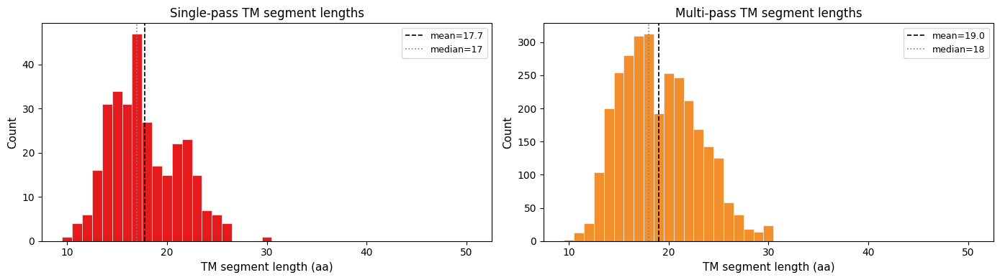

In [165]:
# -- Biological analysis: single-pass vs multi-pass alpha TM proteins --------
# Ground truth labels from the full evaluation CSV.
# Single-pass (bitopic): n_tm == 1.  Multi-pass: n_tm >= 2.

from itertools import groupby as _gb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_bio = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_bio = df_bio[df_bio['protein_type'].str.contains('M')].copy()

# Extract per-sequence stats from the ground truth label string
def seg_lengths(label, lbl):
    """Lengths of all runs of character `lbl` in label string."""
    return [sum(1 for _ in g) for k, g in _gb(label) if k == lbl]

df_bio['n_tm']       = df_bio['label'].apply(lambda s: len(seg_lengths(s, 'M')))
df_bio['tm_lengths'] = df_bio['label'].apply(lambda s: seg_lengths(s, 'M'))
df_bio['has_R']      = df_bio['label'].apply(lambda s: 'R' in s)
df_bio['has_F']      = df_bio['label'].apply(lambda s: 'F' in s)
df_bio['has_RF']     = df_bio['has_R'] | df_bio['has_F']

single = df_bio[df_bio['n_tm'] == 1]
multi  = df_bio[df_bio['n_tm'] >= 2]
print(f'Single-pass (n_tm=1): {len(single):>5} sequences')
print(f'Multi-pass  (n_tm≥2): {len(multi):>5} sequences')
print()

# ── 1 & 2: TM segment length distributions ───────────────────────────────────
single_lens = [l for ls in single['tm_lengths'] for l in ls]
multi_lens  = [l for ls in multi['tm_lengths']  for l in ls]

print('TM segment lengths — single-pass:')
print(f'  n={len(single_lens)}  mean={np.mean(single_lens):.1f}  median={np.median(single_lens):.0f}'
      f'  min={min(single_lens)}  max={max(single_lens)}')
print('TM segment lengths — multi-pass:')
print(f'  n={len(multi_lens)}  mean={np.mean(multi_lens):.1f}  median={np.median(multi_lens):.0f}'
      f'  min={min(multi_lens)}  max={max(multi_lens)}')
print()

# ── 3 & 4: Reentrant / interfacial stats ─────────────────────────────────────
for label, grp in [('Single-pass (n_tm=1)', single), ('Multi-pass  (n_tm≥2)', multi)]:
    n = len(grp)
    print(f'{label}  (n={n})')
    print(f'  has reentrant (R): {grp["has_R"].sum():>4}  ({100*grp["has_R"].mean():.1f}%)')
    print(f'  has interfacial (F): {grp["has_F"].sum():>4}  ({100*grp["has_F"].mean():.1f}%)')
    print(f'  has R or F:          {grp["has_RF"].sum():>4}  ({100*grp["has_RF"].mean():.1f}%)')
    print()

# ── Plot ─────────────────────────────────────────────────────────────────────
bins = np.arange(9.5, 51.5, 1)  # 1-aa bins from 10 to 51

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)

for ax, lens, title, color in [
    (axes[0], single_lens, 'Single-pass TM segment lengths', COLORS['alpha']),
    (axes[1], multi_lens,  'Multi-pass TM segment lengths',  COLORS.get('beta', 'steelblue')),
]:
    ax.hist(lens, bins=bins, color=color, edgecolor='white', linewidth=0.4)
    ax.axvline(np.mean(lens), color='black', linestyle='--', linewidth=1.2,
               label=f'mean={np.mean(lens):.1f}')
    ax.axvline(np.median(lens), color='gray', linestyle=':', linewidth=1.2,
               label=f'median={np.median(lens):.0f}')
    ax.set_xlabel('TM segment length (aa)', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


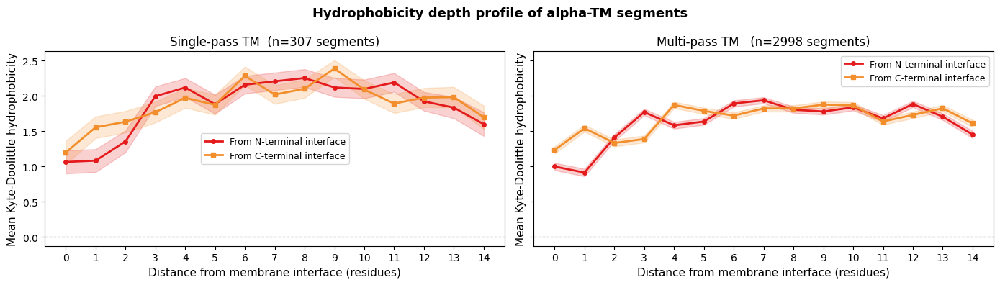

 depth    single N    single C     multi N     multi C
-------------------------------------------------------
     0        1.07        1.20        1.00        1.23
     1        1.08        1.56        0.91        1.54
     2        1.36        1.63        1.41        1.33
     3        2.00        1.77        1.77        1.39
     4        2.12        1.97        1.58        1.87
     5        1.88        1.88        1.64        1.79
     6        2.16        2.28        1.89        1.72
     7        2.21        2.02        1.94        1.82
     8        2.25        2.10        1.81        1.82
     9        2.12        2.39        1.78        1.88
    10        2.10        2.09        1.84        1.87
    11        2.19        1.89        1.68        1.64
    12        1.92        1.98        1.89        1.73
    13        1.83        1.98        1.71        1.83
    14        1.60        1.70        1.45        1.61


In [167]:
# -- Hydrophobicity depth profile of TM segments (Kyte-Doolittle) -----------
# For each TM segment, compute hydrophobicity at each position measured as
# distance from the N-terminal interface (entry) and C-terminal interface (exit).
# Averaged across all segments; single-pass and multi-pass shown separately.

KD = {  # Kyte-Doolittle hydrophobicity scale
    'A':  1.8, 'R': -4.5, 'N': -3.5, 'D': -3.5, 'C':  2.5,
    'Q': -3.5, 'E': -3.5, 'G': -0.4, 'H': -3.2, 'I':  4.5,
    'L':  3.8, 'K': -3.9, 'M':  1.9, 'F':  2.8, 'P': -1.6,
    'S': -0.8, 'T': -0.7, 'W': -0.9, 'Y': -1.3, 'V':  4.2,
}

def extract_tm_seqs(df_group):
    """Return list of amino acid strings for every TM segment in the group."""
    segs = []
    for _, row in df_group.iterrows():
        label = row['label']
        seq   = row['sequence']
        pos = 0
        for k, g in _gb(label):
            length = sum(1 for _ in g)
            if k == 'M':
                segs.append(seq[pos:pos+length])
            pos += length
    return segs

def depth_profile(segs, max_depth=20):
    """Average KD hydrophobicity + SEM at each depth from N- and C-terminal ends."""
    from_n = [[] for _ in range(max_depth)]
    from_c = [[] for _ in range(max_depth)]
    for s in segs:
        h = [KD.get(aa, 0.0) for aa in s]
        for d in range(min(max_depth, len(h))):
            from_n[d].append(h[d])
            from_c[d].append(h[-(d+1)])
    mean_n = np.array([np.mean(v) if v else np.nan for v in from_n])
    mean_c = np.array([np.mean(v) if v else np.nan for v in from_c])
    sem_n  = np.array([np.std(v, ddof=1)/np.sqrt(len(v)) if len(v)>1 else np.nan for v in from_n])
    sem_c  = np.array([np.std(v, ddof=1)/np.sqrt(len(v)) if len(v)>1 else np.nan for v in from_c])
    return mean_n, mean_c, sem_n, sem_c

MAX_DEPTH = 15
depths = np.arange(MAX_DEPTH)

single_segs = extract_tm_seqs(single)
multi_segs  = extract_tm_seqs(multi)

s_n, s_c, s_n_sem, s_c_sem = depth_profile(single_segs, MAX_DEPTH)
m_n, m_c, m_n_sem, m_c_sem = depth_profile(multi_segs,  MAX_DEPTH)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, n_prof, c_prof, n_sem, c_sem, title in [
    (axes[0], s_n, s_c, s_n_sem, s_c_sem, f'Single-pass TM  (n={len(single_segs)} segments)'),
    (axes[1], m_n, m_c, m_n_sem, m_c_sem, f'Multi-pass TM   (n={len(multi_segs)} segments)'),
]:
    col_n = COLORS['alpha']
    col_c = COLORS.get('beta', 'steelblue')
    ax.plot(depths, n_prof, color=col_n, linewidth=2,
            marker='o', markersize=4, label='From N-terminal interface')
    ax.fill_between(depths, n_prof - n_sem, n_prof + n_sem, color=col_n, alpha=0.2)
    ax.plot(depths, c_prof, color=col_c, linewidth=2,
            marker='s', markersize=4, label='From C-terminal interface')
    ax.fill_between(depths, c_prof - c_sem, c_prof + c_sem, color=col_c, alpha=0.2)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xlabel('Distance from membrane interface (residues)', fontsize=11)
    ax.set_ylabel('Mean Kyte-Doolittle hydrophobicity', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=9)
    ax.set_xticks(depths)

plt.suptitle('Hydrophobicity depth profile of alpha-TM segments', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Also print the values for inspection
print(f'{"depth":>6}  {"single N":>10}  {"single C":>10}  {"multi N":>10}  {"multi C":>10}')
print('-' * 55)
for d in range(MAX_DEPTH):
    print(f'{d:>6}  {s_n[d]:>10.2f}  {s_c[d]:>10.2f}  {m_n[d]:>10.2f}  {m_c[d]:>10.2f}')


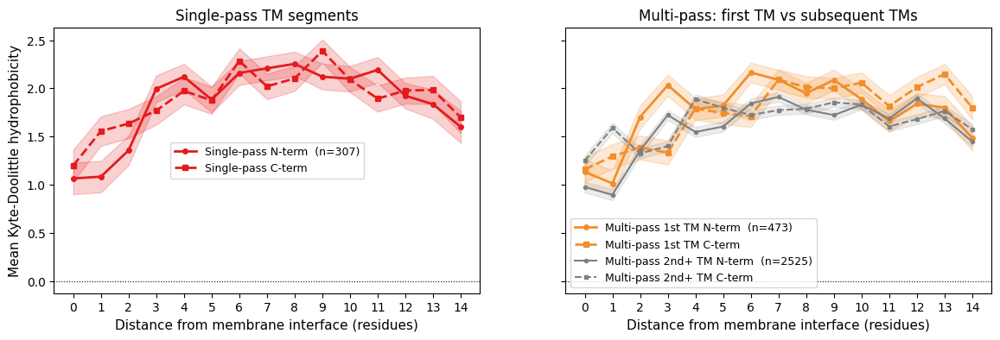

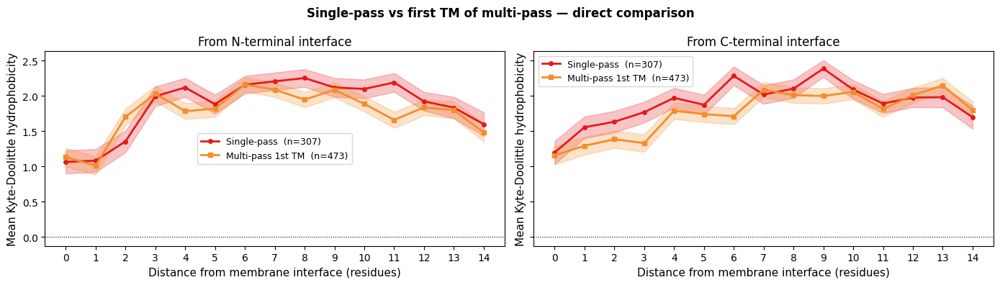

<Figure size 640x480 with 0 Axes>

In [169]:
# -- Hydrophobicity profile: single-pass vs FIRST TM of multi-pass -----------
# If first TM of multi-pass looks like single-pass  → Model 1 (shared first track)
# If first TM of multi-pass looks like subsequent TMs → Model 2 (separate tracks)

def extract_first_tm_seqs(df_group):
    """Return the first TM segment amino acid string for each sequence."""
    segs = []
    for _, row in df_group.iterrows():
        label = row['label']
        seq   = row['sequence']
        pos = 0
        for k, g in _gb(label):
            length = sum(1 for _ in g)
            if k == 'M':
                segs.append(seq[pos:pos+length])
                break  # first TM only
            pos += length
    return segs

def extract_nonfirst_tm_seqs(df_group):
    """Return all TM segments EXCEPT the first for each sequence."""
    segs = []
    for _, row in df_group.iterrows():
        label = row['label']
        seq   = row['sequence']
        pos = 0
        tm_count = 0
        for k, g in _gb(label):
            length = sum(1 for _ in g)
            if k == 'M':
                tm_count += 1
                if tm_count > 1:
                    segs.append(seq[pos:pos+length])
            pos += length
    return segs

single_segs      = extract_tm_seqs(single)          # all single-pass TMs
multi_first_segs = extract_first_tm_seqs(multi)     # first TM of multi-pass
multi_rest_segs  = extract_nonfirst_tm_seqs(multi)  # subsequent TMs of multi-pass

s_n,   s_c,   s_n_sem,   s_c_sem   = depth_profile(single_segs,      MAX_DEPTH)
mf_n,  mf_c,  mf_n_sem,  mf_c_sem  = depth_profile(multi_first_segs, MAX_DEPTH)
mr_n,  mr_c,  mr_n_sem,  mr_c_sem  = depth_profile(multi_rest_segs,  MAX_DEPTH)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

col_single = COLORS['alpha']
col_first  = COLORS.get('beta', 'steelblue')
col_rest   = 'gray'

# Left: single-pass (unchanged from before)
ax = axes[0]
ax.plot(depths, s_n, color=col_single, linewidth=2, marker='o', markersize=4,
        label=f'Single-pass N-term  (n={len(single_segs)})')
ax.fill_between(depths, s_n - s_n_sem, s_n + s_n_sem, color=col_single, alpha=0.2)
ax.plot(depths, s_c, color=col_single, linewidth=2, marker='s', markersize=4,
        linestyle='--', label='Single-pass C-term')
ax.fill_between(depths, s_c - s_c_sem, s_c + s_c_sem, color=col_single, alpha=0.2)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_title('Single-pass TM segments', fontsize=12)
ax.set_xlabel('Distance from membrane interface (residues)', fontsize=11)
ax.set_ylabel('Mean Kyte-Doolittle hydrophobicity', fontsize=11)
ax.legend(fontsize=9)
ax.set_xticks(depths)

# Right: first TM of multi-pass vs subsequent TMs
ax = axes[1]
ax.plot(depths, mf_n, color=col_first, linewidth=2, marker='o', markersize=4,
        label=f'Multi-pass 1st TM N-term  (n={len(multi_first_segs)})')
ax.fill_between(depths, mf_n - mf_n_sem, mf_n + mf_n_sem, color=col_first, alpha=0.2)
ax.plot(depths, mf_c, color=col_first, linewidth=2, marker='s', markersize=4,
        linestyle='--', label='Multi-pass 1st TM C-term')
ax.fill_between(depths, mf_c - mf_c_sem, mf_c + mf_c_sem, color=col_first, alpha=0.2)
ax.plot(depths, mr_n, color=col_rest, linewidth=1.5, marker='o', markersize=3,
        label=f'Multi-pass 2nd+ TM N-term  (n={len(multi_rest_segs)})')
ax.fill_between(depths, mr_n - mr_n_sem, mr_n + mr_n_sem, color=col_rest, alpha=0.15)
ax.plot(depths, mr_c, color=col_rest, linewidth=1.5, marker='s', markersize=3,
        linestyle='--', label='Multi-pass 2nd+ TM C-term')
ax.fill_between(depths, mr_c - mr_c_sem, mr_c + mr_c_sem, color=col_rest, alpha=0.15)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_title('Multi-pass: first TM vs subsequent TMs', fontsize=12)
ax.set_xlabel('Distance from membrane interface (residues)', fontsize=11)
ax.legend(fontsize=9)
ax.set_xticks(depths)

# Third plot: direct comparison single-pass vs first TM of multi-pass
fig3, axes3 = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, n_s, c_s, n_m, c_m, n_sem_s, c_sem_s, n_sem_m, c_sem_m, direction in [
    (axes3[0], s_n,  s_c,  mf_n,  mf_c,  s_n_sem,  s_c_sem,  mf_n_sem,  mf_c_sem,  'N-terminal interface'),
    (axes3[1], s_c,  s_n,  mf_c,  mf_n,  s_c_sem,  s_n_sem,  mf_c_sem,  mf_n_sem,  'C-terminal interface'),
]:
    ax.plot(depths, n_s, color=col_single, linewidth=2, marker='o', markersize=4,
            label=f'Single-pass  (n={len(single_segs)})')
    ax.fill_between(depths, n_s - n_sem_s, n_s + n_sem_s, color=col_single, alpha=0.25)
    ax.plot(depths, n_m, color=col_first,  linewidth=2, marker='s', markersize=4,
            label=f'Multi-pass 1st TM  (n={len(multi_first_segs)})')
    ax.fill_between(depths, n_m - n_sem_m, n_m + n_sem_m, color=col_first,  alpha=0.25)
    ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
    ax.set_xlabel('Distance from membrane interface (residues)', fontsize=11)
    ax.set_ylabel('Mean Kyte-Doolittle hydrophobicity', fontsize=11)
    ax.set_title(f'From {direction}', fontsize=12)
    ax.legend(fontsize=9)
    ax.set_xticks(depths)

fig3.suptitle('Single-pass vs first TM of multi-pass — direct comparison',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

plt.suptitle('Hydrophobicity depth profile: single-pass vs first/subsequent multi-pass TMs',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


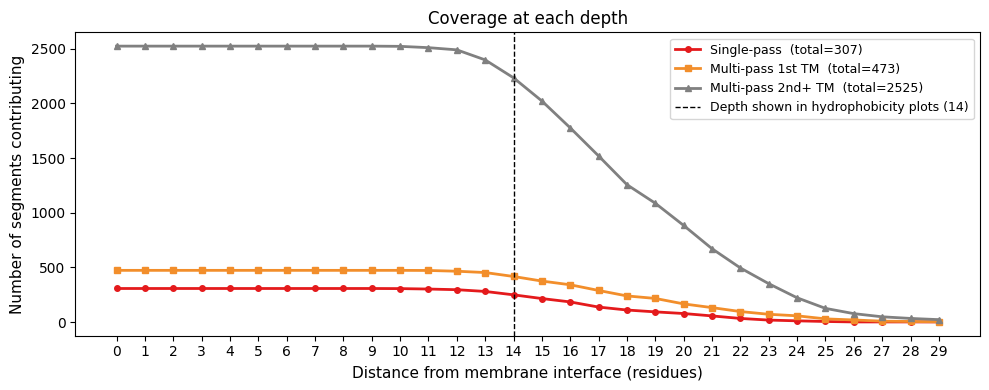

 depth    single   multi 1st   multi 2nd+
------------------------------------------
     0       307         473         2525
     1       307         473         2525
     2       307         473         2525
     3       307         473         2525
     4       307         473         2525
     5       307         473         2525
     6       307         473         2525
     7       307         473         2525
     8       307         473         2525
     9       307         473         2525
    10       306         473         2523
    11       302         472         2511
    12       296         465         2491
    13       280         453         2399
    14       249         417         2235
    15       215         375         2023
    16       184         341         1777
    17       137         289         1520
    18       110         239         1257
    19        93         216         1087
    20        78         166          884
    21        56         132     

In [170]:
# -- Number of segments contributing at each depth ---------------------------

MAX_DEPTH_PLOT = 30  # show up to max TM length
depths_full = np.arange(MAX_DEPTH_PLOT)

def coverage(segs, max_depth):
    return np.array([sum(1 for s in segs if len(s) > d) for d in range(max_depth)])

cov_single      = coverage(single_segs,      MAX_DEPTH_PLOT)
cov_multi_first = coverage(multi_first_segs, MAX_DEPTH_PLOT)
cov_multi_rest  = coverage(multi_rest_segs,  MAX_DEPTH_PLOT)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(depths_full, cov_single,      color=col_single, linewidth=2,
        marker='o', markersize=4, label=f'Single-pass  (total={len(single_segs)})')
ax.plot(depths_full, cov_multi_first, color=col_first,  linewidth=2,
        marker='s', markersize=4, label=f'Multi-pass 1st TM  (total={len(multi_first_segs)})')
ax.plot(depths_full, cov_multi_rest,  color=col_rest,   linewidth=2,
        marker='^', markersize=4, label=f'Multi-pass 2nd+ TM  (total={len(multi_rest_segs)})')
ax.axvline(MAX_DEPTH - 1, color='black', linewidth=1, linestyle='--',
           label=f'Depth shown in hydrophobicity plots ({MAX_DEPTH-1})')
ax.set_xlabel('Distance from membrane interface (residues)', fontsize=11)
ax.set_ylabel('Number of segments contributing', fontsize=11)
ax.set_title('Coverage at each depth', fontsize=12)
ax.set_xticks(depths_full)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Print table
print(f'{"depth":>6}  {"single":>8}  {"multi 1st":>10}  {"multi 2nd+":>11}')
print('-' * 42)
for d in depths_full:
    print(f'{d:>6}  {cov_single[d]:>8}  {cov_multi_first[d]:>10}  {cov_multi_rest[d]:>11}')


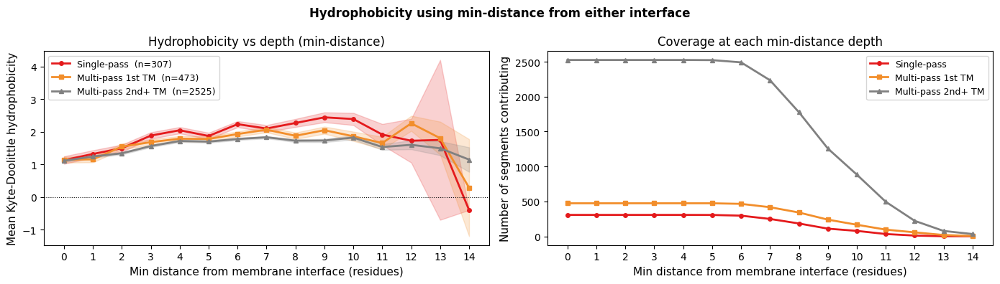

 depth   hydro single   hydro 1st   hydro 2nd+  cov single   cov 1st   cov 2nd+
--------------------------------------------------------------------------------
     0           1.13        1.15         1.11         307       473       2525
     1           1.32        1.15         1.24         307       473       2525
     2           1.49        1.54         1.34         307       473       2525
     3           1.88        1.68         1.56         307       473       2525
     4           2.05        1.79         1.72         307       473       2525
     5           1.87        1.78         1.70         306       473       2523
     6           2.23        1.93         1.78         296       465       2491
     7           2.10        2.06         1.83         249       417       2235
     8           2.27        1.88         1.73         184       341       1777
     9           2.44        2.05         1.73         110       239       1257
    10           2.39        1.86      

In [171]:
# -- Hydrophobicity vs min-distance from either membrane interface ------------
# For each residue at position i in a TM segment of length L,
# depth = min(i, L-1-i).  Both interfaces fold onto the same axis.
# Coverage at depth d: segments where floor((L-1)/2) >= d, i.e. len >= 2*d+1.

def depth_profile_min(segs, max_depth=15):
    """Mean KD hydrophobicity at each min-distance depth, with SEM."""
    buckets = [[] for _ in range(max_depth)]
    for s in segs:
        h = [KD.get(aa, 0.0) for aa in s]
        L = len(h)
        for i, hi in enumerate(h):
            d = min(i, L - 1 - i)
            if d < max_depth:
                buckets[d].append(hi)
    mean = np.array([np.mean(v) if v else np.nan for v in buckets])
    sem  = np.array([np.std(v, ddof=1)/np.sqrt(len(v)) if len(v) > 1 else np.nan
                     for v in buckets])
    return mean, sem

def coverage_min(segs, max_depth):
    """Number of segments contributing at each min-distance depth."""
    return np.array([sum(1 for s in segs if len(s) >= 2*d + 1)
                     for d in range(max_depth)])

MAX_DEPTH_MIN = 15
depths_min = np.arange(MAX_DEPTH_MIN)

s_m,  s_sem  = depth_profile_min(single_segs,      MAX_DEPTH_MIN)
mf_m, mf_sem = depth_profile_min(multi_first_segs, MAX_DEPTH_MIN)
mr_m, mr_sem = depth_profile_min(multi_rest_segs,  MAX_DEPTH_MIN)

cov_s  = coverage_min(single_segs,      MAX_DEPTH_MIN)
cov_mf = coverage_min(multi_first_segs, MAX_DEPTH_MIN)
cov_mr = coverage_min(multi_rest_segs,  MAX_DEPTH_MIN)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: hydrophobicity
ax = axes[0]
for mean, sem, color, marker, label in [
    (s_m,  s_sem,  col_single, 'o', f'Single-pass  (n={len(single_segs)})'),
    (mf_m, mf_sem, col_first,  's', f'Multi-pass 1st TM  (n={len(multi_first_segs)})'),
    (mr_m, mr_sem, col_rest,   '^', f'Multi-pass 2nd+ TM  (n={len(multi_rest_segs)})'),
]:
    ax.plot(depths_min, mean, color=color, linewidth=2, marker=marker, markersize=4, label=label)
    ax.fill_between(depths_min, mean - sem, mean + sem, color=color, alpha=0.2)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_xlabel('Min distance from membrane interface (residues)', fontsize=11)
ax.set_ylabel('Mean Kyte-Doolittle hydrophobicity', fontsize=11)
ax.set_title('Hydrophobicity vs depth (min-distance)', fontsize=12)
ax.set_xticks(depths_min)
ax.legend(fontsize=9)

# Right: coverage
ax = axes[1]
ax.plot(depths_min, cov_s,  color=col_single, linewidth=2, marker='o', markersize=4,
        label=f'Single-pass')
ax.plot(depths_min, cov_mf, color=col_first,  linewidth=2, marker='s', markersize=4,
        label=f'Multi-pass 1st TM')
ax.plot(depths_min, cov_mr, color=col_rest,   linewidth=2, marker='^', markersize=4,
        label=f'Multi-pass 2nd+ TM')
ax.set_xlabel('Min distance from membrane interface (residues)', fontsize=11)
ax.set_ylabel('Number of segments contributing', fontsize=11)
ax.set_title('Coverage at each min-distance depth', fontsize=12)
ax.set_xticks(depths_min)
ax.legend(fontsize=9)

plt.suptitle('Hydrophobicity using min-distance from either interface', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Table
print(f'{"depth":>6}  {"hydro single":>13}  {"hydro 1st":>10}  {"hydro 2nd+":>11}'
      f'  {"cov single":>10}  {"cov 1st":>8}  {"cov 2nd+":>9}')
print('-' * 80)
for d in depths_min:
    print(f'{d:>6}  {s_m[d]:>13.2f}  {mf_m[d]:>10.2f}  {mr_m[d]:>11.2f}'
          f'  {cov_s[d]:>10}  {cov_mf[d]:>8}  {cov_mr[d]:>9}')


/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/2290515821.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


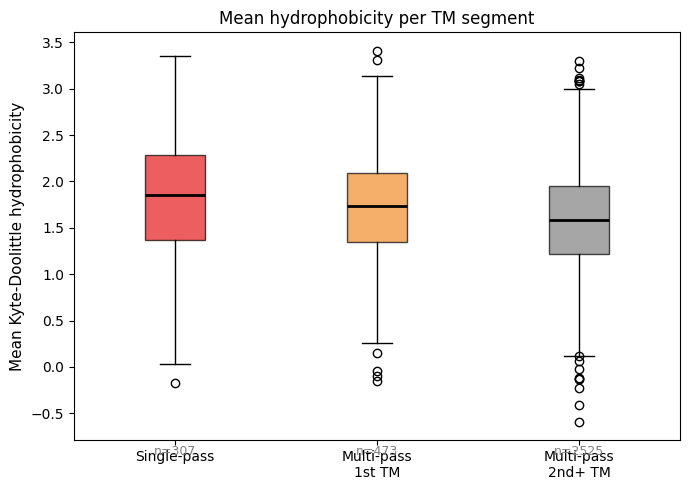

Single-pass   n=  307  mean=1.83  median=1.85  std=0.68
Multi 1st     n=  473  mean=1.71  median=1.73  std=0.57
Multi 2nd+    n= 2525  mean=1.58  median=1.58  std=0.55


In [172]:
# -- Boxplot: mean hydrophobicity per TM segment -----------------------------

def mean_hydro(segs):
    return [np.mean([KD.get(aa, 0.0) for aa in s]) for s in segs]

hydro_single = mean_hydro(single_segs)
hydro_first  = mean_hydro(multi_first_segs)
hydro_rest   = mean_hydro(multi_rest_segs)

fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot(
    [hydro_single, hydro_first, hydro_rest],
    labels=['Single-pass', 'Multi-pass\n1st TM', 'Multi-pass\n2nd+ TM'],
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
)
for patch, color in zip(bp['boxes'], [col_single, col_first, col_rest]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel('Mean Kyte-Doolittle hydrophobicity', fontsize=11)
ax.set_title('Mean hydrophobicity per TM segment', fontsize=12)
for i, (vals, color) in enumerate([
    (hydro_single, col_single),
    (hydro_first,  col_first),
    (hydro_rest,   col_rest),
], start=1):
    ax.text(i, ax.get_ylim()[0] - 0.05, f'n={len(vals)}',
            ha='center', va='top', fontsize=9, color='gray')
plt.tight_layout()
plt.show()

for label, vals in [('Single-pass', hydro_single),
                     ('Multi 1st',   hydro_first),
                     ('Multi 2nd+',  hydro_rest)]:
    print(f'{label:<12}  n={len(vals):>5}  '
          f'mean={np.mean(vals):.2f}  median={np.median(vals):.2f}  '
          f'std={np.std(vals):.2f}')


/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/2787769747.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


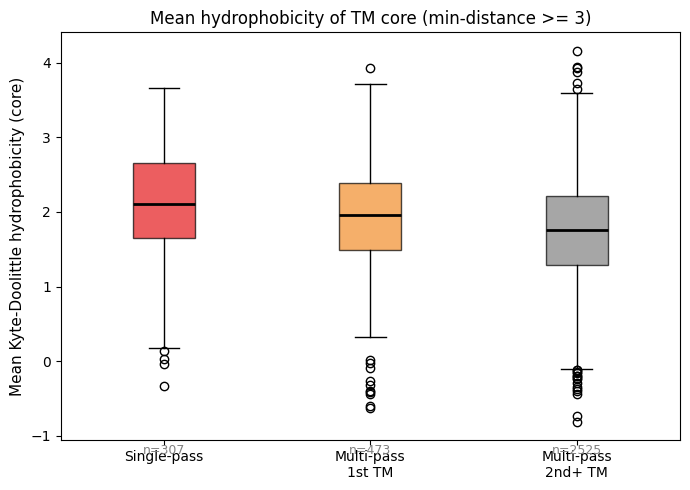

Single-pass   n=  307  mean=2.09  median=2.11  std=0.75
Multi 1st     n=  473  mean=1.89  median=1.96  std=0.70
Multi 2nd+    n= 2525  mean=1.75  median=1.75  std=0.69


In [173]:
# -- Boxplot: mean hydrophobicity over inner core (min-distance >= 3) --------

MIN_DEPTH = 3  # only residues with min(i, L-1-i) >= MIN_DEPTH

def mean_hydro_inner(segs, min_depth=MIN_DEPTH):
    result = []
    for s in segs:
        h = [KD.get(aa, 0.0) for aa in s]
        inner = [h[i] for i in range(len(h)) if min(i, len(h)-1-i) >= min_depth]
        if inner:
            result.append(np.mean(inner))
    return result

hydro_single_inner = mean_hydro_inner(single_segs)
hydro_first_inner  = mean_hydro_inner(multi_first_segs)
hydro_rest_inner   = mean_hydro_inner(multi_rest_segs)

fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot(
    [hydro_single_inner, hydro_first_inner, hydro_rest_inner],
    labels=['Single-pass', 'Multi-pass\n1st TM', 'Multi-pass\n2nd+ TM'],
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
)
for patch, color in zip(bp['boxes'], [col_single, col_first, col_rest]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel('Mean Kyte-Doolittle hydrophobicity (core)', fontsize=11)
ax.set_title(f'Mean hydrophobicity of TM core (min-distance >= {MIN_DEPTH})', fontsize=12)
for i, vals in enumerate([hydro_single_inner, hydro_first_inner, hydro_rest_inner], start=1):
    ax.text(i, ax.get_ylim()[0] - 0.05, f'n={len(vals)}',
            ha='center', va='top', fontsize=9, color='gray')
plt.tight_layout()
plt.show()

for label, vals in [('Single-pass', hydro_single_inner),
                     ('Multi 1st',   hydro_first_inner),
                     ('Multi 2nd+',  hydro_rest_inner)]:
    print(f'{label:<12}  n={len(vals):>5}  '
          f'mean={np.mean(vals):.2f}  median={np.median(vals):.2f}  '
          f'std={np.std(vals):.2f}')


In [174]:
# -- Proteins with >= 1 TM segment with negative inner-core hydrophobicity ---

def inner_hydro_per_seg(segs, min_depth=MIN_DEPTH):
    """Return list of (seg_str, mean_inner_hydro) for each segment."""
    result = []
    for s in segs:
        h = [KD.get(aa, 0.0) for aa in s]
        inner = [h[i] for i in range(len(h)) if min(i, len(h)-1-i) >= min_depth]
        result.append((s, np.mean(inner) if inner else np.nan))
    return result

# For each row in df_bio, collect per-segment inner hydrophobicity
records = []
for idx, row in df_bio.iterrows():
    label = row['label']
    seq   = row['sequence']
    pos   = 0
    tm_scores = []
    for k, g in _gb(label):
        length = sum(1 for _ in g)
        if k == 'M':
            s = seq[pos:pos+length]
            h = [KD.get(aa, 0.0) for aa in s]
            inner = [h[i] for i in range(len(h)) if min(i, len(h)-1-i) >= MIN_DEPTH]
            tm_scores.append(np.mean(inner) if inner else np.nan)
        pos += length
    if tm_scores:
        records.append({'identifier': idx,
                         'n_tm': len(tm_scores),
                         'min_inner_hydro': np.nanmin(tm_scores),
                         'tm_scores': tm_scores})

df_hydro = pd.DataFrame(records).set_index('identifier')
outliers_idx = df_hydro[df_hydro['min_inner_hydro'] < 0].index
print(f'Sequences with >= 1 TM segment inner-core hydrophobicity < 0: {len(outliers_idx)}')

# Join with full CSV for prediction info
df_full = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_out  = df_full.loc[df_full.index.isin(outliers_idx), [
    'identifier', 'protein_type', 'label', 'pred_topology_deeptm',
    'tm_is_correct_deeptm', 'whole_is_correct_deeptm',
]].copy()
df_out = df_out.join(df_hydro[['n_tm', 'min_inner_hydro', 'tm_scores']])

print(f'\nCorrectly predicted (tm_is_correct): {df_out["tm_is_correct_deeptm"].sum()}')
print(f'Incorrectly predicted:               {(~df_out["tm_is_correct_deeptm"]).sum()}')
print()

# Show all outliers sorted by min inner hydrophobicity
df_out_sorted = df_out.sort_values('min_inner_hydro')
pd.set_option('display.max_colwidth', 60)
for _, row in df_out_sorted.iterrows():
    correct = row['tm_is_correct_deeptm']
    scores_str = '  '.join(f'{s:.2f}' for s in row['tm_scores'])
    status = 'OK ' if correct else 'ERR'
    print(f"{status}  {row['identifier']:<30}  type={row['protein_type']:<6}"
          f"  n_tm={row['n_tm']}  min={row['min_inner_hydro']:+.2f}"
          f"  scores=[{scores_str}]")
    if not correct:
        print(f"        true:  {row['label']}")
        print(f"        pred:  {row['pred_topology_deeptm']}")
        print()


Sequences with >= 1 TM segment inner-core hydrophobicity < 0: 30

Correctly predicted (tm_is_correct): 27
Incorrectly predicted:               3

OK   >Q9NQW8|M+R|4                   type=M+R     n_tm=6  min=-0.81  scores=[1.21  2.18  1.56  -0.81  1.01  1.05]
OK   >P9WQI9|M+F|8                   type=M+F     n_tm=7  min=-0.74  scores=[1.72  2.21  1.14  1.61  2.51  0.78  -0.74]
OK   >Q8EHE6|M|2                     type=M       n_tm=14  min=-0.63  scores=[-0.63  1.66  1.47  1.80  0.96  1.83  2.13  2.23  1.62  2.00  2.60  1.06  0.71  2.80]
OK   >A0A1U7U6F1|M+F|4               type=M+F     n_tm=12  min=-0.60  scores=[-0.60  1.91  1.82  1.56  0.25  1.05  1.34  1.01  1.62  1.24  1.43  2.36]
OK   >Q16348|M+F|4                   type=M+F     n_tm=12  min=-0.45  scores=[-0.45  0.91  1.77  1.29  1.22  2.57  0.44  1.94  1.75  0.87  2.49  3.05]
OK   >A0A498JCY7|M+T|7               type=M+T     n_tm=4  min=-0.44  scores=[2.96  -0.44  1.19  1.20]
OK   >P41440|M|4                     type=M       n_t

In [181]:
import urllib.request, urllib.parse, json as _json, time

df_full = pd.read_csv("../results/topo_predictor_evaluated_samples.csv", index_col=0)
df_m    = df_full[df_full["protein_type"].str.contains("M", na=False)].copy()
acs     = df_m["AC"].dropna().unique().tolist()
print(f"Fetching UniProt keywords for {len(acs)} alpha-TM proteins...")

BATCH = 50
BASE  = "https://rest.uniprot.org/uniprotkb/search"

ac_keywords = {}
for start in range(0, len(acs), BATCH):
    batch = acs[start:start+BATCH]
    query = "+OR+".join(f"accession:{ac}" for ac in batch)
    url   = f"{BASE}?query={query}&fields=accession,keyword,protein_name&format=json&size={BATCH}"
    with urllib.request.urlopen(url) as resp:
        data = _json.loads(resp.read())
    for entry in data.get("results", []):
        ac  = entry["primaryAccession"]
        kws = [kw["name"] for kw in entry.get("keywords", [])]
        # also collect recommended + alternative protein names
        pd_ = entry.get("proteinDescription", {})
        names = []
        rec = pd_.get("recommendedName", {}).get("fullName", {}).get("value", "")
        if rec: names.append(rec)
        for alt in pd_.get("alternativeNames", []):
            v = alt.get("fullName", {}).get("value", "")
            if v: names.append(v)
        ac_keywords[ac] = (kws, names)
    print(f"  {min(start+BATCH, len(acs))}/{len(acs)}")
    time.sleep(0.2)

print(f"Fetched keywords for {len(ac_keywords)} / {len(acs)} accessions.")

TOXIN_WORDS = {"antimicrobial", "bacteriocin", "defensin", "venom"}

def is_toxin(ac):
    kws, names = ac_keywords.get(ac, ([], []))
    kw_hit   = any("toxin" in k.lower() or k.lower() in TOXIN_WORDS for k in kws)
    name_hit = any("toxin" in n.lower() or "venom" in n.lower() for n in names)
    return kw_hit or name_hit

df_m["is_toxin"] = df_m["AC"].apply(is_toxin)
df_m["keywords"] = df_m["AC"].apply(
    lambda ac: ", ".join(ac_keywords.get(ac, ([], []))[0])
    + (" | " + " | ".join(ac_keywords.get(ac, ([], []))[1])
       if ac_keywords.get(ac, ([], []))[1] else ""))

total   = len(df_m)
n_toxin = df_m["is_toxin"].sum()
print(f"Toxins in alpha-TM set: {n_toxin} / {total} ({100*n_toxin/total:.1f}%)")
print()

correct = df_m["tm_is_correct_deeptm"] == True
wrong   = df_m["tm_is_correct_deeptm"] == False
n_corr,   n_wrong  = correct.sum(), wrong.sum()
tox_corr  = df_m.loc[correct, "is_toxin"].sum()
tox_wrong = df_m.loc[wrong,   "is_toxin"].sum()

print(f"Correct predictions : {n_corr:>4}  toxins: {tox_corr:>3} ({100*tox_corr/n_corr:.1f}%)")
print(f"Wrong predictions   : {n_wrong:>4}  toxins: {tox_wrong:>3} ({100*tox_wrong/n_wrong:.1f}%)")
print()

# Fisher exact via hypergeometric (no scipy needed)
import math

def _logcomb(n, k):
    return math.lgamma(n+1) - math.lgamma(k+1) - math.lgamma(n-k+1)

def fisher_exact_greater(a, b, c, d):
    """One-sided p-value: is a/(a+b) > c/(c+d)?
    Table: [[a, b], [c, d]]  (wrong-toxin, wrong-nontoxin, corr-toxin, corr-nontoxin)
    Uses hypergeometric: X = toxins among wrong predictions.
    """
    N = a + b + c + d   # total
    K = a + c           # total toxins
    n = a + b           # total wrong
    k_obs = a           # observed toxins in wrong
    log_denom = _logcomb(N, n)
    p = 0.0
    for k in range(k_obs, min(K, n) + 1):
        if k > K or (n - k) > (N - K):
            continue
        p += math.exp(_logcomb(K, k) + _logcomb(N-K, n-k) - log_denom)
    return p

OR   = (tox_wrong / max(n_wrong - tox_wrong, 1)) / (tox_corr / max(n_corr - tox_corr, 1))
pval = fisher_exact_greater(tox_wrong, n_wrong - tox_wrong, tox_corr, n_corr - tox_corr)
print(f"Fisher exact (toxin overrep in wrong predictions): OR={OR:.2f}, p={pval:.4f}")
print()

wrong_toxins = df_m[wrong & df_m["is_toxin"]]
print(f"Wrong-predicted toxins ({len(wrong_toxins)}):")
for _, row in wrong_toxins.iterrows():
    print(f"  {row['AC']:<15}  type={row['protein_type']:<6}")
    print(f"    keywords: {row['keywords'][:100]}")
    print(f"    true:  {row['label']}")
    print(f"    pred:  {row['pred_topology_deeptm']}")
    print()


Fetching UniProt keywords for 780 alpha-TM proteins...
  50/780
  100/780
  150/780
  200/780
  250/780
  300/780
  350/780
  400/780
  450/780
  500/780
  550/780
  600/780
  650/780
  700/780
  750/780
  780/780
Fetched keywords for 779 / 780 accessions.
Toxins in alpha-TM set: 7 / 780 (0.9%)

Correct predictions :  729  toxins:   3 (0.4%)
Wrong predictions   :   51  toxins:   4 (7.8%)

Fisher exact (toxin overrep in wrong predictions): OR=20.60, p=0.0005

Wrong-predicted toxins (4):
  A1JM52           type=M     
    keywords: 3D-structure, Coiled coil | Alpha-xenorhabdolysin family binary toxin subunit B
    true:  UUUUUUUUUUUbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbMMMMMMMMMMMMMMMMMMMMaaaaMMMMMMMMMMMMMMMMMMMMMMMMbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbU
    pred:  bbbbbbbbbbbbbbbbb

In [182]:
# -- Assembly / multimer overrepresentation in wrong predictions --------------
# Fetch cc_subunit text from UniProt and classify proteins by oligomeric state.

import urllib.request, json as _json, time, re

df_full = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)
df_m    = df_full[df_full['protein_type'].str.contains('M', na=False)].copy()
acs     = df_m['AC'].dropna().unique().tolist()
print(f'Fetching subunit info for {len(acs)} alpha-TM proteins...')

BATCH = 50
BASE  = 'https://rest.uniprot.org/uniprotkb/search'

ac_subunit = {}  # AC -> subunit text (empty string if none)
for start in range(0, len(acs), BATCH):
    batch = acs[start:start+BATCH]
    query = '+OR+'.join(f'accession:{ac}' for ac in batch)
    url   = f'{BASE}?query={query}&fields=accession,cc_subunit,protein_name&format=json&size={BATCH}'
    with urllib.request.urlopen(url) as resp:
        data = _json.loads(resp.read())
    for entry in data.get('results', []):
        ac = entry['primaryAccession']
        subunit_text = ''
        for c in entry.get('comments', []):
            if c.get('commentType') == 'SUBUNIT':
                subunit_text = c.get('texts', [{}])[0].get('value', '')
                break
        # Also grab protein name for assembly hints
        pd_ = entry.get('proteinDescription', {})
        pname = pd_.get('recommendedName', {}).get('fullName', {}).get('value', '')
        ac_subunit[ac] = (subunit_text, pname)
    print(f'  {min(start+BATCH, len(acs))}/{len(acs)}')
    time.sleep(0.2)

print(f'Fetched subunit info for {len(ac_subunit)} / {len(acs)} accessions.')
print()

# Classify oligomeric state from subunit text + protein name
MONOMER_RE  = re.compile(r'\bmonomer\b', re.I)
MULTIMER_RE = re.compile(
    r'\b(homo|hetero)?(dimer|trimer|tetramer|pentamer|hexamer|heptamer|'
    r'octamer|nonamer|decamer|oligomer|multimer|polymer|filament|assembly|'
    r'complex|binary|subunit)\b', re.I)

def classify_assembly(ac):
    text, pname = ac_subunit.get(ac, ('', ''))
    combined = text + ' ' + pname
    if not combined.strip():
        return 'unknown'
    if MULTIMER_RE.search(combined):
        return 'multimer'
    if MONOMER_RE.search(combined):
        return 'monomer'
    return 'unknown'

df_m['assembly'] = df_m['AC'].apply(classify_assembly)
df_m['subunit_text'] = df_m['AC'].apply(lambda ac: ac_subunit.get(ac, ('',''))[0][:120])

print('Assembly classification breakdown:')
print(df_m['assembly'].value_counts().to_string())
print()

# Error rate by assembly class
print(f'{"Class":<10}  {"N":>5}  {"Wrong":>6}  {"Error%":>7}')
print('-' * 35)
for cls in ['monomer', 'multimer', 'unknown']:
    grp = df_m[df_m['assembly'] == cls]
    n   = len(grp)
    w   = (grp['tm_is_correct_deeptm'] == False).sum()
    print(f'{cls:<10}  {n:>5}  {w:>6}  {100*w/n:>6.1f}%' if n else f'{cls:<10}  {n:>5}')
print()

# Fisher exact: multimer vs monomer error rates
import math
def _lc(n, k): return math.lgamma(n+1)-math.lgamma(k+1)-math.lgamma(n-k+1)
def fisher_greater(a, b, c, d):
    N,K,n,k0 = a+b+c+d, a+c, a+b, a
    ld = _lc(N,n)
    return sum(math.exp(_lc(K,k)+_lc(N-K,n-k)-ld)
               for k in range(k0, min(K,n)+1) if k<=K and (n-k)<=(N-K))

mono = df_m[df_m['assembly'] == 'monomer']
mult = df_m[df_m['assembly'] == 'multimer']
w_mono = (mono['tm_is_correct_deeptm'] == False).sum()
w_mult = (mult['tm_is_correct_deeptm'] == False).sum()
n_mono, n_mult = len(mono), len(mult)
OR   = (w_mult/max(n_mult-w_mult,1)) / (w_mono/max(n_mono-w_mono,1)) if n_mono and n_mult else float('nan')
pval = fisher_greater(w_mult, n_mult-w_mult, w_mono, n_mono-w_mono) if n_mono and n_mult else float('nan')
print(f'Fisher exact (multimer has higher error rate than monomer): OR={OR:.2f}, p={pval:.4f}')
print()

# Show wrong-predicted multimers
wrong_mult = df_m[(df_m['assembly'] == 'multimer') & (df_m['tm_is_correct_deeptm'] == False)]
print(f'Wrong-predicted multimers ({len(wrong_mult)}):')
for _, row in wrong_mult.iterrows():
    print(f"  {row['AC']:<15}  type={row['protein_type']:<6}")
    print(f"    subunit: {row['subunit_text']}")
    print(f"    true: {row['label']}")
    print(f"    pred: {row['pred_topology_deeptm']}")
    print()


Fetching subunit info for 780 alpha-TM proteins...
  50/780
  100/780
  150/780
  200/780
  250/780
  300/780
  350/780
  400/780
  450/780
  500/780
  550/780
  600/780
  650/780
  700/780
  750/780
  780/780
Fetched subunit info for 779 / 780 accessions.

Assembly classification breakdown:
assembly
multimer    410
unknown     357
monomer      13

Class           N   Wrong   Error%
-----------------------------------
monomer        13       0     0.0%
multimer      410      23     5.6%
unknown       357      28     7.8%

Fisher exact (multimer has higher error rate than monomer): OR=inf, p=0.4782

Wrong-predicted multimers (23):
  A0A2K1IN36       type=M+R   
    subunit: 
    true: UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaRRRRRRRRRRRRRRRRRRRRRaaaaaaaaaaaaaaaaa
    pred: >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/539437254.py:87: RuntimeWarning: divide by zero encountered in scalar divide
  OR   = (w_mult/max(n_mult-w_mult,1)) / (w_mono/max(n_mono-w_mono,1)) if n_mono and n_mult else float('nan')


FP segments from over-predicted alpha-TM:  390
FP segments from non-TM proteins:           108
Total FP segments:                          498



/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/2027009356.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,


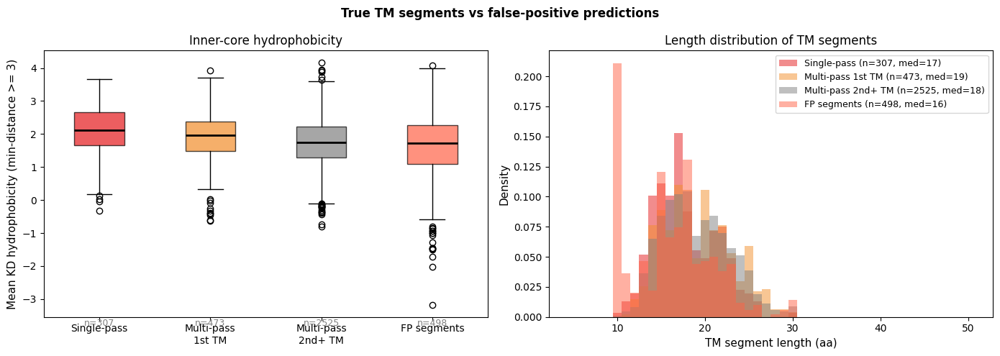

Group                       n   hydro mean   hydro med   len mean   len med
---------------------------------------------------------------------------
Single-pass               307         2.09        2.11       17.7        17
Multi-pass 1st TM         473         1.89        1.96       19.1        19
Multi-pass 2nd+ TM       2525         1.75        1.75       19.0        18
FP segments               498         1.60        1.72       16.2        16


In [183]:
# -- Hydrophobicity and length of false-positive TM segments -----------------
# FP segments come from two sources:
#   1. Alpha-TM proteins where n_pred > n_true  (includes split TMs)
#   2. Non-TM proteins (I/S/T) where any TM is predicted
# Both sets use ALL predicted TM segments from those proteins.

df_ev = pd.read_csv('../results/topo_predictor_evaluated_samples.csv', index_col=0)

def n_tm_str(s):
    if pd.isna(s): return 0
    return sum(1 for k, _ in _gb(s) if k == 'M')

def extract_tm_segs_from_pred(df_sub):
    segs = []
    for _, row in df_sub.iterrows():
        pred = row['pred_topology_deeptm']
        seq  = row['sequence']
        if pd.isna(pred): continue
        pos = 0
        for k, g in _gb(pred):
            length = sum(1 for _ in g)
            if k == 'M':
                segs.append(seq[pos:pos+length])
            pos += length
    return segs

df_ev['n_true_tm'] = df_ev['label'].apply(n_tm_str)
df_ev['n_pred_tm'] = df_ev['pred_topology_deeptm'].apply(n_tm_str)

# Source 1: alpha-TM proteins with more predicted TMs than ground truth
df_over   = df_ev[df_ev['protein_type'].str.contains('M', na=False) &
                   (df_ev['n_pred_tm'] > df_ev['n_true_tm'])]
# Source 2: non-TM proteins with any predicted TM
df_nontm  = df_ev[~df_ev['protein_type'].str.contains('M', na=False) &
                   (df_ev['n_pred_tm'] > 0)]

fp_segs_tm   = extract_tm_segs_from_pred(df_over)
fp_segs_nontm = extract_tm_segs_from_pred(df_nontm)
fp_segs_all  = fp_segs_tm + fp_segs_nontm

print(f'FP segments from over-predicted alpha-TM:  {len(fp_segs_tm)}')
print(f'FP segments from non-TM proteins:           {len(fp_segs_nontm)}')
print(f'Total FP segments:                          {len(fp_segs_all)}')
print()

hydro_fp = mean_hydro_inner(fp_segs_all)
col_fp   = 'tomato'

# ── Plot 1: boxplot of inner-core hydrophobicity ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
data   = [hydro_single_inner, hydro_first_inner, hydro_rest_inner, hydro_fp]
labels = ['Single-pass', 'Multi-pass\n1st TM', 'Multi-pass\n2nd+ TM', 'FP segments']
colors = [col_single, col_first, col_rest, col_fp]
bp = ax.boxplot(data, labels=labels, patch_artist=True,
                medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel(f'Mean KD hydrophobicity (min-distance >= {MIN_DEPTH})', fontsize=11)
ax.set_title('Inner-core hydrophobicity', fontsize=12)
for i, (vals, color) in enumerate(zip(data, colors), start=1):
    ax.text(i, ax.get_ylim()[0] - 0.05, f'n={len(vals)}',
            ha='center', va='top', fontsize=9, color='gray')

# ── Plot 2: length distributions ─────────────────────────────────────────────
ax = axes[1]
lens_data = [
    ([len(s) for s in single_segs],      col_single, 'Single-pass'),
    ([len(s) for s in multi_first_segs], col_first,  'Multi-pass 1st TM'),
    ([len(s) for s in multi_rest_segs],  col_rest,   'Multi-pass 2nd+ TM'),
    ([len(s) for s in fp_segs_all],      col_fp,     'FP segments'),
]
bins = np.arange(4.5, 51.5, 1)
for lens, color, label in lens_data:
    ax.hist(lens, bins=bins, alpha=0.5, color=color,
            label=f'{label} (n={len(lens)}, med={int(np.median(lens))})', density=True)
ax.set_xlabel('TM segment length (aa)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Length distribution of TM segments', fontsize=12)
ax.legend(fontsize=9)

plt.suptitle('True TM segments vs false-positive predictions', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary stats
print(f'{"Group":<22}  {"n":>5}  {"hydro mean":>11}  {"hydro med":>10}  {"len mean":>9}  {"len med":>8}')
print('-' * 75)
for label, segs, hydro in [
    ('Single-pass',        single_segs,      hydro_single_inner),
    ('Multi-pass 1st TM',  multi_first_segs, hydro_first_inner),
    ('Multi-pass 2nd+ TM', multi_rest_segs,  hydro_rest_inner),
    ('FP segments',        fp_segs_all,      hydro_fp),
]:
    lens = [len(s) for s in segs]
    print(f'{label:<22}  {len(hydro):>5}  {np.mean(hydro):>11.2f}  {np.median(hydro):>10.2f}'
          f'  {np.mean(lens):>9.1f}  {np.median(lens):>8.0f}')


True FP segments from over-predicted alpha-TM:  111
True FP segments from non-TM proteins:          108
Total (split-TMs excluded):                     219
(Excluded split-TMs: 279)



/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/1847724650.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labels, patch_artist=True,


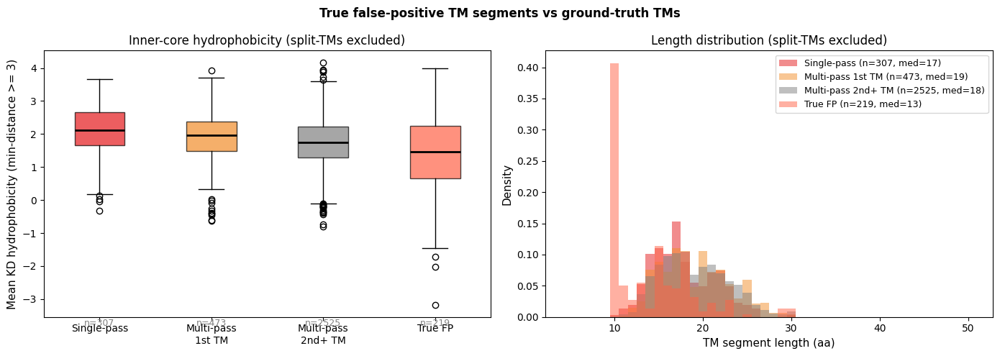

Group                       n   hydro mean   hydro med   len mean   len med
---------------------------------------------------------------------------
Single-pass               307         2.09        2.11       17.7        17
Multi-pass 1st TM         473         1.89        1.96       19.1        19
Multi-pass 2nd+ TM       2525         1.75        1.75       19.0        18
True FP                   219         1.36        1.46       14.1        13


In [184]:
# -- FP analysis: exclude split-TMs, keep only non-overlapping FP segments ---
# A predicted TM segment is a 'true FP' if it has zero overlap
# with every ground-truth TM segment in the same sequence.
# Non-TM proteins are included unchanged (all predicted TMs are true FPs).

def get_tm_ranges(topology):
    """Return list of (start, end) for every M-run in topology string."""
    ranges, pos = [], 0
    for k, g in _gb(topology):
        length = sum(1 for _ in g)
        if k == 'M':
            ranges.append((pos, pos + length))
        pos += length
    return ranges

def overlaps(a_start, a_end, ranges):
    """True if [a_start, a_end) overlaps any range in `ranges`."""
    return any(a_start < b_end and a_end > b_start for b_start, b_end in ranges)

def extract_true_fp_segs(df_sub, has_true_tms=True):
    """Extract predicted TM segments with no ground-truth TM overlap."""
    segs = []
    for _, row in df_sub.iterrows():
        pred = row['pred_topology_deeptm']
        seq  = row['sequence']
        if pd.isna(pred): continue
        gt_ranges = get_tm_ranges(row['label']) if has_true_tms else []
        pos = 0
        for k, g in _gb(pred):
            length = sum(1 for _ in g)
            if k == 'M':
                if not overlaps(pos, pos + length, gt_ranges):
                    segs.append(seq[pos:pos + length])
            pos += length
    return segs

fp_true_tm    = extract_true_fp_segs(df_over,  has_true_tms=True)
fp_true_nontm = extract_true_fp_segs(df_nontm, has_true_tms=False)
fp_true_all   = fp_true_tm + fp_true_nontm

print(f'True FP segments from over-predicted alpha-TM:  {len(fp_true_tm)}')
print(f'True FP segments from non-TM proteins:          {len(fp_true_nontm)}')
print(f'Total (split-TMs excluded):                     {len(fp_true_all)}')
print(f'(Excluded split-TMs: {len(fp_segs_all) - len(fp_true_all)})')
print()

hydro_fp_true = mean_hydro_inner(fp_true_all)

# ── Plot 1: boxplot ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
data   = [hydro_single_inner, hydro_first_inner, hydro_rest_inner, hydro_fp_true]
labels = ['Single-pass', 'Multi-pass\n1st TM', 'Multi-pass\n2nd+ TM', 'True FP']
colors = [col_single, col_first, col_rest, col_fp]
bp = ax.boxplot(data, labels=labels, patch_artist=True,
                medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel(f'Mean KD hydrophobicity (min-distance >= {MIN_DEPTH})', fontsize=11)
ax.set_title('Inner-core hydrophobicity (split-TMs excluded)', fontsize=12)
for i, vals in enumerate(data, start=1):
    ax.text(i, ax.get_ylim()[0] - 0.05, f'n={len(vals)}',
            ha='center', va='top', fontsize=9, color='gray')

# ── Plot 2: length distributions ─────────────────────────────────────────────
ax = axes[1]
bins = np.arange(4.5, 51.5, 1)
for lens, color, label in [
    ([len(s) for s in single_segs],      col_single, 'Single-pass'),
    ([len(s) for s in multi_first_segs], col_first,  'Multi-pass 1st TM'),
    ([len(s) for s in multi_rest_segs],  col_rest,   'Multi-pass 2nd+ TM'),
    ([len(s) for s in fp_true_all],      col_fp,     'True FP'),
]:
    ax.hist(lens, bins=bins, alpha=0.5, color=color, density=True,
            label=f'{label} (n={len(lens)}, med={int(np.median(lens))})')
ax.set_xlabel('TM segment length (aa)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Length distribution (split-TMs excluded)', fontsize=12)
ax.legend(fontsize=9)

plt.suptitle('True false-positive TM segments vs ground-truth TMs', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary stats
print(f'{"Group":<22}  {"n":>5}  {"hydro mean":>11}  {"hydro med":>10}  {"len mean":>9}  {"len med":>8}')
print('-' * 75)
for label, segs, hydro in [
    ('Single-pass',        single_segs,   hydro_single_inner),
    ('Multi-pass 1st TM',  multi_first_segs, hydro_first_inner),
    ('Multi-pass 2nd+ TM', multi_rest_segs,  hydro_rest_inner),
    ('True FP',            fp_true_all,   hydro_fp_true),
]:
    lens = [len(s) for s in segs]
    print(f'{label:<22}  {len(hydro):>5}  {np.mean(hydro):>11.2f}  {np.median(hydro):>10.2f}'
          f'  {np.mean(lens):>9.1f}  {np.median(lens):>8.0f}')


## Extended grammar benchmark

Compare three CRF grammar settings on the 5-fold cross-validation test set:

- **original** — standard model, unchanged grammar  
- **ext_equiv** — extended grammar (Mab1/Mba1 + post states), weights transferred to be equivalent  
- **ext_tuned** — extended grammar with `first_entry = -0.3`, `second_entry = -2.5`

Predictions generated by `scripts/generate_extended_grammar_preds.py` (DeepTMHMM2 repo).


In [19]:
import sys, os
from pathlib import Path

_nb_dir = Path(os.getcwd())          # .../DeepTMHMM2/results
_repo_root = _nb_dir.parent          # .../DeepTMHMM2
_deeptm_root = _repo_root.parent / 'DeepTM'  # .../DeepTM

sys.path.insert(0, str(_deeptm_root))
sys.path.insert(0, str(_repo_root))

import pandas as pd
import numpy as np
from deeptm.utils.metrics import have_equal_topology_with_unknowns

PREDS_BASE = _repo_root / 'results' / 'ext_grammar_benchmark'
SETTINGS   = ['original', 'ext_equiv', 'ext_tuned']
UNPAIRED_MODE = 'start_or_end'

SIDE_LABEL_MAPPING = {
    'A': 'a', 'a': 'b', 'C': 'a', 'c': 'b',
    'D': 'b', 'd': 'a', 'E': 'a', 'e': 'b',
    'G': 'a', 'g': 'b', 'H': 'a', 'h': 'b',
    'J': 'a', 'j': 'b', 'K': 'a', 'k': 'b',
    'L': 'a', 'l': 'b', 'N': 'a', 'n': 'b',
    'P': 'a', 'p': 'b', 'Q': 'a', 'q': 'b',
    'T': 'a', 't': 'b', 'V': 'a', 'v': 'b',
    'W': 'a', 'w': 'b', 'X': 'b', 'x': 'a',
    'Y': 'b', 'y': 'a', 'Z': 'a', 'z': 'b',
    '1': 'a', '2': 'b', '3': 'a', '4': 'b',
    '5': 'a', '6': 'b', '7': 'a', '8': 'b',
    ';': 'a', '?': 'b',
}
_SIDE_REMAP_TEMP = {k: {'a': '-', 'b': '_'}[v] for k, v in SIDE_LABEL_MAPPING.items()}

def remap_true_label(topology):
    for key, val in _SIDE_REMAP_TEMP.items():
        topology = topology.replace(key, val)
    return topology.replace('-', 'a').replace('_', 'b')

def get_determined_start(label, skip_pos_0=True):
    for i, c in enumerate(label):
        if i == 0 and skip_pos_0:
            continue
        if c not in ['U', 'u', '.']:
            return i
    return -1

def load_preds(setting):
    records = []
    for k in range(5):
        path = PREDS_BASE / setting / f'fold{k}' / 'test.preds'
        with open(path) as f:
            lines = [l.rstrip('\n') for l in f]
        records.extend(zip(lines[0::4], lines[1::4], lines[2::4], lines[3::4]))
    return records

def evaluate(records):
    rows = []
    for hdr, seq, raw_true, pred in records:
        ac   = hdr.lstrip('>').split('|')[0]
        true = remap_true_label(raw_true)

        true_tm = true.replace('S','a').replace('>','a').replace('F','a').replace('R','a')
        pred_tm = pred.replace('S','a').replace('>','a').replace('F','a').replace('R','a')
        tm_ok, nterm_ok = have_equal_topology_with_unknowns(
            true_tm, pred_tm,
            unknown_tokens=['U','u','.'],
            minimum_segment_overlaps={'M':5,'B':3,'R':5,'F':5,'S':0,'>':0},
            unpaired_mode=UNPAIRED_MODE,
        )

        if 'M' in true and 'B' not in true:
            type_M = 'M' in pred;  type_B = 'B' not in pred
        elif 'B' in true and 'M' not in true:
            type_B = 'B' in pred;  type_M = 'M' not in pred
        elif 'U' in true and ('S' in true or '>' in true):
            type_M = type_B = bool(tm_ok)
        else:
            type_M = 'M' not in pred;  type_B = 'B' not in pred

        if 'S' in true:
            true_cs = true.rfind('S');  true_lu = get_determined_start(true)
            type_S  = 'S' in pred
            if type_S:
                pred_cs = pred.rfind('S')
                S3 = (pred_cs < true_lu + 3) if true_cs == 0 else (abs(true_cs - pred_cs) <= 3)
            else:
                S3 = False
        elif not true.startswith('U') and not true.startswith('.'):
            type_S = 'S' not in pred;  S3 = None
        else:
            type_S = True;  S3 = None

        if '>' in true:
            true_cs = true.rfind('>');  true_lu = get_determined_start(true)
            type_T  = '>' in pred
            if type_T:
                pred_cs = pred.rfind('>')
                T3 = (pred_cs < true_lu + 3) if true_cs == 0 else (abs(true_cs - pred_cs) <= 3)
            else:
                T3 = False
        elif not true.startswith('U') and not true.startswith('.'):
            type_T = '>' not in pred;  T3 = None
        else:
            type_T = True;  T3 = None

        true_r = true.replace('S','a').replace('>','a').replace('F','a').replace('M','a').replace('B','a')
        pred_r = pred.replace('S','a').replace('>','a').replace('F','a').replace('M','a').replace('B','a')
        r_ok, _ = have_equal_topology_with_unknowns(true_r, pred_r,
            unknown_tokens=['U','u','.'],
            minimum_segment_overlaps={'M':5,'B':3,'R':5,'F':5,'S':0,'>':0},
            unpaired_mode=UNPAIRED_MODE)
        true_f = true.replace('S','a').replace('>','a').replace('R','a').replace('M','a').replace('B','a')
        pred_f = pred.replace('S','a').replace('>','a').replace('R','a').replace('M','a').replace('B','a')
        f_ok, _ = have_equal_topology_with_unknowns(true_f, pred_f,
            unknown_tokens=['U','u','.'],
            minimum_segment_overlaps={'M':5,'B':3,'R':5,'F':5,'S':0,'>':0},
            unpaired_mode=UNPAIRED_MODE)
        type_R = ('R' in pred) if 'R' in true else (True if 'R' not in pred else bool(r_ok))
        type_F = ('F' in pred) if 'F' in true else (True if 'F' not in pred else bool(f_ok))

        s3_ok = S3 if S3 is not None else True
        t3_ok = T3 if T3 is not None else True
        whole = bool(tm_ok) and bool(nterm_ok) and s3_ok and t3_ok

        rows.append(dict(
            AC=ac, label=true, pred=pred,
            tm_correct=bool(tm_ok), nterm_correct=bool(nterm_ok),
            type_M=type_M, type_B=type_B, type_S=type_S, type_T=type_T,
            type_R=type_R, type_F=type_F, S3=S3, T3=T3,
            whole_correct=whole,
        ))
    return pd.DataFrame(rows)

# ── load all three settings ───────────────────────────────────────────────────
dfs = {}
for s in SETTINGS:
    recs  = load_preds(s)
    dfs[s] = evaluate(recs)
    print(f'{s}: {len(recs)} proteins loaded')


original: 8094 proteins loaded
ext_equiv: 8094 proteins loaded
ext_tuned: 8094 proteins loaded


In [20]:
# ── Summary table ─────────────────────────────────────────────────────────────
metrics = [
    ('whole_correct',  'Whole topology'),
    ('tm_correct',     'TM segments'),
    ('nterm_correct',  'N-term orientation'),
    ('type_M',         'Type: α-helical'),
    ('type_B',         'Type: β-barrel'),
    ('type_S',         'Type: signal peptide'),
    ('type_T',         'Type: transit peptide'),
    ('type_R',         'Type: reentrant'),
    ('type_F',         'Type: interfacial'),
]

rows = []
for col, label in metrics:
    r = {'Metric': label}
    for s in SETTINGS:
        d  = dfs[s][col].dropna()
        r[s] = f"{d.mean():.1%}  ({int(d.sum())}/{len(d)})"
    rows.append(r)

# SP / TP cleavage site rows
for col, label in [('S3', 'SP cleavage ±3'), ('T3', 'TP cleavage ±3')]:
    r = {'Metric': label}
    for s in SETTINGS:
        d = dfs[s][col].dropna()
        r[s] = f"{d.mean():.1%}  ({int(d.sum())}/{len(d)})" if len(d) else 'n/a'
    rows.append(r)

df_summary = pd.DataFrame(rows).set_index('Metric')
display(df_summary)


,original,ext_equiv,ext_tuned
Metric,,,
Whole topology,95.0% (7693/8094),95.0% (7693/8094),95.2% (7704/8094)
TM segments,98.3% (7956/8094),98.3% (7956/8094),98.5% (7971/8094)
N-term orientation,97.7% (7905/8094),97.7% (7905/8094),97.8% (7919/8094)
Type: α-helical,98.8% (7996/8094),98.8% (7996/8094),98.9% (8003/8094)
Type: β-barrel,99.9% (8086/8094),99.9% (8086/8094),99.9% (8086/8094)
Type: signal peptide,99.1% (8019/8094),99.1% (8019/8094),99.1% (8019/8094)
Type: transit peptide,98.9% (8007/8094),98.9% (8007/8094),98.9% (8007/8094)
Type: reentrant,99.8% (8075/8094),99.8% (8075/8094),99.8% (8075/8094)
Type: interfacial,98.8% (7994/8094),98.8% (7994/8094),98.7% (7988/8094)


Errors (wrong whole topology) by type:


,original,ext_equiv,ext_tuned
Type,,,
alpha-TM,115/780 (14.7%),115/780 (14.7%),109/780 (14.0%)
beta-TM,22/92 (23.9%),22/92 (23.9%),22/92 (23.9%)
SP only,137/918 (14.9%),137/918 (14.9%),135/918 (14.7%)
TP,91/395 (23.0%),91/395 (23.0%),91/395 (23.0%)
soluble,36/5909 (0.6%),36/5909 (0.6%),33/5909 (0.6%)


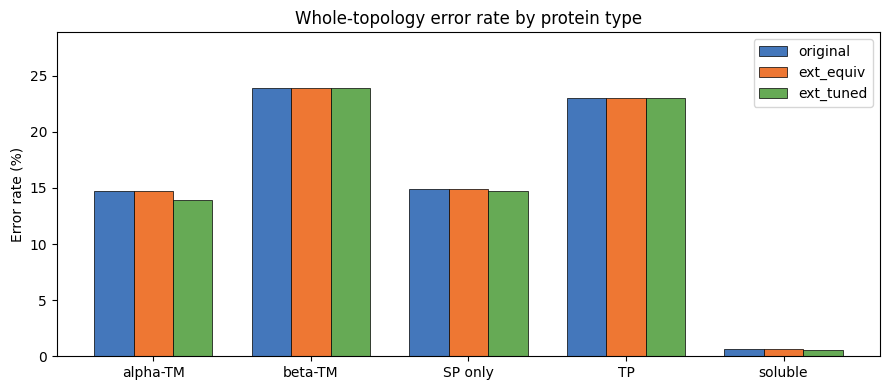

In [21]:
# ── Errors by protein type ────────────────────────────────────────────────────
type_filters = {
    'alpha-TM':  lambda df: df['label'].str.contains('M') & ~df['label'].str.contains('B'),
    'beta-TM':   lambda df: df['label'].str.contains('B'),
    'SP only':   lambda df: df['label'].str.contains('S') & ~df['label'].str.contains('M') & ~df['label'].str.contains('B'),
    'TP':        lambda df: df['label'].str.contains('>') & ~df['label'].str.contains('M'),
    'soluble':   lambda df: ~df['label'].str.contains('M') & ~df['label'].str.contains('B')
                           & ~df['label'].str.contains('S') & ~df['label'].str.contains('>'),
}

error_rows = []
for ptype, mask_fn in type_filters.items():
    r = {'Type': ptype}
    for s in SETTINGS:
        sub = dfs[s][mask_fn(dfs[s])]
        n_wrong = (~sub['whole_correct']).sum()
        r[f'{s}_n']     = len(sub)
        r[f'{s}_wrong'] = int(n_wrong)
        r[s]            = f"{n_wrong}/{len(sub)}  ({100*n_wrong/len(sub):.1f}%)" if len(sub) else 'n/a'
    error_rows.append(r)

df_errors = pd.DataFrame(error_rows).set_index('Type')[[s for s in SETTINGS]]
print("Errors (wrong whole topology) by type:")
display(df_errors)

# ── Bar chart ─────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(type_filters))
width = 0.25
colors = ['#4477bb', '#ee7733', '#66aa55']

for i, s in enumerate(SETTINGS):
    wrong_pct = [
        100 * error_rows[j][f'{s}_wrong'] / error_rows[j][f'{s}_n']
        for j in range(len(error_rows))
    ]
    bars = ax.bar(x + (i - 1) * width, wrong_pct, width, label=s, color=colors[i], edgecolor='black', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(list(type_filters.keys()))
ax.set_ylabel('Error rate (%)')
ax.set_title('Whole-topology error rate by protein type')
ax.legend()
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
#sns.despine(ax=ax)
plt.tight_layout()
plt.show()


In [194]:
# ── Proteins that changed between original → ext_tuned ───────────────────────
import itertools

df_orig  = dfs['original'][['AC','label','pred','whole_correct']].rename(columns={'pred':'pred_orig','whole_correct':'ok_orig'})
df_equiv = dfs['ext_equiv'][['AC','whole_correct']].rename(columns={'whole_correct':'ok_equiv'})
df_tuned = dfs['ext_tuned'][['AC','pred','whole_correct']].rename(columns={'pred':'pred_tuned','whole_correct':'ok_tuned'})

df_cmp = df_orig.merge(df_equiv, on='AC').merge(df_tuned, on='AC')

gained = df_cmp[~df_cmp['ok_orig'] & df_cmp['ok_tuned']]
lost   = df_cmp[df_cmp['ok_orig']  & ~df_cmp['ok_tuned']]

print(f"original errors:  {(~df_cmp['ok_orig']).sum()}")
print(f"ext_tuned errors: {(~df_cmp['ok_tuned']).sum()}")
print(f"Net change:       {(~df_cmp['ok_orig']).sum() - (~df_cmp['ok_tuned']).sum():+d}")
print(f"\nGained (orig wrong → tuned correct): {len(gained)}")
print(f"Lost   (orig correct → tuned wrong):  {len(lost)}")

print("\n── Gained examples (first 20) ──────────────────────────────────────────────")
for _, row in gained.head(20).iterrows():
    n_tm = sum(1 for k, g in itertools.groupby(row['label']) if k == 'M')
    print(f"  {row['AC']:12s}  true_n_TM={n_tm:2d}  label[:200]={row['label'][:200]}")

print("\n── Lost examples (first 20) ─────────────────────────────────────────────────")
for _, row in lost.head(20).iterrows():
    n_tm = sum(1 for k, g in itertools.groupby(row['label']) if k == 'M')
    print(f"  {row['AC']:12s}  true_n_TM={n_tm:2d}")
    print(f"    true:       {row['label'][:400]}")
    print(f"    pred_orig:  {row['pred_orig'][:400]}")
    print(f"    pred_tuned: {row['pred_tuned'][:400]}")


original errors:  401
ext_tuned errors: 390
Net change:       +11

Gained (orig wrong → tuned correct): 15
Lost   (orig correct → tuned wrong):  4

── Gained examples (first 20) ──────────────────────────────────────────────
  E4QEZ3        true_n_TM= 0  label[:200]=SSSSSSSSSSSSSSSSOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOO
  G0S2B3        true_n_TM= 4  label[:200]=UUUUUUUUUUbbbbbbMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMMMMMMMbbbbbbbbbbbbMMMMMMMMMMMMMMaaaaMMMMMMMMMMMMMMMMMbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbU
  I1J9K0        true_n_TM= 6  label[:200]=UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUaaaaFFFFFFFFFFFaaaaaaaaaMMMMMMMMMMMMMMMMMMbbbbbbbbbbMMMMMMMMMMMMMaaaaaaMMMMMMMMMMMMMMMMMMMMMMMMMbbbbbbMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaMMMMMMMMMMMMMMMMMbbbbbbbbbbMMMMM
  L7NUA2        true_n_TM= 7  label[:200]=.....

original: 4854 proteins
finetuned: 4854 proteins
AC sets match ✓

Test clusters 2, 3, 4  (finetuned folds 3, 4, 0 respectively):



,original,finetuned
Metric,,
Whole topology,95.4% (4633/4854),94.7% (4595/4854)
TM segments,98.4% (4776/4854),98.2% (4766/4854)
N-term orientation,97.8% (4746/4854),97.6% (4737/4854)
Type: α-helical,98.8% (4794/4854),98.9% (4799/4854)
Type: β-barrel,99.9% (4850/4854),99.9% (4849/4854)
Type: signal peptide,99.3% (4818/4854),98.9% (4801/4854)
Type: transit peptide,99.0% (4807/4854),98.9% (4800/4854)



Errors (wrong whole topology) by type:


,original,finetuned
Type,,
α-helical,62/468 (13.2%),75/468 (16.0%)
β-barrel,13/54 (24.1%),17/54 (31.5%)
SP only,77/550 (14.0%),79/550 (14.4%)
soluble,24/3545 (0.7%),32/3545 (0.9%)


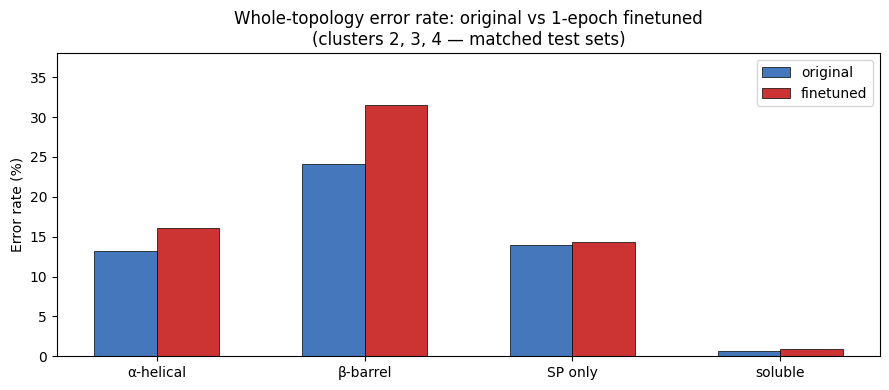


original errors:  221
finetuned errors: 259
Net change: -38

Gained (orig wrong → finetuned correct): 44
Lost   (orig correct → finetuned wrong):  82

── Gained ──────────────────────────────────────────────────────────────
  Q92643        n_TM=1  true: SSSSSSSSSSSSSSSSSSSSSSSSSSSbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbb
                        orig: SSSSSSSSSSSSSSSSSSSSSSSSSSSbbbbbbbbbbbbbbbbbbbbMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa
                        fine: SSSSSSSSSSSSSSSSSSSSSSSSSSSbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbb
  P20292        n_TM=4  true: bbbbbbbbbbbMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMbbbbbbMMMMMMMMMMMMMMaaaaaaaaaaaUUUaaaaaaMMMMM
                        orig: bbbbbbMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMMMMMMMMMMbbbbbMMMMMMMMMMMMMMMMMMaaaaaaaaaaaMMMMMMMMMM
                    

In [24]:
# ── Finetuned extended grammar: performance on the 3 non-NaN folds (0, 3, 4) ──
# Folds 1 and 2 produced NaN weights (gradient explosion on CPU float32,
# fixed in GPU runs via GradScaler).
#
# The original benchmark used test_idx = fold_number (cluster k for fold k).
# The finetuned models use Felix's convention: test_idx = (fold - 1) % 5.
# We cross-match by test cluster so both columns evaluate the same proteins:
#
#   Finetuned fold 0  → test cluster 4  ↔  Original fold 4  (cluster 4)
#   Finetuned fold 3  → test cluster 2  ↔  Original fold 2  (cluster 2)
#   Finetuned fold 4  → test cluster 3  ↔  Original fold 3  (cluster 3)

FTUNE_PRED_DIR = Path("/Users/olwi/git/DeepTM/outputs/finetune_local")

# (finetune_fold, matching_orig_fold)
FOLD_PAIRS = [(0, 4), (3, 2), (4, 3)]

def load_preds_from_path(path):
    with open(path) as f:
        lines = [l.rstrip('\n') for l in f]
    return list(zip(lines[0::4], lines[1::4], lines[2::4], lines[3::4]))

orig_recs, ft_recs = [], []
for ft_fold, orig_fold in FOLD_PAIRS:
    orig_recs += load_preds_from_path(PREDS_BASE / 'original'  / f'fold{orig_fold}' / 'test.preds')
    ft_recs   += load_preds_from_path(FTUNE_PRED_DIR / f'finetune_ext_fold{ft_fold}' / 'last_preds' / 'test.preds')

dfs_ft = {
    'original':  evaluate(orig_recs).set_index('AC'),
    'finetuned': evaluate(ft_recs).set_index('AC'),
}
for s, df in dfs_ft.items():
    print(f'{s}: {len(df)} proteins')

# Sanity-check: same set of ACs (order may differ between pred files)
assert set(dfs_ft['original'].index) == set(dfs_ft['finetuned'].index), \
    "AC set mismatch — test clusters do not correspond!"
print("AC sets match ✓")

# ── Summary table ─────────────────────────────────────────────────────────────
SETTINGS_FT = ['original', 'finetuned']
rows = []
for col, label in [
    ('whole_correct', 'Whole topology'),
    ('tm_correct',    'TM segments'),
    ('nterm_correct', 'N-term orientation'),
    ('type_M',        'Type: α-helical'),
    ('type_B',        'Type: β-barrel'),
    ('type_S',        'Type: signal peptide'),
    ('type_T',        'Type: transit peptide'),
]:
    r = {'Metric': label}
    for s in SETTINGS_FT:
        d = dfs_ft[s][col].dropna()
        r[s] = f"{d.mean():.1%}  ({int(d.sum())}/{len(d)})"
    rows.append(r)

df_sum_ft = pd.DataFrame(rows).set_index('Metric')
print(f"\nTest clusters 2, 3, 4  (finetuned folds 3, 4, 0 respectively):\n")
display(df_sum_ft)

# ── Error-rate bar chart ──────────────────────────────────────────────────────
type_filters = {
    'α-helical': lambda df: df['label'].str.contains('M') & ~df['label'].str.contains('B'),
    'β-barrel':  lambda df: df['label'].str.contains('B'),
    'SP only':   lambda df: df['label'].str.contains('S') & ~df['label'].str.contains('M') & ~df['label'].str.contains('B'),
    'soluble':   lambda df: ~df['label'].str.contains('M') & ~df['label'].str.contains('B')
                            & ~df['label'].str.contains('S') & ~df['label'].str.contains('>'),
}

error_rows = []
for ptype, mask_fn in type_filters.items():
    r = {'Type': ptype}
    for s in SETTINGS_FT:
        sub = dfs_ft[s][mask_fn(dfs_ft[s])]
        n_wrong = (~sub['whole_correct']).sum()
        r[f'{s}_n'] = len(sub); r[f'{s}_wrong'] = int(n_wrong)
        r[s] = f"{n_wrong}/{len(sub)}  ({100*n_wrong/len(sub):.1f}%)" if len(sub) else 'n/a'
    error_rows.append(r)

print("\nErrors (wrong whole topology) by type:")
display(pd.DataFrame(error_rows).set_index('Type')[SETTINGS_FT])

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(type_filters))
width = 0.3
colors = ['#4477bb', '#cc3333']
for i, s in enumerate(SETTINGS_FT):
    wrong_pct = [100 * error_rows[j][f'{s}_wrong'] / error_rows[j][f'{s}_n']
                 for j in range(len(error_rows))]
    ax.bar(x + (i - 0.5) * width, wrong_pct, width, label=s, color=colors[i],
           edgecolor='black', linewidth=0.5)
ax.set_xticks(x); ax.set_xticklabels(list(type_filters.keys()))
ax.set_ylabel('Error rate (%)')
ax.set_title('Whole-topology error rate: original vs 1-epoch finetuned\n(clusters 2, 3, 4 — matched test sets)')
ax.legend(); ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.tight_layout(); plt.show()

# ── Proteins that changed: original → finetuned ───────────────────────────────
# Merge on AC to handle different ordering in the two pred files
import itertools
df_cmp = dfs_ft['original'][['label','pred','whole_correct']].rename(
    columns={'pred': 'pred_orig', 'whole_correct': 'ok_orig'}
).join(
    dfs_ft['finetuned'][['pred','whole_correct']].rename(
        columns={'pred': 'pred_ft', 'whole_correct': 'ok_ft'})
)

gained = df_cmp[~df_cmp['ok_orig'] &  df_cmp['ok_ft']]
lost   = df_cmp[ df_cmp['ok_orig'] & ~df_cmp['ok_ft']]

print(f"\noriginal errors:  {(~df_cmp['ok_orig']).sum()}")
print(f"finetuned errors: {(~df_cmp['ok_ft']).sum()}")
print(f"Net change: {(~df_cmp['ok_orig']).sum() - (~df_cmp['ok_ft']).sum():+d}")
print(f"\nGained (orig wrong → finetuned correct): {len(gained)}")
print(f"Lost   (orig correct → finetuned wrong):  {len(lost)}")

for title, sub in [("Gained", gained), ("Lost", lost)]:
    print(f"\n── {title} ──────────────────────────────────────────────────────────────")
    for ac, row in sub.iterrows():
        n_tm = sum(1 for k, g in itertools.groupby(row['label']) if k == 'M')
        print(f"  {ac:12s}  n_TM={n_tm}  true: {row['label'][:120]}")
        print(f"  {'':12s}          orig: {row['pred_orig'][:120]}")
        print(f"  {'':12s}          fine: {row['pred_ft'][:120]}")


In [ ]:
# ── Run the parameter sweep (generates predictions for all grid points) ──────
# This takes a while: ESM2 runs once per sequence per fold,
# then CRF Viterbi is repeated for each (first_entry, second_entry) pair.
import subprocess, sys

result = subprocess.run(
    [sys.executable, str(_repo_root / 'scripts' / 'sweep_extended_grammar_preds.py'),
     '--checkpoint-dir', str(_repo_root / 'checkpoints'),
     '--output-dir',     str(_repo_root / 'results' / 'ext_grammar_sweep'),
    ],
    cwd=str(_repo_root),
    capture_output=False,   # stream stdout/stderr directly to notebook output
)
print(f'\nExit code: {result.returncode}')


In [ ]:
# ── Extended grammar parameter sweep ─────────────────────────────────────────
# Run scripts/sweep_extended_grammar_preds.py first to generate predictions.
# This cell loads every (first_entry, second_entry) pair and shows a heatmap
# of whole-topology errors across the sweep grid.

import re
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

SWEEP_BASE = _repo_root / 'results' / 'ext_grammar_sweep'

def _parse_val(s):
    """'m2p5' → -2.5,  'None' → None,  '0p0' → 0.0"""
    if s == 'None':
        return None
    return float(s.replace('p', '.').replace('m', '-'))

# ── discover all settings on disk ────────────────────────────────────────────
sweep_dirs = sorted(d for d in SWEEP_BASE.iterdir()
                    if d.is_dir() and d.name != 'original')

sweep_results = {}   # (first, second) → whole_error_count
for d in sweep_dirs:
    m = re.fullmatch(r'fe(.+)_se(.+)', d.name)
    if not m:
        continue
    fe = _parse_val(m.group(1))
    se = _parse_val(m.group(2))
    try:
        recs = load_preds_from_path_5fold(d)   # defined below
        df   = evaluate(recs)
        sweep_results[(fe, se)] = int((~df['whole_correct']).sum())
    except FileNotFoundError:
        pass   # fold not yet generated

# ── helper: load all 5 folds from a sweep dir ────────────────────────────────
def load_preds_from_path_5fold(base_dir):
    recs = []
    for k in range(5):
        p = base_dir / f'fold{k}' / 'test.preds'
        if p.exists():
            recs += load_preds_from_path(p)
    return recs

# re-evaluate with the helper defined above
sweep_results = {}
for d in sweep_dirs:
    m = re.fullmatch(r'fe(.+)_se(.+)', d.name)
    if not m:
        continue
    fe = _parse_val(m.group(1))
    se = _parse_val(m.group(2))
    recs = load_preds_from_path_5fold(d)
    if not recs:
        continue
    df = evaluate(recs)
    sweep_results[(fe, se)] = int((~df['whole_correct']).sum())

# baseline: original model (no extended grammar)
orig_recs = load_preds_from_path_5fold(SWEEP_BASE / 'original')
orig_errors = int((~evaluate(orig_recs)['whole_correct']).sum()) if orig_recs else None

print(f'Original errors: {orig_errors}')
print(f'Sweep points evaluated: {len(sweep_results)}')

if sweep_results:
    # ── build heatmap matrix ─────────────────────────────────────────────────
    first_vals  = sorted(set(k[0] for k in sweep_results.keys()),
                         key=lambda v: float('inf') if v is None else v, reverse=True)
    second_vals = sorted(set(k[1] for k in sweep_results.keys()),
                         key=lambda v: float('inf') if v is None else v, reverse=True)

    matrix = []
    for fe in first_vals:
        row = [sweep_results.get((fe, se), float('nan')) for se in second_vals]
        matrix.append(row)

    import numpy as np
    mat = np.array(matrix, dtype=float)

    fig, ax = plt.subplots(figsize=(max(6, len(second_vals) * 1.1), max(4, len(first_vals) * 0.9)))
    im = ax.imshow(mat, aspect='auto', cmap='RdYlGn_r',
                   vmin=max(0, mat[~np.isnan(mat)].min() - 2),
                   vmax=mat[~np.isnan(mat)].max() + 2)
    plt.colorbar(im, ax=ax, label='Whole-topology errors')

    ax.set_xticks(range(len(second_vals)))
    ax.set_xticklabels([str(v) for v in second_vals], rotation=45, ha='right')
    ax.set_yticks(range(len(first_vals)))
    ax.set_yticklabels([str(v) for v in first_vals])
    ax.set_xlabel('second_entry (penalty for 2nd+ TM crossing)')
    ax.set_ylabel('first_entry (penalty for 1st TM crossing)')
    ax.set_title('Extended grammar sweep — whole-topology errors (5-fold CV)')

    # annotate cells
    for i in range(len(first_vals)):
        for j in range(len(second_vals)):
            v = mat[i, j]
            if not np.isnan(v):
                ax.text(j, i, str(int(v)), ha='center', va='center', fontsize=9,
                        color='black')

    # mark original baseline
    if orig_errors is not None:
        ax.set_title(ax.get_title() + f'\n(original baseline = {orig_errors} errors)')

    plt.tight_layout()
    plt.show()

    # ── best settings ─────────────────────────────────────────────────────────
    best = min(sweep_results, key=sweep_results.get)
    print(f'\nBest setting: first_entry={best[0]}, second_entry={best[1]}  '
          f'→ {sweep_results[best]} errors')
    if orig_errors:
        print(f'  vs original: {sweep_results[best] - orig_errors:+d}  '
              f'({100*(sweep_results[best]-orig_errors)/orig_errors:+.1f}%)')

    # ── table of top-10 settings ──────────────────────────────────────────────
    top = sorted(sweep_results.items(), key=lambda x: x[1])[:10]
    print('\nTop 10 settings:')
    print(f'  {"first_entry":>12}  {"second_entry":>13}  errors  vs_orig')
    for (fe, se), err in top:
        delta = f'{err - orig_errors:+d}' if orig_errors else 'n/a'
        print(f'  {str(fe):>12}  {str(se):>13}  {err:>6}  {delta}')


In [ ]:
# ── Diagnose huge CRF losses in AlphaFold training sequences ─────────────────
# Two hypotheses:
#   (1) Forbidden state *transitions* between consecutive valid positions
#   (2) NaN / Inf values in the pre-computed embedding
# validate_alphafold_labels.py checked individual positions (no all-zero rows found),
# but did NOT check whether consecutive valid-state pairs have any allowed transition.
# The CRF uses -1e14 for forbidden transitions; losses -2e14, -4e14 etc. mean
# the true-label path crosses 2, 4, ... forbidden transitions.

import sys, hashlib, os
from pathlib import Path
import numpy as np
import pandas as pd
import torch

_nb_dir = Path(os.getcwd())
_deeptm = _nb_dir.parent.parent / 'DeepTM'
sys.path.insert(0, str(_deeptm))
sys.path.insert(0, str(_nb_dir.parent))

from deeptm.utils.crf_config import SplitIOCRFwithTPConfig

crf_cfg = SplitIOCRFwithTPConfig(
    type_label_to_int={
        'None': -1, 'I': 0, 'S': 1, 'M': 2, 'M+S': 3,
        'B': 4, 'M+R': 5, 'M+F': 6, 'M+R+F': 6, 'T': 7, 'M+T': 8,
    },
    maximum_segment_lengths={
        'S': -1, '>': -1, 'M': 30, 'B': 15, 'R': -1, 'F': -1,
        'Mab': 30, 'Mba': 30, 'Bab': 15, 'Bba': 15,
        'Raa': -1, 'Rbb': -1, 'Faa': -1, 'Fbb': -1,
    },
    minimum_segment_lengths={
        'S': 10, '>': 5, 'M': 10, 'B': 5, 'R': 8, 'F': 5,
        'Mab': 10, 'Mba': 10, 'Bab': 5, 'Bba': 5,
        'Raa': 8, 'Rbb': 8, 'Faa': 5, 'Fbb': 5,
    },
    use_start_end_transitions=True,
    extend_first_tm=True,
)
n_states = len(crf_cfg.crf_states)

# Build (n_states x n_states) boolean constraint matrix from allowed transitions
allowed = set(crf_cfg.allowed_state_transitions)
constraint = np.zeros((n_states, n_states), dtype=bool)
for (s1, s2) in allowed:
    constraint[s1, s2] = True

print(f"CRF states: {n_states},  allowed transitions: {len(allowed)}")

# ── Scan all embedded AF sequences ───────────────────────────────────────────
emb_dir = _deeptm / 'data/embeddings_local'
af_df = pd.concat([
    pd.read_csv(_deeptm / 'data/prepare_alphafold/alpha_hits_embedded.csv'),
    pd.read_csv(_deeptm / 'data/prepare_alphafold/beta_hits_embedded.csv'),
], ignore_index=True)
print(f"Total embedded AF sequences: {len(af_df)}")

results = []
for idx, row in af_df.iterrows():
    seq   = str(row['tseq'])
    label = str(row['label']).replace('u', 'U')

    # 1. Check embedding for NaN / Inf
    emb_path = emb_dir / f'{hashlib.md5(seq.encode()).hexdigest()}.pt'
    nan_count = inf_count = 0
    if emb_path.exists():
        emb = torch.load(emb_path, map_location='cpu', weights_only=False)
        nan_count = int(torch.isnan(emb).sum())
        inf_count = int(torch.isinf(emb).sum())

    # 2. Check for positions where ALL valid-state transitions are forbidden
    mat = crf_cfg.get_multi_tag_label_matrix(label)   # (L, N_states)
    dead_positions = 0
    for t in range(len(mat) - 1):
        valid_from = np.where(mat[t]   > 0)[0]
        valid_to   = np.where(mat[t+1] > 0)[0]
        if len(valid_from) == 0 or len(valid_to) == 0:
            dead_positions += 1
            continue
        sub = constraint[np.ix_(valid_from, valid_to)]
        if not sub.any():
            dead_positions += 1

    results.append({
        'label_prefix': label[:40], 'len': len(seq),
        'nan': nan_count, 'inf': inf_count,
        'dead_positions': dead_positions,
    })

df_res = pd.DataFrame(results)
print(f"\nEmbeddings with NaN:            {(df_res.nan > 0).sum()}")
print(f"Embeddings with Inf:            {(df_res.inf > 0).sum()}")
print(f"Seqs with dead transitions:     {(df_res.dead_positions > 0).sum()}  "
      f"({100*(df_res.dead_positions > 0).mean():.1f}% of AF sequences)")

bad = df_res[df_res.dead_positions > 0].copy()
if len(bad) > 0:
    print("\nExample bad sequences (label_prefix | len | dead_positions):")
    print(bad[['label_prefix', 'len', 'dead_positions']].head(10).to_string(index=False))
else:
    print("\nNo forbidden-transition issues found — checking NaN more carefully:")
    print(df_res[df_res.nan > 0].head(5))


/Users/olwi/git/DeepTM/deeptm/utils/crf_config/crf_config_with_tp_split_io.py:120: UserWarning: Duplicate values in type_label_to_int configuration. This will cause the affected types to be collapsed into one type. Make sure this is intentional.
  warnings.warn(f"Duplicate values in type_label_to_int configuration. This will cause the affected types to be collapsed into one type. Make sure this is intentional.")


CRF states: 197,  allowed transitions: 319
Total embedded AF sequences: 14160

Embeddings with NaN:            0
Embeddings with Inf:            0
Seqs with dead transitions:     9374  (66.2% of AF sequences)

Example bad sequences (label_prefix | len | dead_positions):
                            label_prefix  len  dead_positions
UUUUUUUUUUUUMMMMMMMMMMMMMMMMUUUUUUUUMMMM  634               4
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU  773               4
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU  531               8
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU 1272              14
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUMMMMMM  900              12
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU  898              12
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU  530               4
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUMMMMMMMM  466               6
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU  286               8
UUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUUU  926               8


/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/3109928196.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


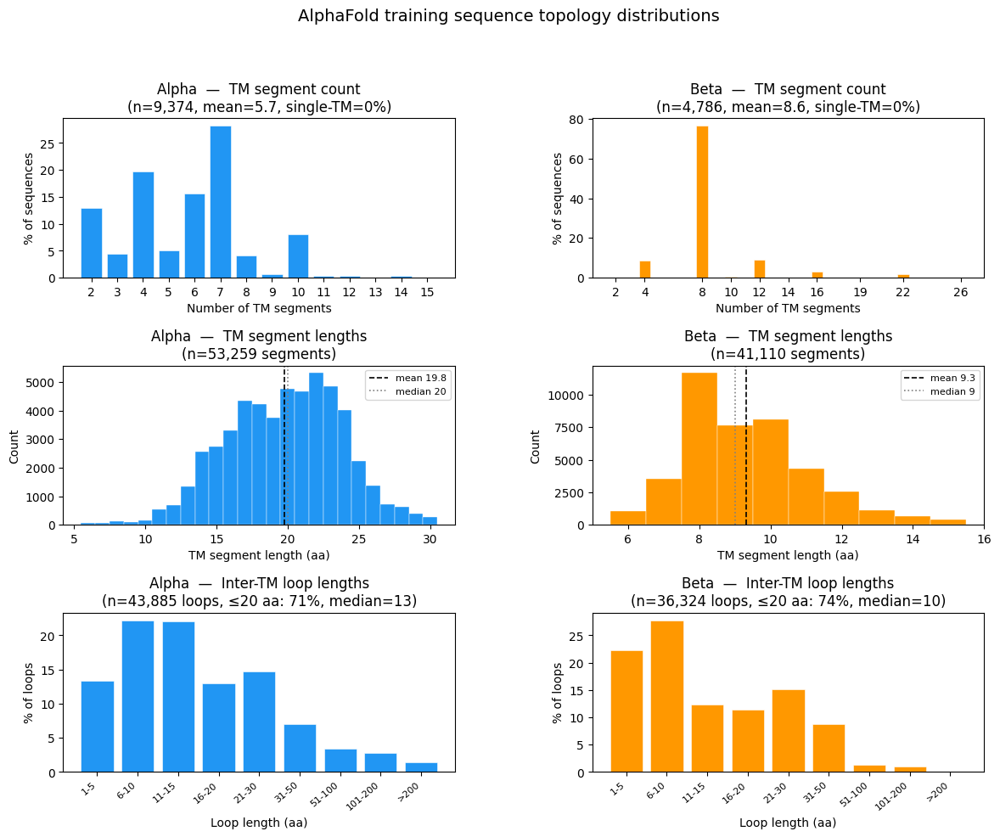

In [199]:

# ── AlphaFold sequence topology analysis ─────────────────────────────────────
# For alpha and beta AF sequences, plot:
#   1. Distribution over number of TM segments
#   2. Distribution of TM segment lengths
#   3. Distribution of inter-segment loop lengths

import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

_deeptm = Path(os.getcwd()).parent.parent / 'DeepTM'

TM_CHARS  = {'M', 'B', 'R', 'F'}
GLOB_CHARS = {'a', 'b', 'U', 'u', '.'}

def parse_segments(label):
    label = str(label).replace('u', 'U')
    segs, i = [], 0
    while i < len(label):
        ch, j = label[i], i + 1
        while j < len(label) and label[j] == ch:
            j += 1
        segs.append((ch, j - i))
        i = j
    return segs

def tm_segments(label):
    return [(t, l) for t, l in parse_segments(label) if t in TM_CHARS]

def loop_lengths(label):
    segs   = parse_segments(label)
    tm_idx = [i for i, (t, _) in enumerate(segs) if t in TM_CHARS]
    return [sum(l for _, l in segs[tm_idx[i]+1:tm_idx[i+1]])
            for i in range(len(tm_idx) - 1)]

data = {}
for name, csv in [('Alpha', 'data/prepare_alphafold/alpha_hits_embedded.csv'),
                  ('Beta',  'data/prepare_alphafold/beta_hits_embedded.csv')]:
    df = pd.read_csv(_deeptm / csv)
    labels = df['label'].astype(str)
    tms  = [tm_segments(l) for l in labels]
    data[name] = dict(
        n_segs   = [len(t) for t in tms],
        tm_lens  = [l for t in tms for _, l in t],
        loops    = [ll for l in labels for ll in loop_lengths(l)],
    )

fig = plt.figure(figsize=(14, 10))
fig.suptitle('AlphaFold training sequence topology distributions', fontsize=14, y=1.01)
gs  = gridspec.GridSpec(3, 2, hspace=0.55, wspace=0.35)

colors = {'Alpha': '#2196F3', 'Beta': '#FF9800'}

for col, name in enumerate(['Alpha', 'Beta']):
    d = data[name]
    c = colors[name]

    # ── 1. Number of TM segments ──────────────────────────────────────────────
    ax = fig.add_subplot(gs[0, col])
    vals = pd.Series(d['n_segs'])
    vc   = vals.value_counts().sort_index()
    ax.bar(vc.index, vc.values / len(vals) * 100, color=c, edgecolor='white', linewidth=0.4)
    ax.set_xlabel('Number of TM segments')
    ax.set_ylabel('% of sequences')
    ax.set_title(f'{name}  —  TM segment count\n(n={len(vals):,}, mean={vals.mean():.1f}, '
                 f'single-TM={100*(vals==1).mean():.0f}%)')
    ax.set_xticks(sorted(vc.index))

    # ── 2. TM segment lengths ─────────────────────────────────────────────────
    ax = fig.add_subplot(gs[1, col])
    tl  = pd.Series(d['tm_lens'])
    bins = np.arange(tl.min() - 0.5, tl.max() + 1.5, 1)
    ax.hist(tl, bins=bins, color=c, edgecolor='white', linewidth=0.3)
    ax.axvline(tl.mean(),   color='black', linestyle='--', linewidth=1.2, label=f'mean {tl.mean():.1f}')
    ax.axvline(tl.median(), color='grey',  linestyle=':',  linewidth=1.2, label=f'median {tl.median():.0f}')
    ax.set_xlabel('TM segment length (aa)')
    ax.set_ylabel('Count')
    ax.set_title(f'{name}  —  TM segment lengths\n(n={len(tl):,} segments)')
    ax.legend(fontsize=8)

    # ── 3. Inter-segment loop lengths ─────────────────────────────────────────
    ax = fig.add_subplot(gs[2, col])
    ll  = pd.Series(d['loops'])
    bins = [0, 5, 10, 15, 20, 30, 50, 100, 200, ll.max() + 1]
    labels_b = ['1-5', '6-10', '11-15', '16-20', '21-30', '31-50', '51-100', '101-200', '>200']
    counts = pd.cut(ll, bins=bins, labels=labels_b).value_counts().sort_index()
    ax.bar(range(len(counts)), counts.values / len(ll) * 100, color=c, edgecolor='white', linewidth=0.4)
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(labels_b, rotation=40, ha='right', fontsize=8)
    ax.set_xlabel('Loop length (aa)')
    ax.set_ylabel('% of loops')
    short = 100 * (ll <= 20).mean()
    ax.set_title(f'{name}  —  Inter-TM loop lengths\n'
                 f'(n={len(ll):,} loops, ≤20 aa: {short:.0f}%, median={ll.median():.0f})')

plt.tight_layout()
plt.show()


/var/folders/87/wzbf1q15141_6fz0dv_9dccc0000gr/T/ipykernel_9922/2740397315.py:102: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


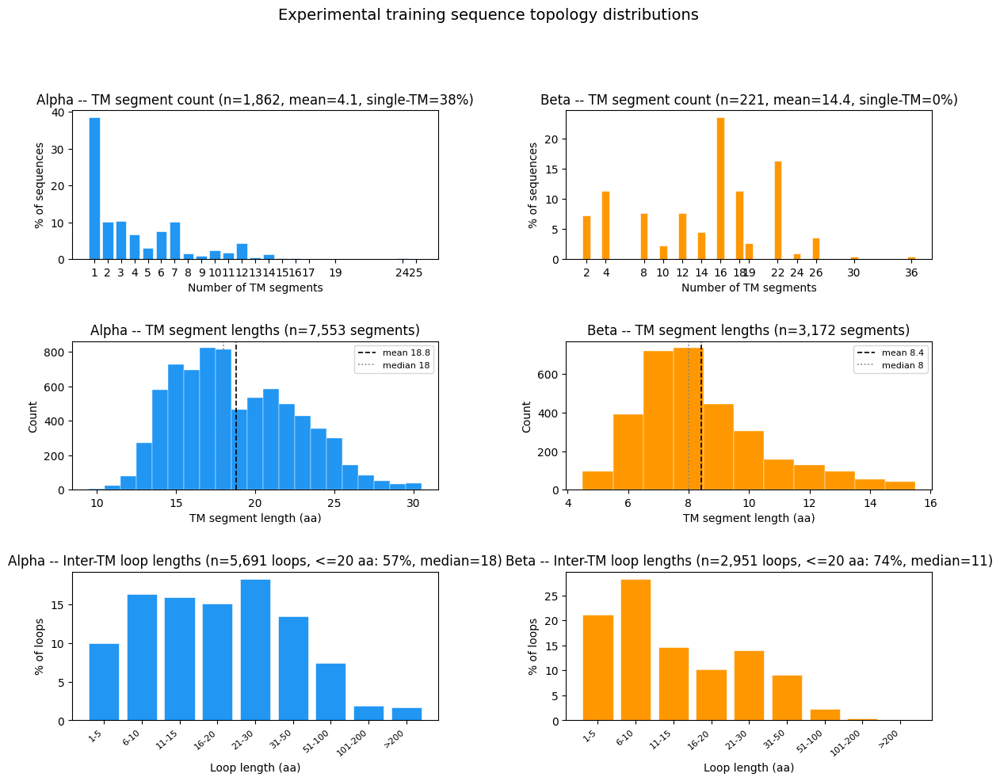

In [198]:
# ── Experimental dataset topology distributions ───────────────────────────
# Same plots as the AF cell above, but for the curated experimental fasta files.
# TM chars: M for alpha helices, B for beta barrel strands.

import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

_deeptm = Path(os.getcwd()).parent.parent / "DeepTM"

def parse_segments(label):
    segs, i = [], 0
    while i < len(label):
        ch, j = label[i], i + 1
        while j < len(label) and label[j] == ch:
            j += 1
        segs.append((ch, j - i))
        i = j
    return segs

def tm_segments(label, tm_chars):
    return [(t, l) for t, l in parse_segments(label) if t in tm_chars]

def loop_lengths(label, tm_chars):
    segs   = parse_segments(label)
    tm_idx = [i for i, (t, _) in enumerate(segs) if t in tm_chars]
    return [sum(l for _, l in segs[tm_idx[i]+1:tm_idx[i+1]])
            for i in range(len(tm_idx) - 1)]

def read_3line_fasta(path):
    labels = []
    with open(path) as f:
        lines = [l.rstrip() for l in f if l.strip()]
    for i in range(0, len(lines), 3):
        labels.append(lines[i+2])
    return labels

data = {}
for name, fname, tm_chars in [
    ("Alpha", "alpha.3line.fasta", {"M"}),
    ("Beta",  "beta.3line.fasta",  {"B"}),
]:
    labels = read_3line_fasta(_deeptm / "data/split_reduced/fasta" / fname)
    tms  = [tm_segments(l, tm_chars) for l in labels]
    data[name] = dict(
        n_segs  = [len(t) for t in tms],
        tm_lens = [l for t in tms for _, l in t],
        loops   = [ll for l in labels for ll in loop_lengths(l, tm_chars)],
    )

fig = plt.figure(figsize=(14, 10))
fig.suptitle("Experimental training sequence topology distributions", fontsize=14, y=1.01)
gs  = gridspec.GridSpec(3, 2, hspace=0.55, wspace=0.35)

colors = {"Alpha": "#2196F3", "Beta": "#FF9800"}

for col, name in enumerate(["Alpha", "Beta"]):
    d = data[name]
    c = colors[name]

    ax = fig.add_subplot(gs[0, col])
    vals = pd.Series(d["n_segs"])
    vc   = vals.value_counts().sort_index()
    ax.bar(vc.index, vc.values / len(vals) * 100, color=c, edgecolor="white", linewidth=0.4)
    ax.set_xlabel("Number of TM segments")
    ax.set_ylabel("% of sequences")
    title = "{} -- TM segment count (n={:,}, mean={:.1f}, single-TM={:.0f}%)".format(
        name, len(vals), vals.mean(), 100*(vals==1).mean())
    ax.set_title(title)
    ax.set_xticks(sorted(vc.index))

    ax = fig.add_subplot(gs[1, col])
    tl  = pd.Series(d["tm_lens"])
    bins = np.arange(tl.min() - 0.5, tl.max() + 1.5, 1)
    ax.hist(tl, bins=bins, color=c, edgecolor="white", linewidth=0.3)
    ax.axvline(tl.mean(),   color="black", linestyle="--", linewidth=1.2, label="mean {:.1f}".format(tl.mean()))
    ax.axvline(tl.median(), color="grey",  linestyle=":",  linewidth=1.2, label="median {:.0f}".format(tl.median()))
    ax.set_xlabel("TM segment length (aa)")
    ax.set_ylabel("Count")
    ax.set_title("{} -- TM segment lengths (n={:,} segments)".format(name, len(tl)))
    ax.legend(fontsize=8)

    ax = fig.add_subplot(gs[2, col])
    ll  = pd.Series(d["loops"])
    bins_l   = [0, 5, 10, 15, 20, 30, 50, 100, 200, int(ll.max()) + 1]
    labels_b = ["1-5", "6-10", "11-15", "16-20", "21-30", "31-50", "51-100", "101-200", ">200"]
    counts = pd.cut(ll, bins=bins_l, labels=labels_b).value_counts().sort_index()
    ax.bar(range(len(counts)), counts.values / len(ll) * 100, color=c, edgecolor="white", linewidth=0.4)
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(labels_b, rotation=40, ha="right", fontsize=8)
    ax.set_xlabel("Loop length (aa)")
    ax.set_ylabel("% of loops")
    short = 100 * (ll <= 20).mean() if len(ll) > 0 else 0
    med   = ll.median() if len(ll) > 0 else 0
    title = "{} -- Inter-TM loop lengths (n={:,} loops, <=20 aa: {:.0f}%, median={:.0f})".format(
        name, len(ll), short, med)
    ax.set_title(title)

plt.tight_layout()
plt.show()


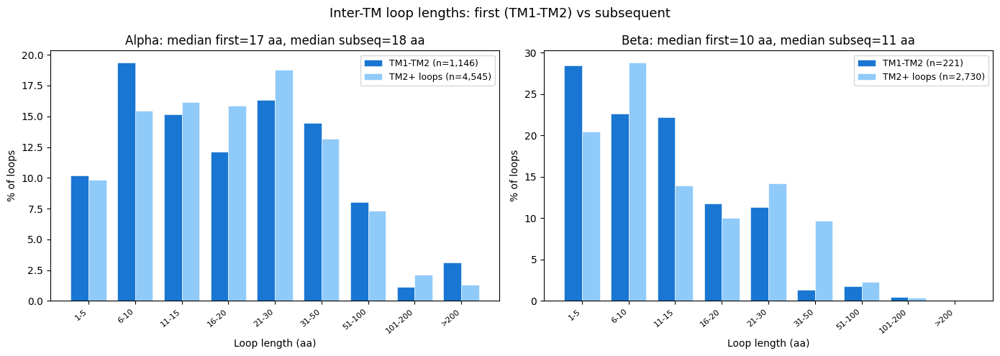

In [200]:
# ── First vs subsequent inter-TM loop lengths (experimental) ─────────────────
# The loop between TM1 and TM2 is structurally special (first re-entry loop).
# Compare its length distribution against all subsequent loops.

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_deeptm = Path(os.getcwd()).parent.parent / "DeepTM"

def parse_segments(label):
    segs, i = [], 0
    while i < len(label):
        ch, j = label[i], i + 1
        while j < len(label) and label[j] == ch:
            j += 1
        segs.append((ch, j - i))
        i = j
    return segs

def split_loops(label, tm_chars):
    """Return (first_loop_len, [subsequent_loop_lens]) or (None, []) if <2 TM segs."""
    segs   = parse_segments(label)
    tm_idx = [i for i, (t, _) in enumerate(segs) if t in tm_chars]
    if len(tm_idx) < 2:
        return None, []
    loops = [sum(l for _, l in segs[tm_idx[i]+1:tm_idx[i+1]])
             for i in range(len(tm_idx) - 1)]
    return loops[0], loops[1:]

def read_3line_fasta(path):
    with open(path) as f:
        lines = [l.rstrip() for l in f if l.strip()]
    return [lines[i+2] for i in range(0, len(lines), 3)]

bins_l   = [0, 5, 10, 15, 20, 30, 50, 100, 200, 9999]
bin_labs = ["1-5", "6-10", "11-15", "16-20", "21-30", "31-50", "51-100", "101-200", ">200"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Inter-TM loop lengths: first (TM1-TM2) vs subsequent", fontsize=13)

for ax, (name, fname, tm_chars) in zip(axes, [
    ("Alpha", "alpha.3line.fasta", {"M"}),
    ("Beta",  "beta.3line.fasta",  {"B"}),
]):
    labels = read_3line_fasta(_deeptm / "data/split_reduced/fasta" / fname)
    first_loops, subseq_loops = [], []
    for lab in labels:
        f, s = split_loops(lab, tm_chars)
        if f is not None:
            first_loops.append(f)
            subseq_loops.extend(s)

    fl = pd.Series(first_loops)
    sl = pd.Series(subseq_loops)

    fc = pd.cut(fl, bins=bins_l, labels=bin_labs).value_counts().sort_index()
    sc = pd.cut(sl, bins=bins_l, labels=bin_labs).value_counts().sort_index()

    x = np.arange(len(bin_labs))
    w = 0.38
    ax.bar(x - w/2, fc.values / len(fl) * 100, w, label="TM1-TM2 (n={:,})".format(len(fl)),
           color="#1976D2", edgecolor="white", linewidth=0.4)
    ax.bar(x + w/2, sc.values / len(sl) * 100, w, label="TM2+ loops (n={:,})".format(len(sl)),
           color="#90CAF9", edgecolor="white", linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labs, rotation=40, ha="right", fontsize=8)
    ax.set_xlabel("Loop length (aa)")
    ax.set_ylabel("% of loops")
    ax.set_title("{}: median first={:.0f} aa, median subseq={:.0f} aa".format(
        name, fl.median(), sl.median() if len(sl) else 0))
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


In [13]:
# ── Forward path consistency: training code vs inference code ────────────────
# Loads topology_0.ckpt through BOTH code paths and verifies identical output.
# Then loads 74_t0v1.ckpt (Felix's training checkpoint) to preview predictions.

import sys, torch
sys.path.insert(0, "/Users/olwi/git/DeepTM")

import importlib
import deeptm.utils.crf_config.crf_config_with_tp_split_io as _crf_mod
importlib.reload(_crf_mod)
from deeptm.model.lightning_model import DeepTM as DeepTM_train
import warnings
warnings.filterwarnings("ignore")

TRAIN_CKPT  = "/Users/olwi/Downloads/checkpoint_export/74_t4v0.ckpt"
INFER_CKPT  = "/Users/olwi/git/DeepTMHMM2/checkpoints/topology_0.ckpt"

# ── 1. Load inference checkpoint via training code (should be identical to production) ──
train_model_from_infer = DeepTM_train.load_from_checkpoint(
    INFER_CKPT,
    crf_config=torch.load(TRAIN_CKPT, map_location="cpu", weights_only=False
                          )["hyper_parameters"]["crf_config"],
    map_location="cpu", weights_only=False, strict=False,
)
train_model_from_infer.eval()

# ── 2. Load Felix's training checkpoint (different weights, same architecture) ──
train_model_74 = DeepTM_train.load_from_checkpoint(
    TRAIN_CKPT, map_location="cpu", weights_only=False,
)
train_model_74.eval()

# ── Embedding for Q00325 ──
emb_cpu = get_embedding(sequence, esm_model, esm_alphabet, "cpu").unsqueeze(0)
msk_cpu = torch.ones(1, len(sequence))

# ── Production inference (fold 0) ──
infer_model = models.topology_models[0]
infer_model.to("cpu")
emb_dev     = get_embedding(sequence, esm_model, esm_alphabet, DEVICE).unsqueeze(0).to("cpu")
msk_dev     = torch.ones(1, len(sequence))

with torch.no_grad():
    # Production model (inference code)
    em_infer   = infer_model._get_network_emissions(emb_dev, msk_dev)
    path_infer = infer_model.crf.decode(em_infer, msk_dev.byte())
    topo_infer = infer_model.crf_config.get_string_from_labels(
                     infer_model.simplify_labels(path_infer)[0])

    # training code, inference weights
    em_ti   = train_model_from_infer.model._get_network_emissions(emb_cpu, msk_cpu)
    path_ti = train_model_from_infer.model.crf.decode(em_ti, msk_cpu.byte())
    topo_ti = train_model_from_infer.ints_to_str_fn(
                  train_model_from_infer.model.simplify_labels(path_ti)[0])

    # training code, Felix weights (74_t0v1)
    em_74   = train_model_74.model._get_network_emissions(emb_cpu, msk_cpu)
    path_74 = train_model_74.model.crf.decode(em_74, msk_cpu.byte())
    topo_74 = train_model_74.ints_to_str_fn(
                  train_model_74.model.simplify_labels(path_74)[0])

print("Q00325  ({} aa)".format(len(sequence)))
print()
print(f"  inference code  (topology_0.ckpt) : {topo_infer}")
print(f"  training code   (topology_0.ckpt) : {topo_ti}")
print(f"  paths identical: {topo_infer == topo_ti}")
print()
print(f"  training code   (74_t0v1.ckpt)    : {topo_74}")

# Emission comparison (should be identical for same weights)
print()
print("Emission max diff (same weights, different code paths):",
      (em_infer - em_ti).abs().max().item())


Q00325  (362 aa)

  inference code  (topology_0.ckpt) : aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFFFFFFFaMMMMMMMMMMMMMMMMMMMMMMMMMMbFFFFFFbbbbbbbbbbbbMMMMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMMMMMMMMMMMMMMMbbbbbbbbbbFFFFFFFFFFFbMMMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaaaaaa
  training code   (topology_0.ckpt) : aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFFFFFFFaMMMMMMMMMMMMMMMMMMMMMMMMMMbFFFFFFbbbbbbbbbbbbMMMMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMMMMMMMMMMMMMMMMMbbbbbbbbbbFFFFFFFFFFFbMMMMMMMMMMMMMMMMMMMMMMMaaaaaaaaaaaaaaaaaaaaaaaaaaaaa
  paths identical: True

  training code   (74_t0v1.ckpt)    : aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaMMMMMMMMMMbMMMMMMMMMMMMMaaaaaaaaaaaaFFFFFFFFFFFFFFFF

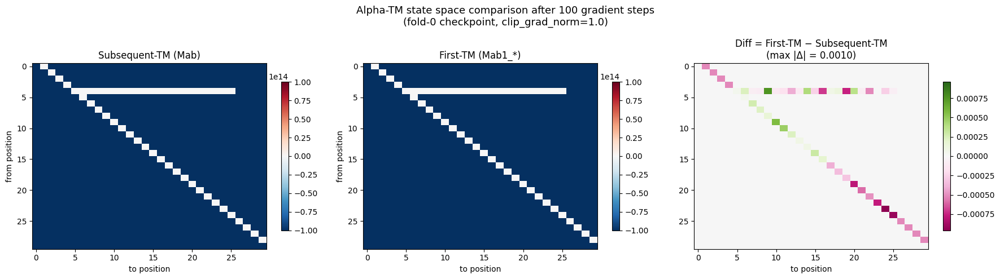

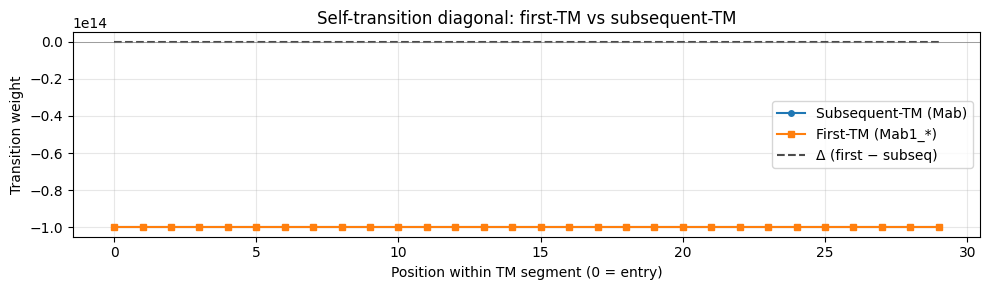

Mab  state indices : 19–48
Mab1 state indices : 137–166
Max |Δ| in 30×30 block : 0.000961
Mean |Δ| in 30×30 block: 0.000020
RMS  Δ  in 30×30 block : 0.000104


In [14]:
# ── Symmetry breaking: original vs first-TM alpha state spaces ───────────────
# After N gradient steps, do the Mab1_* (first-TM) transitions differ from
# the Mab* (subsequent-TM) transitions?  At init they are exact copies.
# Any divergence = the model has begun specialising the first-TM component.

import sys, torch, importlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
sys.path.insert(0, "/Users/olwi/git/DeepTM")

import deeptm.utils.crf_config.crf_config_with_tp_split_io as _crf_mod
importlib.reload(_crf_mod)
from deeptm.utils.crf_config.crf_config_with_tp_split_io import SplitIOCRFwithTPConfig

INFER_CKPT   = "/Users/olwi/git/DeepTMHMM2/checkpoints/topology_0.ckpt"
FTUNE_CKPT   = "/Users/olwi/git/DeepTM/outputs/finetune_local/finetune_clip_100steps/epoch=0-step=100.ckpt"

infer_ckpt = torch.load(INFER_CKPT, map_location="cpu", weights_only=False)
ft_ckpt    = torch.load(FTUNE_CKPT, map_location="cpu", weights_only=False)

# Build extended config to get state-index mapping
orig_cfg = ft_ckpt["hyper_parameters"]["crf_config"]
ext_cfg  = SplitIOCRFwithTPConfig(
    type_label_to_int=orig_cfg.type_label_to_int,
    maximum_segment_lengths=orig_cfg.max_segment_lengths,
    minimum_segment_lengths=orig_cfg.min_segment_lengths,
    use_start_end_transitions=orig_cfg.use_start_end_transitions,
    extend_first_tm=True,
)

states = ext_cfg.crf_states
# Original alpha-TM states: Mab0..Mab29 → indices 19–48
mab_idx  = sorted([v for k, v in states.items() if "Mab" in k and "_" not in k])
# First-TM alpha states: Mab1_0..Mab1_29 → indices 137–166
mab1_idx = sorted([v for k, v in states.items() if "Mab1_" in k])

T_ft   = ft_ckpt["state_dict"]["model.crf.transitions"].numpy()   # 197×197

# Also build the *initial* extended-grammar transitions by loading via
# make_extended_lightning_model (or equivalently: we know Mab1 was copied
# from Mab at init, so the init sub-matrix = the finetuned's Mab block BEFORE
# any gradient step — the inference checkpoint's Mab rows give us that).
# We use the inference ckpt's transition matrix for the original Mab block.
T_orig_135 = infer_ckpt["state_dict"]["model.crf.transitions"].numpy()  # 135×135

# Transition sub-matrices: rows = from-state, cols = to-state (within the block)
T_mab     = T_ft[np.ix_(mab_idx,  mab_idx)]   # 30×30, subsequent-TM block
T_mab1    = T_ft[np.ix_(mab1_idx, mab1_idx)]  # 30×30, first-TM block
T_diff    = T_mab1 - T_mab                     # divergence after finetuning

# Also look at the diagonal (self-transitions are the dominant signal)
diag_mab  = np.diag(T_mab)
diag_mab1 = np.diag(T_mab1)

n = len(mab_idx)  # 30
labels = [f"pos{i}" for i in range(n)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Colour scale for absolute matrices
vabs = max(abs(T_mab).max(), abs(T_mab1).max())

for ax, mat, title in zip(axes[:2],
                           [T_mab, T_mab1],
                           ["Subsequent-TM (Mab)", "First-TM (Mab1_*)"]):
    im = ax.imshow(mat, vmin=-vabs, vmax=vabs, cmap="RdBu_r", aspect="auto")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("to position"); ax.set_ylabel("from position")
    plt.colorbar(im, ax=ax, shrink=0.8)

# Difference matrix
vdiff = max(abs(T_diff).max(), 1e-6)
im = axes[2].imshow(T_diff, vmin=-vdiff, vmax=vdiff, cmap="PiYG", aspect="auto")
axes[2].set_title(f"Diff = First-TM − Subsequent-TM\n(max |Δ| = {vdiff:.4f})", fontsize=12)
axes[2].set_xlabel("to position")
plt.colorbar(im, ax=axes[2], shrink=0.8)

plt.suptitle(f"Alpha-TM state space comparison after {100} gradient steps\n"
             f"(fold-0 checkpoint, clip_grad_norm=1.0)", fontsize=13)
plt.tight_layout()
plt.show()

# Diagonal comparison (self-transition = tendency to stay inside TM segment)
fig2, ax2 = plt.subplots(figsize=(10, 3))
xs = np.arange(n)
ax2.plot(xs, diag_mab,  label="Subsequent-TM (Mab)",  marker="o", ms=4)
ax2.plot(xs, diag_mab1, label="First-TM (Mab1_*)",    marker="s", ms=4)
ax2.plot(xs, diag_mab1 - diag_mab, label="Δ (first − subseq)", color="black",
         linestyle="--", alpha=0.7)
ax2.axhline(0, color="grey", lw=0.5)
ax2.set_xlabel("Position within TM segment (0 = entry)")
ax2.set_ylabel("Transition weight")
ax2.set_title("Self-transition diagonal: first-TM vs subsequent-TM")
ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mab  state indices : {mab_idx[0]}–{mab_idx[-1]}")
print(f"Mab1 state indices : {mab1_idx[0]}–{mab1_idx[-1]}")
print(f"Max |Δ| in 30×30 block : {abs(T_diff).max():.6f}")
print(f"Mean |Δ| in 30×30 block: {abs(T_diff).mean():.6f}")
print(f"RMS  Δ  in 30×30 block : {np.sqrt((T_diff**2).mean()):.6f}")


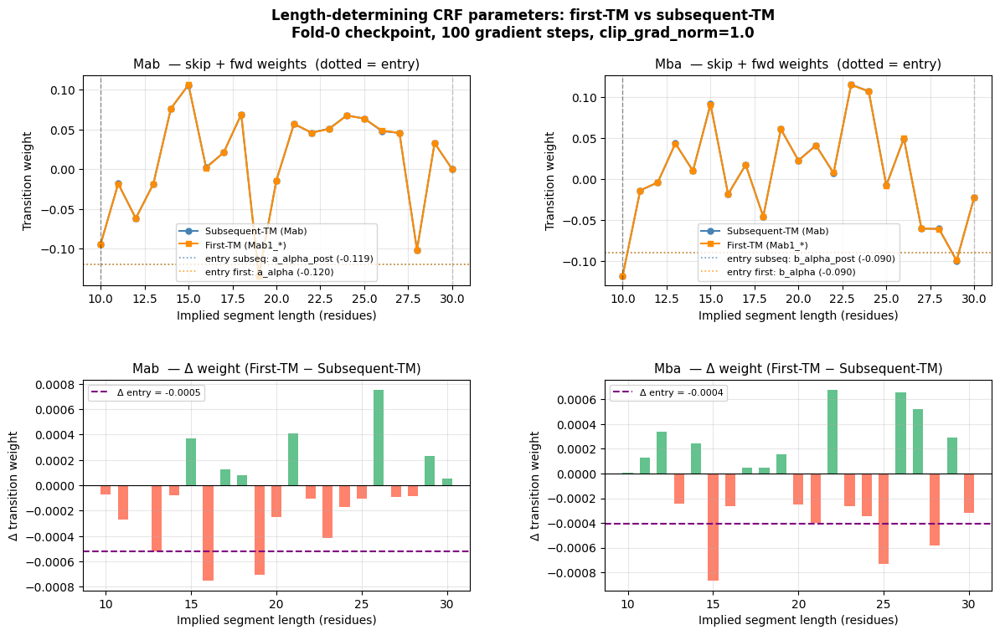

In [16]:
# ── Length-determining parameters: Mab vs Mab1_* after 100 gradient steps ────
# Same structure as cell 49 but uses the finetuned checkpoint (fold 0, 100 steps)
# and overlays the two alpha-TM components on the same axes.
# Bottom row: difference (Mab1_* − Mab) so small divergences are readable.
#
# Extended grammar entry states:
#   first-TM  :  a_alpha      → Mab1_0  /  b_alpha      → Mba1_0
#   subsequent:  a_alpha_post → Mab0    /  b_alpha_post → Mba0

import sys, torch, importlib, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, "/Users/olwi/git/DeepTM")

import deeptm.utils.crf_config.crf_config_with_tp_split_io as _crf_mod
importlib.reload(_crf_mod)
from deeptm.utils.crf_config.crf_config_with_tp_split_io import SplitIOCRFwithTPConfig

FTUNE_CKPT = "/Users/olwi/git/DeepTM/outputs/finetune_local/finetune_clip_100steps/epoch=0-step=100.ckpt"
ft_ckpt    = torch.load(FTUNE_CKPT, map_location="cpu", weights_only=False)

orig_cfg = ft_ckpt["hyper_parameters"]["crf_config"]
ext_cfg  = SplitIOCRFwithTPConfig(
    type_label_to_int=orig_cfg.type_label_to_int,
    maximum_segment_lengths=orig_cfg.max_segment_lengths,
    minimum_segment_lengths=orig_cfg.min_segment_lengths,
    use_start_end_transitions=orig_cfg.use_start_end_transitions,
    extend_first_tm=True,
)
T  = ft_ckpt["state_dict"]["model.crf.transitions"].numpy()  # 197×197
st = ext_cfg.crf_states   # name → index

# Entry states differ between first-TM and subsequent-TM in the extended grammar
ENTRY_FIRST  = {'Mab': 'a_alpha',      'Mba': 'b_alpha'}
ENTRY_SUBSEQ = {'Mab': 'a_alpha_post', 'Mba': 'b_alpha_post'}

def get_length_weights(T, cfg, tm_type, suffix=""):
    """Return (lengths, skip_weights, entry_weight) for a TM component.
    suffix=""   → subsequent-TM (Mab);  entry from a_alpha_post
    suffix="1_" → first-TM     (Mab1_); entry from a_alpha
    """
    min_seg   = cfg.min_segment_lengths[tm_type]
    max_seg   = cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)

    key = lambda pos: f"{tm_type}{suffix}{pos}"

    skip_src = st[key(start_seg - 1)]
    fwd_dst  = st[key(start_seg)]

    entry_state = ENTRY_FIRST[tm_type] if suffix == "1_" else ENTRY_SUBSEQ[tm_type]
    entry_src = st[entry_state]
    entry_dst = st[key(0)]

    js      = list(range(max_seg - end_seg, start_seg, -1))
    lengths = [start_seg + (max_seg - j) for j in js]
    js.append(start_seg)
    lengths.append(max_seg)

    weights = []
    for j in js[:-1]:
        weights.append(T[skip_src, st[key(j)]].item())
    weights.append(T[skip_src, fwd_dst].item())

    entry_w = T[entry_src, entry_dst].item()
    return lengths, weights, entry_w

fig, axes = plt.subplots(2, 2, figsize=(14, 8),
                         gridspec_kw={"hspace": 0.45, "wspace": 0.35})

for col, tm_type in enumerate(['Mab', 'Mba']):
    ax_top  = axes[0, col]
    ax_diff = axes[1, col]

    lengths,  w_subseq, entry_subseq = get_length_weights(T, ext_cfg, tm_type, suffix="")
    lengths1, w_first,  entry_first  = get_length_weights(T, ext_cfg, tm_type, suffix="1_")

    # Top panel: both components
    ax_top.plot(lengths,  w_subseq, marker='o', ms=5, lw=1.5, label='Subsequent-TM (Mab)',  color='steelblue')
    ax_top.plot(lengths1, w_first,  marker='s', ms=5, lw=1.5, label='First-TM (Mab1_*)',    color='darkorange')
    ax_top.axhline(entry_subseq, color='steelblue',  lw=1.2, ls=':', alpha=0.8,
                   label=f'entry subseq: {ENTRY_SUBSEQ[tm_type]} ({entry_subseq:.3f})')
    ax_top.axhline(entry_first,  color='darkorange', lw=1.2, ls=':', alpha=0.8,
                   label=f'entry first: {ENTRY_FIRST[tm_type]} ({entry_first:.3f})')

    min_seg = ext_cfg.min_segment_lengths[tm_type]
    max_seg = ext_cfg.max_segment_lengths[tm_type]
    ax_top.axvline(min_seg, color='black', lw=1, ls='--', alpha=0.4)
    ax_top.axvline(max_seg, color='gray',  lw=1, ls='--', alpha=0.4)
    ax_top.set_title(f'{tm_type}  — skip + fwd weights  (dotted = entry)', fontsize=11)
    ax_top.set_xlabel('Implied segment length (residues)')
    ax_top.set_ylabel('Transition weight')
    ax_top.legend(fontsize=8)
    ax_top.grid(alpha=0.3)

    # Bottom panel: difference (first − subsequent)
    diff = [f - s for f, s in zip(w_first, w_subseq)]
    ax_diff.bar(lengths, diff,
                color=['tomato' if d < 0 else 'mediumseagreen' for d in diff],
                alpha=0.8, width=0.6)
    ax_diff.axhline(0, color='black', lw=0.8)
    ax_diff.axhline(entry_first - entry_subseq, color='purple', lw=1.5, ls='--',
                    label=f'Δ entry = {entry_first - entry_subseq:.4f}')
    ax_diff.set_title(f'{tm_type}  — Δ weight (First-TM − Subsequent-TM)', fontsize=11)
    ax_diff.set_xlabel('Implied segment length (residues)')
    ax_diff.set_ylabel('Δ transition weight')
    ax_diff.legend(fontsize=8)
    ax_diff.grid(alpha=0.3)

fig.suptitle(
    'Length-determining CRF parameters: first-TM vs subsequent-TM\n'
    'Fold-0 checkpoint, 100 gradient steps, clip_grad_norm=1.0',
    fontweight='bold', fontsize=12,
)
plt.show()


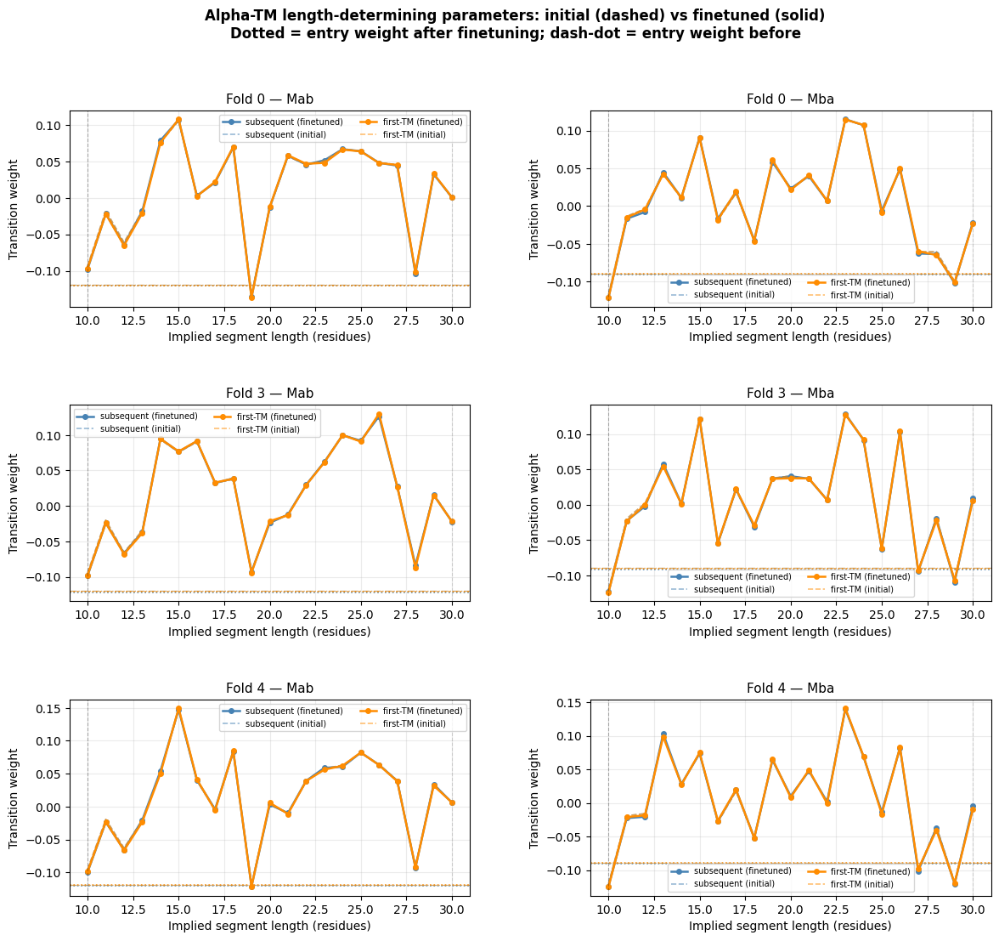

In [18]:
# ── Alpha-TM state space change: initial → finetuned (folds 0, 3, 4) ──────────
# Shows how much the length-determining transitions moved after 1 epoch of
# finetuning, for the three non-NaN folds.
# Left col = Mab (a→b orientation), right col = Mba (b→a orientation).
# Each fold gets its own row.  Solid = finetuned, dashed = initial (inference ckpt).
# Dotted horizontal lines = entry weights before and after.

import sys, torch, importlib, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, "/Users/olwi/git/DeepTM")
import deeptm.utils.crf_config.crf_config_with_tp_split_io as _crf_mod
importlib.reload(_crf_mod)
from deeptm.utils.crf_config.crf_config_with_tp_split_io import SplitIOCRFwithTPConfig

INFER_DIR  = "/Users/olwi/git/DeepTMHMM2/checkpoints"
FTUNE_DIR  = "/Users/olwi/git/DeepTM/outputs/finetune_local"

GOOD_FOLDS = {
    0: f"{FTUNE_DIR}/finetune_ext_fold0/epoch=0-step=630.ckpt",
    3: f"{FTUNE_DIR}/finetune_ext_fold3/epoch=0-step=623.ckpt",
    4: f"{FTUNE_DIR}/finetune_ext_fold4/epoch=0-step=652.ckpt",
}

ENTRY_FIRST  = {'Mab': 'a_alpha',      'Mba': 'b_alpha'}
ENTRY_SUBSEQ = {'Mab': 'a_alpha_post', 'Mba': 'b_alpha_post'}

def get_ext_cfg(ft_ckpt):
    orig_cfg = ft_ckpt["hyper_parameters"]["crf_config"]
    return SplitIOCRFwithTPConfig(
        type_label_to_int=orig_cfg.type_label_to_int,
        maximum_segment_lengths=orig_cfg.max_segment_lengths,
        minimum_segment_lengths=orig_cfg.min_segment_lengths,
        use_start_end_transitions=orig_cfg.use_start_end_transitions,
        extend_first_tm=True,
    )

def length_weights(T, ext_cfg, tm_type, suffix=""):
    st = ext_cfg.crf_states
    min_seg   = ext_cfg.min_segment_lengths[tm_type]
    max_seg   = ext_cfg.max_segment_lengths[tm_type]
    start_seg = math.ceil(min_seg / 2)
    end_seg   = math.floor(min_seg / 2)
    key       = lambda pos: f"{tm_type}{suffix}{pos}"
    skip_src  = st[key(start_seg - 1)]
    fwd_dst   = st[key(start_seg)]
    entry_src = st[ENTRY_FIRST[tm_type] if suffix == "1_" else ENTRY_SUBSEQ[tm_type]]
    entry_dst = st[key(0)]
    js      = list(range(max_seg - end_seg, start_seg, -1)) + [start_seg]
    lengths = [start_seg + (max_seg - j) for j in js[:-1]] + [max_seg]
    weights = [T[skip_src, st[key(j)]].item() for j in js[:-1]]
    weights.append(T[skip_src, fwd_dst].item())
    entry_w = T[entry_src, entry_dst].item()
    return lengths, weights, entry_w

fig, axes = plt.subplots(len(GOOD_FOLDS), 2, figsize=(14, 4 * len(GOOD_FOLDS)),
                         gridspec_kw={"hspace": 0.5, "wspace": 0.3})

for row, (fold, ft_path) in enumerate(GOOD_FOLDS.items()):
    ft_ckpt    = torch.load(ft_path,                                              map_location="cpu", weights_only=False)
    infer_ckpt = torch.load(f"{INFER_DIR}/topology_{fold}.ckpt",                 map_location="cpu", weights_only=False)
    ext_cfg    = get_ext_cfg(ft_ckpt)

    T_ft    = ft_ckpt["state_dict"]["model.crf.transitions"].numpy()
    # Initial extended transitions: make_extended_lightning_model copied Mab1_*
    # from Mab, so initial Mab1_* == Mab from the inference ckpt.
    # We reconstruct the full 197-state initial matrix by noting that the
    # finetuned Mab block itself also changed — so we reload the inference ckpt
    # weights through the same extension map.  The cleanest proxy for the
    # *initial* finetuned matrix is to load it via make_extended_lightning_model.
    from deeptm.utils.extended_grammar import make_extended_lightning_model
    from deeptm.utils.crf_config.crf_config_with_tp_split_io import SplitIOCRFwithTPConfig as _SC
    orig_cfg_pkl = ft_ckpt["hyper_parameters"]["crf_config"]
    original_cfg = _SC(
        type_label_to_int=orig_cfg_pkl.type_label_to_int,
        maximum_segment_lengths=orig_cfg_pkl.max_segment_lengths,
        minimum_segment_lengths=orig_cfg_pkl.min_segment_lengths,
        use_start_end_transitions=orig_cfg_pkl.use_start_end_transitions,
        extend_first_tm=False,
    )
    init_model = make_extended_lightning_model(
        f"{INFER_DIR}/topology_{fold}.ckpt", ext_cfg, original_cfg
    )
    T_init = dict(init_model.named_parameters())["model.crf.transitions"].detach().numpy()

    for col, tm_type in enumerate(["Mab", "Mba"]):
        ax = axes[row, col]

        for suffix, label_sfx, color in [("",   "subsequent", "steelblue"),
                                          ("1_", "first-TM",   "darkorange")]:
            l_ft,   w_ft,   e_ft   = length_weights(T_ft,   ext_cfg, tm_type, suffix)
            l_init, w_init, e_init = length_weights(T_init, ext_cfg, tm_type, suffix)

            ax.plot(l_ft,   w_ft,   color=color, lw=1.8, marker='o', ms=4,
                    label=f"{label_sfx} (finetuned)")
            ax.plot(l_init, w_init, color=color, lw=1.2, marker='', ls='--', alpha=0.55,
                    label=f"{label_sfx} (initial)")
            ax.axhline(e_ft,   color=color, lw=1.2, ls=':',  alpha=0.9)
            ax.axhline(e_init, color=color, lw=0.9, ls='-.', alpha=0.5)

        min_seg = ext_cfg.min_segment_lengths[tm_type]
        max_seg = ext_cfg.max_segment_lengths[tm_type]
        ax.axvline(min_seg, color='black', lw=0.8, ls='--', alpha=0.3)
        ax.axvline(max_seg, color='gray',  lw=0.8, ls='--', alpha=0.3)
        ax.set_title(f"Fold {fold} — {tm_type}", fontsize=11)
        ax.set_xlabel("Implied segment length (residues)")
        ax.set_ylabel("Transition weight")
        ax.legend(fontsize=7, ncol=2)
        ax.grid(alpha=0.25)

fig.suptitle(
    "Alpha-TM length-determining parameters: initial (dashed) vs finetuned (solid)\n"
    "Dotted = entry weight after finetuning; dash-dot = entry weight before",
    fontweight="bold", fontsize=12,
)
plt.show()
